In [38]:
from classes import *
from functions import *
from utils import *
from metrics import *
import seaborn as sns
import statsmodels.tsa as sm
import statsmodels.api as sma
import matplotlib.pyplot as plt
import pickle
import warnings
%load_ext autoreload
%autoreload 2
pd.set_option('display.max_columns', None)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Storing Results : convergence of the algorithm
On lance $p$ fois l'algorithme, à chaque fois on regénère des données au préalable (sinon tout est déterministe)

In [32]:
sample_size = 4000
true_params =  {'alpha':np.array([[0.2,0.8]]),\
                'P': np.array([[0.8,0.2],[0.1,0.9]]),\
                'omega':np.array([0.2,0.8]),\
                #'exogen_transition' : np.random.uniform(0,1,size=(sample_size)),\
                'beta' : np.array([[-0.1,0.1],[0.5,-0.5]]),\
                #'mu' : np.array([1,0.1]),\
                #'exogen_additive' : abs(AR([0.9,0.08],length=sample_size*2)).reshape(sample_size,2),\
                'exogen_transition' : AR([0.9,0.08],length=sample_size),\
                'transition_f' : 'soft-exp',\
                #'seed' : 3,\
                    }

initial_params =    {'pi_0' : np.array([0.5,0.5]),\
                    'omega' : np.array([0.5,0.5]),\
                    'P' : np.ones((2,2))/2,\
                    'alpha' : np.array([[0,0]]),\
                    #'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    'transition_f' : 'soft-exp',\
                    #'beta' : np.array([0,1]),\
                    'beta' : np.array([[0,0],[0,0]]),\
                    'beta_constraint' : 'general'
                    #'mu' : np.array([0.5,0.5]),\
                    }



niter = 300
p = 100


def run_simulation(true_params, initial_params, sample_size, niter):
    model = MS_ARCH(true_params=true_params)
    model.simulate(length=sample_size)
    results = MS_EM_algorithm(model.eps,initial_params,niter)
    return results

In [17]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for sample_size in [4000]:
        store_results = {}
        p = 300
        for i in tqdm(range(p)):
            store_results[i+1] = run_simulation(true_params.copy(), initial_params.copy(), sample_size, niter)
        store_results['true_params'] = true_params
        with open(f"Results//results_{sample_size}"+".pkl", "wb") as f:
            pickle.dump(store_results, f)

100%|██████████| 100/100 [1:49:20<00:00, 65.61s/it]


### Calibration de la Value-At-Risk
L'objectif ici est de calculer la $VaR_t^X(\alpha)$, définie par $VaR_t^X(\alpha) = -\inf\{z_t|P_{t-1}(X_t\leq z_t)\geq\alpha\}$.

Au sein d'un régime $GARCH$ gaussien, on a que $X_t|\mathcal{F}_{t-1}$ suit une loi Gaussienne centrée de variance $\sigma_t^2$, on en déduit que le quantile d'ordre $\alpha$ de $X_t$ correspond au quantile d'ordre $\alpha$ de $\mathcal{N}(0,\sigma_t^2)$, on a directement (quelle que soit la loi de $\eta$), $VaR_t^X(\alpha) := -\xi_{\alpha}(\sigma_t\eta_t|\mathcal{F_{t-1}}) = -\sigma_t\xi_{\alpha}(\eta)$ (car $\sigma_t$ est $\mathcal{F}_{t-1}$-mesurable). (la notation de quantile conditionnelle est la mienne, vaut peut-être rien).

In [ ]:
alpha_true,P_true,omega_true,_ = true_params.values()
pi_0 = initial_params['pi_0']

In [ ]:
Vars = get_var_gaussian(model.eps, np.arange(1,len(model.eps)+1), omega_true, alpha_true, P_true, pi_0, level=0.05)

In [ ]:
(pd.DataFrame(Vars,index=['VaR']).T)[:].plot(figsize=(30,10))

## Ajout de Variables Exogènes
Ici on va tenter de coder le bail de sorte à ce qu'on puisse choisir les paramètres selon lesquels calibrer, les paramètres seront tous récupérés dans un dictionnaire, si None ils ne seront pas utilisés, sinon ils le seront, on dénote les paramètres suivants:
- Exogen_additive -> OK
- mu (par défaut [0]*Exogen_additive.shape[1]) -> OK
- mu_depends_on_delta (binaire) -> OK
- Exogen_transition -> OK
- Exogen_transition_beta (=[0]*d par défaut) -> OK
- pi_0 -> OK
- omega -> OK
- P -> OK
- alpha -> OK
- eps (pas un paramètre mais il faut le garder en mémoire) -> OK

Il faudra apporter les modifications suivantes:
- Si exogen_additive, calibrer lambda -> OK
- probablement mettre exogen en dimension (a,b) (même (3000,1)) si univarié, pour pouvoir gérer tous les cas -> OK
- Si exogen_transition (is not None): passer d'une formule fermée à une optimisation pour les probabilités de transition ET calibrer les beta -> TODO
- Ajouter des contraintes : positivité pour les lambda, somme à 0 pour les beta -> TODO
- Si exogen_transition (is not None): réécrire le filtre d'Hamilton, se fait peut-être simplement par un get_proba(p,X) -> OK

Il faut s'attendre aux problèmes suivants:
- que faire d'un dico pour njit? besoin d'unwrap tout ça? peut-être mettre dico.items() et dico.keys() en arguments de chaque fonction -> OK

Fonctions à créer:
- Si exogen_transition, une fonction get_proba(p,exogen_transition,exogen_transition_f) (attention aux indices) -> OK
- Si exogen_transition, une fonction get_a3 (la somme des log probas et tout) -> TODO


Fonctions à modifier:
- Hamilton_filter : rajouter un P = get_proba(P,...) -> OK
- De manière générale à chaque utilisation d'un P faire attention à ça -> OK
- Fonction get_sigma (et tout ce qui est get_phi et tout) : rajouter le lambda devant exogen -> OK
- Rajouter le lambda dans get_a1 et l'inclure dans l'optimisation -> OK
- En profiter pour réécrire le dico true_params c'est juste pas sérieux -> OK

Classes à modifier:
- Intégrer les deux cas dans la classe MS-ARCH -> OK

TODO supplémentaire:
- exogen_transition
- Rajouter log-likelihood (pour l'instant pas pressé)
- Graphiques pour convergence asymptotique (pas compliqué, juste récupérer gros df avec le cas de figure en indice et itération en colonne pour groupby)
- Passage à VaR
- Simulation sigma conditionnel avec mes params -> OK

In [61]:
np.random.seed(5)
sample_size = 10000
true_params =  {'alpha':np.array([[0.2,0.4],[0.8,0.1]]),\
               'P': np.array([[0.98,0.02],[0.01,0.99]]),\
               'omega':np.array([0.2,0.8]),\
               #'exogen_transition' : np.random.uniform(0,1,size=(sample_size)).reshape(-1,1),\
               'beta' : np.array([[[-0.1,0],[0.1,0]],[[0.5,0],[-0.5,0]]]).reshape(2,2,2),\
               'mu' : np.array([[0.4,0],[0,0.5]]),\
               'exogen_additive' : abs(AR([0.9,0.08],length=sample_size*2)).reshape(sample_size,2),\
               'exogen_transition' : AR([0.9,0.08],length=sample_size*2).reshape(sample_size,2),\
               'transition_f' : 'soft-exp',\
               #'seed' : 5,\
                "pi_0":np.array([0.5,0.5])}


initial_params =    {'pi_0' : np.array([0.5,0.5]),\
                    'omega' : np.array([0.3,0.7]),\
                    'P' : np.ones((2,2))/2,\
                    'alpha' : np.array([[0,0],[0,0]]),\
                    'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    #'transition_f' : 'soft-exp',\
                    'beta' : np.zeros((2,2,2)),\
                    'beta_constraint' : 'general',\
                    'mu' : np.array([[0,0],[0,0]]),
                    'lambda' : 1000\
                         }

model = MS_ARCH(true_params=true_params)
model.simulate(length=sample_size)
true_params['log-likelihood'] = compute_log_likelihood(model.eps,true_params)

In [42]:
initial_params['pi_0']

array([0.5, 0.5])

In [54]:
from copy import deepcopy

In [62]:
Lambdas = [0,*np.logspace(-4,1,num=10)]
store = {}
for lambda_ in tqdm(Lambdas):
    initial_params['lambda'] = lambda_
    r = MS_EM_algorithm(model.eps,initial_params,niter=1000)
    store[lambda_] = deepcopy(r)

  0%|          | 0/11 [00:00<?, ?it/s]

mu of dimension 2: will depend on delta


/Users/raphaelthabut/Desktop/Documents Professionnels/Thèse Zakoian/GitHub/functions.py:46: RuntimeWarning: invalid value encountered in divide
  pi[t, t] /= pi[t, t].sum()  # Normalisation
  9%|▉         | 1/11 [14:09<2:21:30, 849.05s/it]

mu of dimension 2: will depend on delta


/Users/raphaelthabut/Desktop/Documents Professionnels/Thèse Zakoian/GitHub/functions.py:46: RuntimeWarning: invalid value encountered in divide
  pi[t, t] /= pi[t, t].sum()  # Normalisation
 18%|█▊        | 2/11 [27:49<2:04:51, 832.34s/it]

mu of dimension 2: will depend on delta


... (13 outputs left out)

mu of dimension 2: will depend on delta


/Users/raphaelthabut/Desktop/Documents Professionnels/Thèse Zakoian/GitHub/functions.py:46: RuntimeWarning: invalid value encountered in divide
  pi[t, t] /= pi[t, t].sum()  # Normalisation
 91%|█████████ | 10/11 [2:17:33<13:47, 827.54s/it]

mu of dimension 2: will depend on delta


/Users/raphaelthabut/Desktop/Documents Professionnels/Thèse Zakoian/GitHub/functions.py:46: RuntimeWarning: invalid value encountered in divide
  pi[t, t] /= pi[t, t].sum()  # Normalisation
100%|██████████| 11/11 [2:30:55<00:00, 823.25s/it]


In [64]:
for lambda_, r in store.items():
    print(r[0]['lambda'],r[1000]['beta'],r[1000]['mu'])

0 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
0.0001 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
0.00035938136638046257 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
0.001291549665014884 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
0.004641588833612782 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
0.016681005372000592 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
0.05994842503189409 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
0.21544346900318845 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
0.7742636826811278 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
2.782559402207126 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]
10.0 [[[0. 0.]
  [0. 0.]]

 [[0. 0.]
  [0. 0.]]] [[0. 0.]
 [0. 0.]]


In [38]:
r[2]

{'P': array([[0.48062393, 0.51937607],
        [0.46684415, 0.53315585]]),
 'beta': array([[[-0.00283754],
         [ 0.00283754]],
 
        [[-0.00461153],
         [ 0.00461153]]]),
 'omega': array([0.18501394, 0.6796447 ]),
 'alpha': array([[0.19066656, 0.31676715],
        [0.29994776, 0.6868289 ]]),
 'mu': array([[0.32402042, 0.28026213],
        [0.39922141, 0.18999081]]),
 'pi_0': array([0.73969185, 0.26030815]),
 'log-likelihood': -23226.6529447155}

In [39]:
r = MS_EM_algorithm(model.eps,initial_params,niter=2)

mu of dimension 2: will depend on delta


  0%|          | 0/2 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
100%|██████████| 2/2 [00:01<00:00,  1.05it/s]


In [40]:
r[2]

{'P': array([[0.5, 0.5],
        [0.5, 0.5]]),
 'beta': array([[[-1.69029316e-09],
         [ 1.69029316e-09]],
 
        [[-1.69029316e-09],
         [ 1.69029316e-09]]]),
 'omega': array([2.18793124, 2.34271555]),
 'alpha': array([[0.26723153, 0.34222163],
        [0.40701734, 0.68299802]]),
 'mu': array([[0., 0.],
        [0., 0.]]),
 'pi_0': array([0.60651489, 0.39348511]),
 'log-likelihood': -23549.702279520243}

In [ ]:
r[2]

{'P': array([[0.48062439, 0.51937561],
        [0.46684455, 0.53315545]]),
 'beta': array([[-0.00283633,  0.00283633],
        [-0.00460972,  0.00460972]]),
 'omega': array([0.18492833, 0.68015447]),
 'alpha': array([[0.19051263, 0.31679685],
        [0.29998684, 0.68672864]]),
 'mu': array([[0.32411986, 0.28092468],
        [0.39917902, 0.18915077]]),
 'pi_0': array([0.73969185, 0.26030815]),
 'log-likelihood': -23226.654066020317}

## Repartition of States

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_su

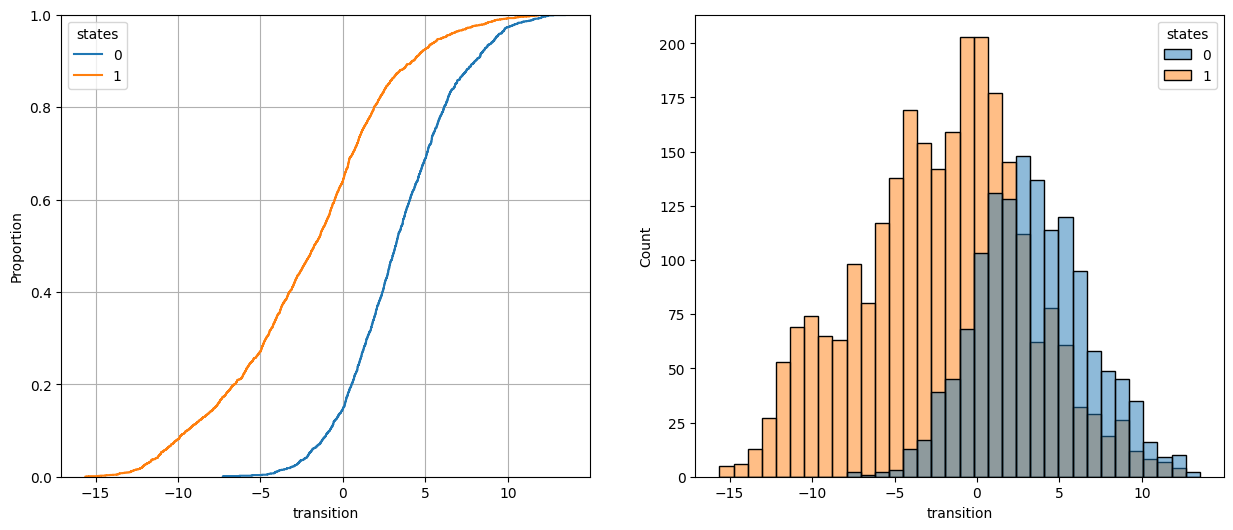

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


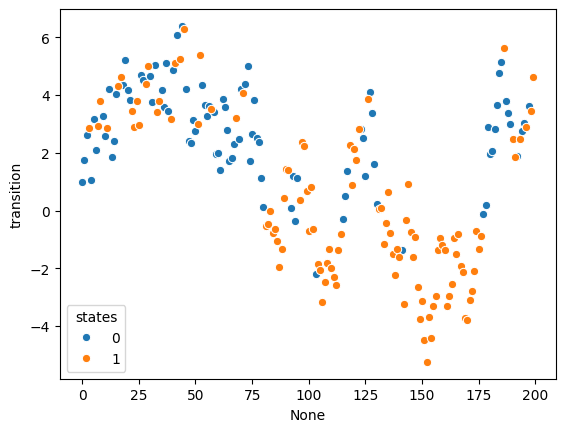

In [15]:
cc = pd.DataFrame({'transition':model.exogen_transition,'states':model.states})

fig,axs = plt.subplots(1,2,figsize=(15,6))

sns.ecdfplot(data=cc,x='transition',hue='states',ax=axs[0])
axs[0].grid()
sns.histplot(data=cc,x='transition',hue='states',ax=axs[1])
plt.show()
sns.lineplot(data=cc.iloc[:200],y='transition',x=cc.index[:200],hue='states',marker='o',linestyle='')
plt.show()

In [16]:
cc2 = pd.DataFrame({'transition':model.exogen_transition,'states':pi[:,-1,:].argmax(axis=1)[1:]})

fig,axs = plt.subplots(1,2,figsize=(15,6))

sns.ecdfplot(data=cc2,x='transition',hue='states',ax=axs[0])
axs[0].grid()
sns.histplot(data=cc2,x='transition',hue='states',ax=axs[1])
plt.show()
sns.lineplot(data=cc2.iloc[:200],y='transition',x=cc2.index[:200],hue='states',marker='o',linestyle='')

NameError: name 'pi' is not defined

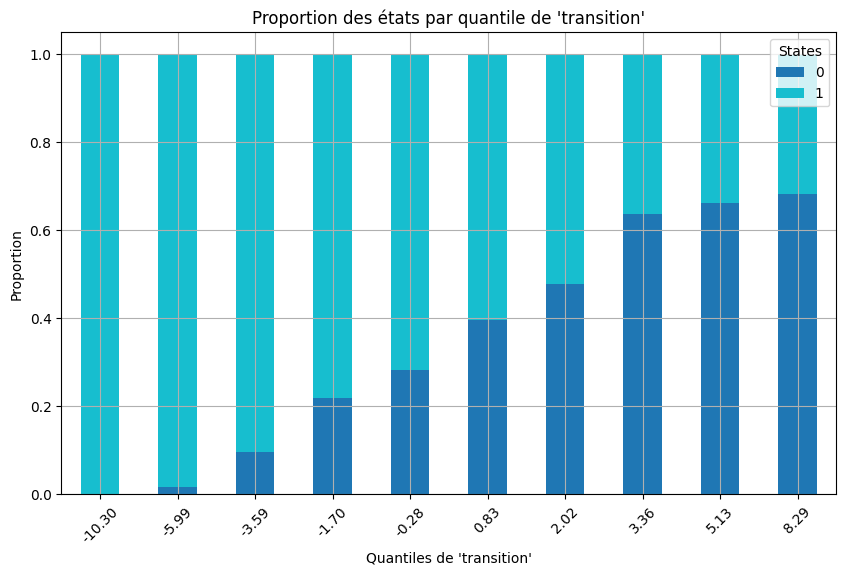

In [17]:
# Définir les quantiles pour la colonne 'transition'
cc['quantile'] = pd.qcut(cc['transition'], q=10, labels=False)

# Calculer les proportions de 'states' pour chaque quantile
quantile_stats = cc.groupby('quantile')['states'].value_counts(normalize=True).unstack()

mean_transition_values = cc.groupby('quantile')['transition'].mean()

# Création du barplot cumulé
ax = quantile_stats.plot(kind='bar', stacked=True, figsize=(10, 6), colormap="tab10")

# Ajuster les labels en abscisse pour afficher les moyennes des quantiles
ax.set_xticks(range(len(mean_transition_values)))
ax.set_xticklabels([f"{val:.2f}" for val in mean_transition_values], rotation=45)

# Ajouter des labels et des titres
plt.title("Proportion des états par quantile de 'transition'")
plt.xlabel("Quantiles de 'transition'")
plt.ylabel("Proportion")
plt.legend(title="States", loc="upper right")
plt.grid()
plt.show()

In [18]:
# Définir les quantiles pour la colonne 'transition'
cc2['quantile'] = pd.qcut(cc2['transition'], q=10, labels=False)

# Calculer les proportions de 'states' pour chaque quantile
quantile_stats = cc2.groupby('quantile')['states'].value_counts(normalize=True).unstack()

mean_transition_values = cc2.groupby('quantile')['transition'].mean()

# Création du barplot cumulé
ax = quantile_stats.plot(kind='bar', stacked=True, figsize=(10, 6), colormap="tab10")

# Ajuster les labels en abscisse pour afficher les moyennes des quantiles
ax.set_xticks(range(len(mean_transition_values)))
ax.set_xticklabels([f"{val:.2f}" for val in mean_transition_values], rotation=45)

# Ajouter des labels et des titres
plt.title("Proportion des états par quantile de 'transition'")
plt.xlabel("Quantiles de 'transition'")
plt.ylabel("Proportion")
plt.legend(title="States", loc="upper right")
plt.show()

NameError: name 'cc2' is not defined

## Visualising Convergence

In [1]:
results = copy(u)
results[0] = {key:value for key,value in results[0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive']}
#result_exogen[0].pop('mu_depends_on_delta')
df_exo = convert_dict_to_dataframe(results)

NameError: name 'copy' is not defined

#### Comparaison de deux modèles

NameError: name 'df_non_exo' is not defined

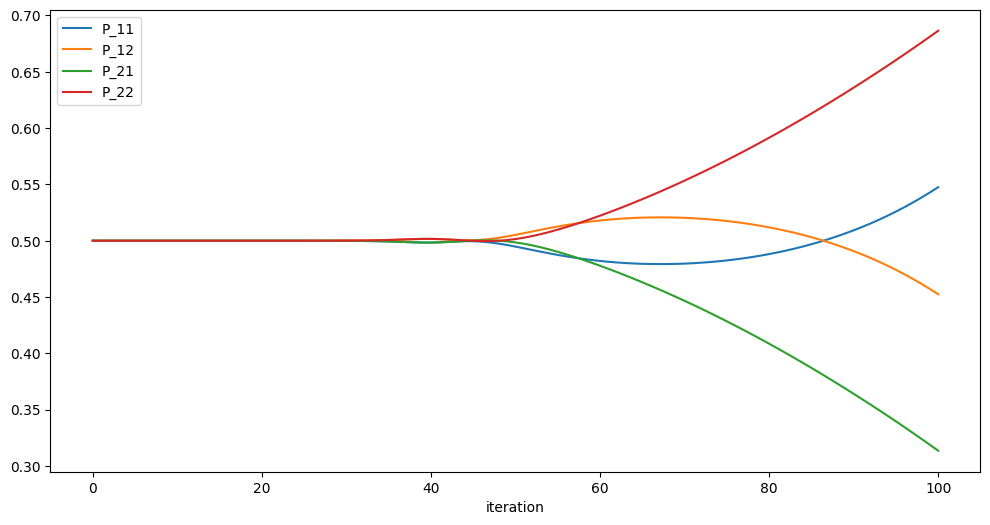

In [66]:
start = 'P'
ax = df_exo.plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6))
df_non_exo.plot(y=[col for col in df_non_exo.columns if col.startswith(start)],ax=ax,linestyle='--',grid=True)


In [ ]:
start = 'P'
ax = df_exo.plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6))
df_non_exo.plot(y=[col for col in df_non_exo.columns if col.startswith(start)],ax=ax,linestyle='--',grid=True)


In [ ]:
start = 'P'
ax = df_exo.plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6))
df_non_exo.plot(y=[col for col in df_non_exo.columns if col.startswith(start)],ax=ax,linestyle='--',grid=True)


In [ ]:
start = 'omega'
ax = df_exo.plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6),grid=True)
df_non_exo.plot(y=[col for col in df_non_exo.columns if col.startswith(start)],ax=ax,linestyle='--')

In [ ]:
start = 'omega'
ax = df_exo.plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6),grid=True)
df_non_exo.plot(y=[col for col in df_non_exo.columns if col.startswith(start)],ax=ax,linestyle='--')

In [ ]:
start = 'alpha'
ax = df_exo.plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6),grid=True)
df_non_exo.plot(y=[col for col in df_non_exo.columns if col.startswith(start)],ax=ax,linestyle='--')

In [ ]:
start = 'alpha'
ax = df_exo.plot(y=[col for col in df_exo.columns if col.startswith(start)],figsize=(12,6),grid=True)
df_non_exo.plot(y=[col for col in df_non_exo.columns if col.startswith(start)],ax=ax,linestyle='--')

In [141]:
name_params = ['P','beta','omega','alpha','pi_0']

### Comparaison d'un modèle avec les vraies valeurs
Pour effectuer une telle comparaison, il faut s'assurer de l'identifiabilité du modèle, par exemple en sortant les indices selon les omega

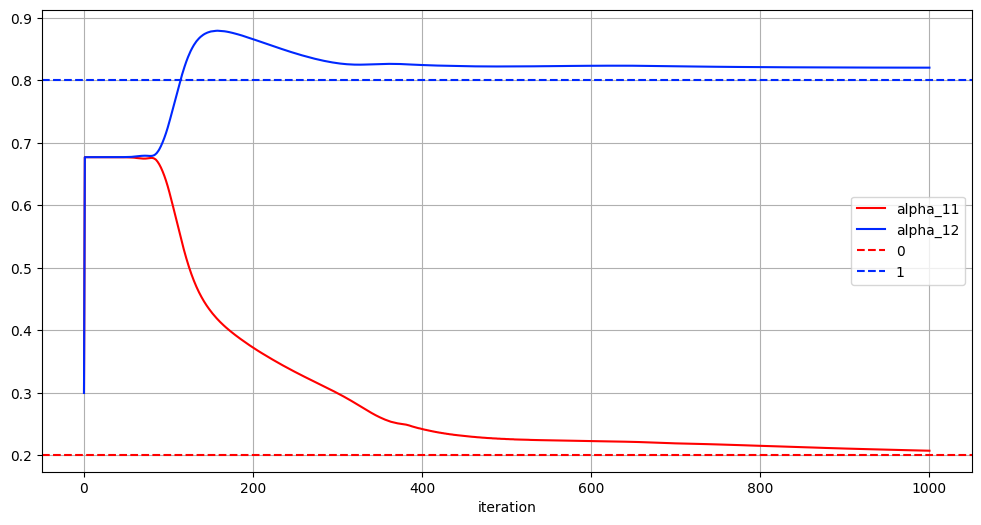

In [102]:
start = 'alpha'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()

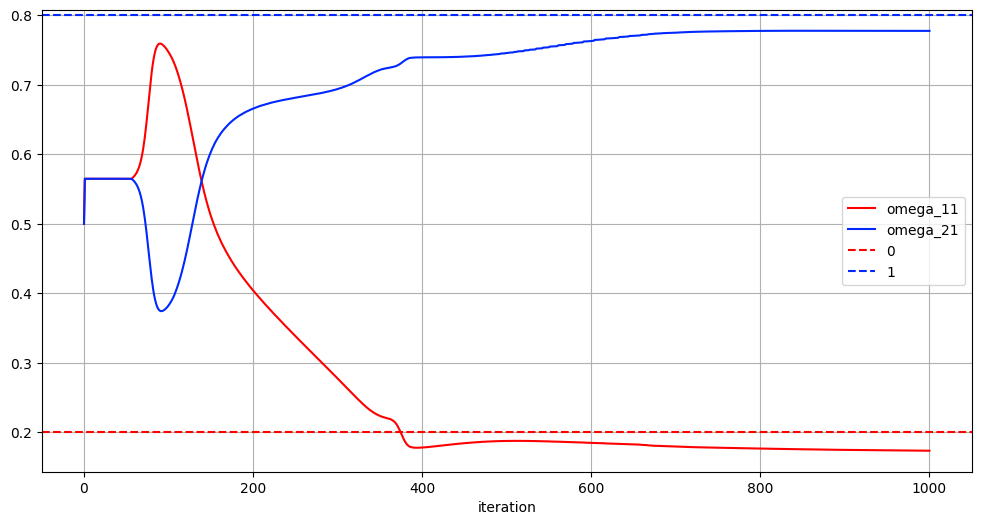

In [103]:
start = 'omega'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()

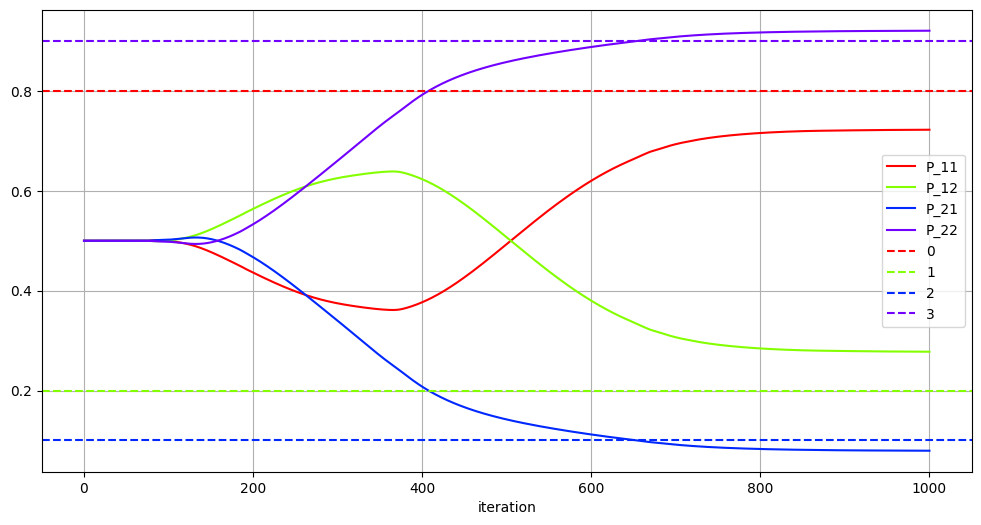

In [104]:
start = 'P'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()

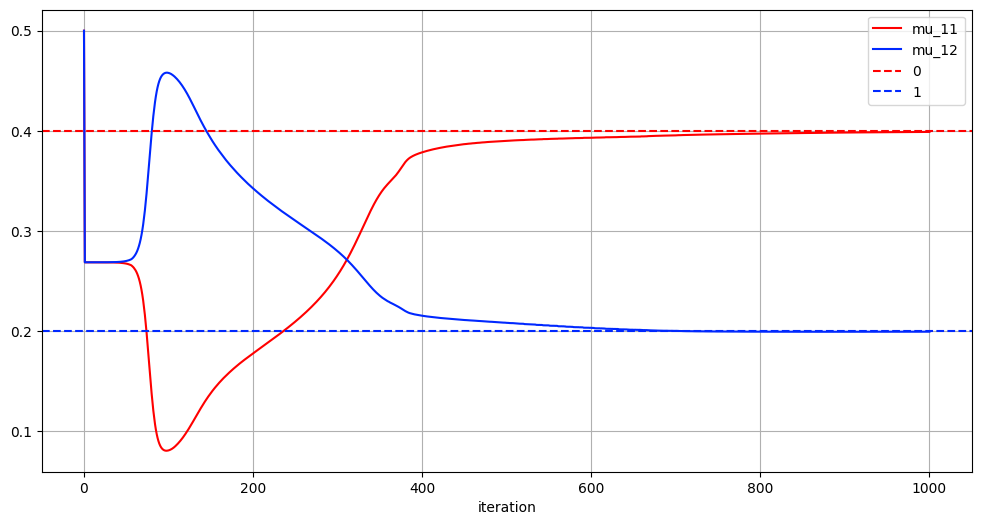

In [107]:
start = 'mu'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()

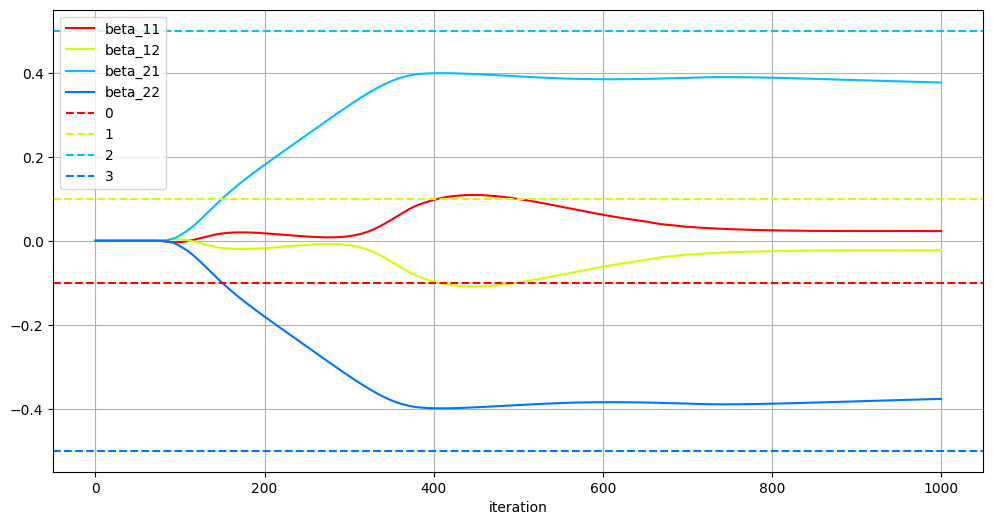

In [ ]:
start = 'beta'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()

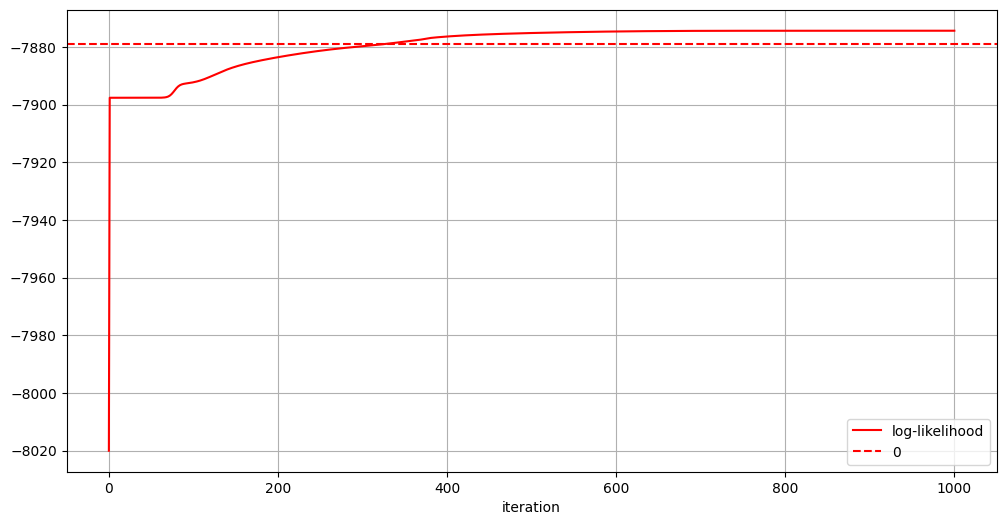

In [106]:
start = 'log-likelihood'
true_params['pi_0'] = np.array([1,0])
true_params['log-likelihood'] = np.array([compute_log_likelihood(model.eps,true_params)])
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()

### Conditional Sigma Trajectory
On peut retracer sigma conditionnelle donnée par $E(\sigma_t|X_1,..,X_{t-1},\epsilon_1,..,\epsilon_{t-1}) = \sum_{i=1}^dP(\Delta_t=i|\epsilon_1,..,\epsilon_{t-1},X_1,..,X_{t-1})\left(\omega(i)+\lambda(i)X_{t-1}+\sum_{j=1}^d\alpha(i)_j\epsilon_{t-i}^2\right)$

## TWO-STEP EM

##### 1. Pas de Variable Exogène

In [315]:
sample_size = 4000
true_params =  {'alpha':np.array([[0,0]]),\
                'P': np.array([[0.8,0.2],[0.1,0.9]]),\
                'omega':np.array([0.8,0.2]),\
                'pi_0' : np.array([0.5,0.5]),\
                #'exogen_transition' : np.random.uniform(0,1,size=(sample_size)),\
                #'beta' : np.array([-0.1,0.1]),\
                #'mu' : np.array([1,0.1]),\
                #'exogen_additive' : abs(AR([0.9,0.08],length=sample_size*2)).reshape(sample_size,2),\
                #'exogen_transition' : AR([0.9,0.08],length=sample_size),\
                'seed' : 3,\
                    }

initial_params =    {'pi_0' : np.array([0.5,0.5]),\
                    'omega' : np.array([0.25,0.75]),\
                    'P' : np.ones((2,2))/2,\
                    'alpha' : np.array([[0,0]]),\
                    #'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    #'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    #'beta' : np.array([0,0]),\
                    #'mu' : np.array([0.5,0.5]),\
                         }

model = MS_ARCH(true_params=true_params)
model.simulate(length=sample_size)

u2,pi2,evolution = MS_EM_algorithm_2_step(model.eps,true_params,niter=50,return_pi=True)

100%|██████████| 50/50 [00:05<00:00,  8.39it/s]


5.493029675562866e-08


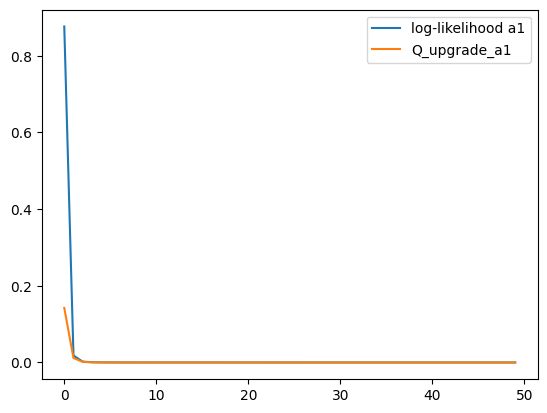

In [316]:
df = pd.DataFrame(evolution)
df.plot(y=['log-likelihood a1','Q_upgrade_a1'])
print((df['log-likelihood a1']-df['Q_upgrade_a1']).min())

1.0358660347264959e-06


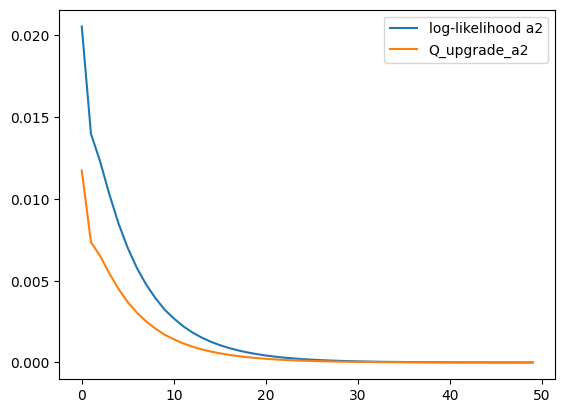

In [317]:
df = pd.DataFrame(evolution)
df.plot(y=['log-likelihood a2','Q_upgrade_a2'])
print((df['log-likelihood a2']-df['Q_upgrade_a2']).min())

Pour notre modèle sans variable exogène, on vérifie bien le critère de l'algorithme EM, à savoir $\Delta Q \leq \Delta \mathcal{L}$

##### 2. Variable Exogène additive

In [310]:
sample_size = 4000
true_params =  {'alpha':np.array([[0,0]]),\
                'P': np.array([[0.8,0.2],[0.1,0.9]]),\
                'omega':np.array([0.8,0.2]),\
                #'exogen_transition' : np.random.uniform(0,1,size=(sample_size)),\
                #'beta' : np.array([-0.1,0.1]),\
                'mu' : np.array([1,0.1]),\
                'exogen_additive' : abs(AR([0.9,0.08],length=sample_size*2)).reshape(sample_size,2),\
                #'exogen_transition' : AR([0.9,0.08],length=sample_size),\
                'seed' : 3,\
                'pi_0' : np.array([0.5,0.5])
                    }

initial_params =    {'pi_0' : np.array([0.5,0.5]),\
                    'omega' : np.array([0.25,0.75]),\
                    'P' : np.ones((2,2))/2,\
                    'alpha' : np.array([[0,0]]),\
                    'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    #'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    #'beta' : np.array([0,0]),\
                    'mu' : np.array([0.5,0.5]),\
                         }

model = MS_ARCH(true_params=true_params)
model.simulate(length=sample_size)

u2,pi2,evolution = MS_EM_algorithm_2_step(model.eps,true_params,niter=50,return_pi=True)

100%|██████████| 50/50 [00:06<00:00,  7.78it/s]


2.4053879315033555e-06


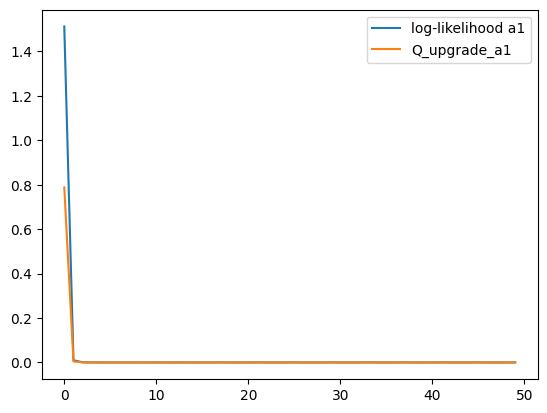

In [311]:
df = pd.DataFrame(evolution)
df.plot(y=['log-likelihood a1','Q_upgrade_a1'])
print((df['log-likelihood a1']-df['Q_upgrade_a1']).min())

0.0006919724835370289


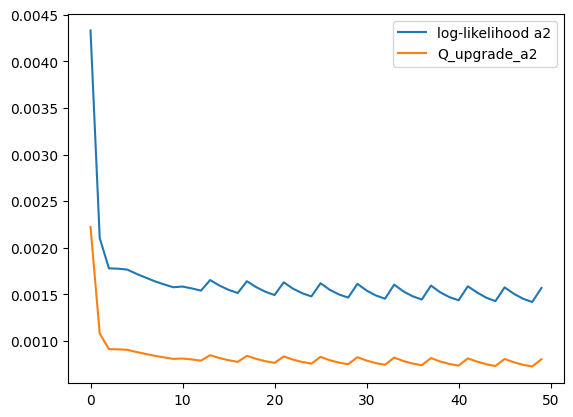

In [312]:
df = pd.DataFrame(evolution)
df.plot(y=['log-likelihood a2','Q_upgrade_a2'])
print((df['log-likelihood a2']-df['Q_upgrade_a2']).min())

Pour notre modèle avec variable exogène additive, on vérifie bien le critère de l'algorithme EM, à savoir $\Delta Q \leq \Delta \mathcal{L}$

##### 3. Variable Exogène de transition

In [19]:
sample_size = 4000
true_params =  {'alpha':np.array([[0,0]]),\
                'P': np.array([[0.8,0.2],[0.1,0.9]]),\
                'omega':np.array([0.8,0.2]),\
                #'exogen_transition' : np.random.uniform(0,1,size=(sample_size)),\
                'beta' : np.array([-0.1,0.1]),\
                #'mu' : np.array([1,0.1]),\
                #'exogen_additive' : abs(AR([0.9,0.08],length=sample_size*2)).reshape(sample_size,2),\
                'exogen_transition' : AR([0.9,0.08],length=sample_size),\
                'seed' : 3,\
                'pi_0' : np.array([0.5,0.5])
                    }

initial_params =    {'pi_0' : np.array([0.5,0.5]),\
                    'omega' : np.array([0.25,0.75]),\
                    'P' : np.ones((2,2))/2,\
                    'alpha' : np.array([[0,0]]),\
                    #'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    'beta' : np.array([0,0]),\
                    #'mu' : np.array([0.5,0.5]),\
                         }

model = MS_ARCH(true_params=true_params)
model.simulate(length=sample_size)

u2,pi2,evolution = MS_EM_algorithm_2_step(model.eps,true_params,niter=50,return_pi=True)

  0%|          | 0/50 [00:00<?, ?it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  2%|▏         | 1/50 [00:02<02:07,  2.60s/it]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  4%|▍         | 2/50 [00:02<00:59,  1.24s/it]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  6%|▌         | 3/50 [00:03<00:38,  1.23it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were 

In [20]:
results = copy(u2)
results[0] = {key:value for key,value in results[0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive']}
#result_exogen[0].pop('mu_depends_on_delta')
df = convert_dict_to_dataframe(results)
df['ispair'] = df.index%2

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/seaborn/_base.py:949: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_su

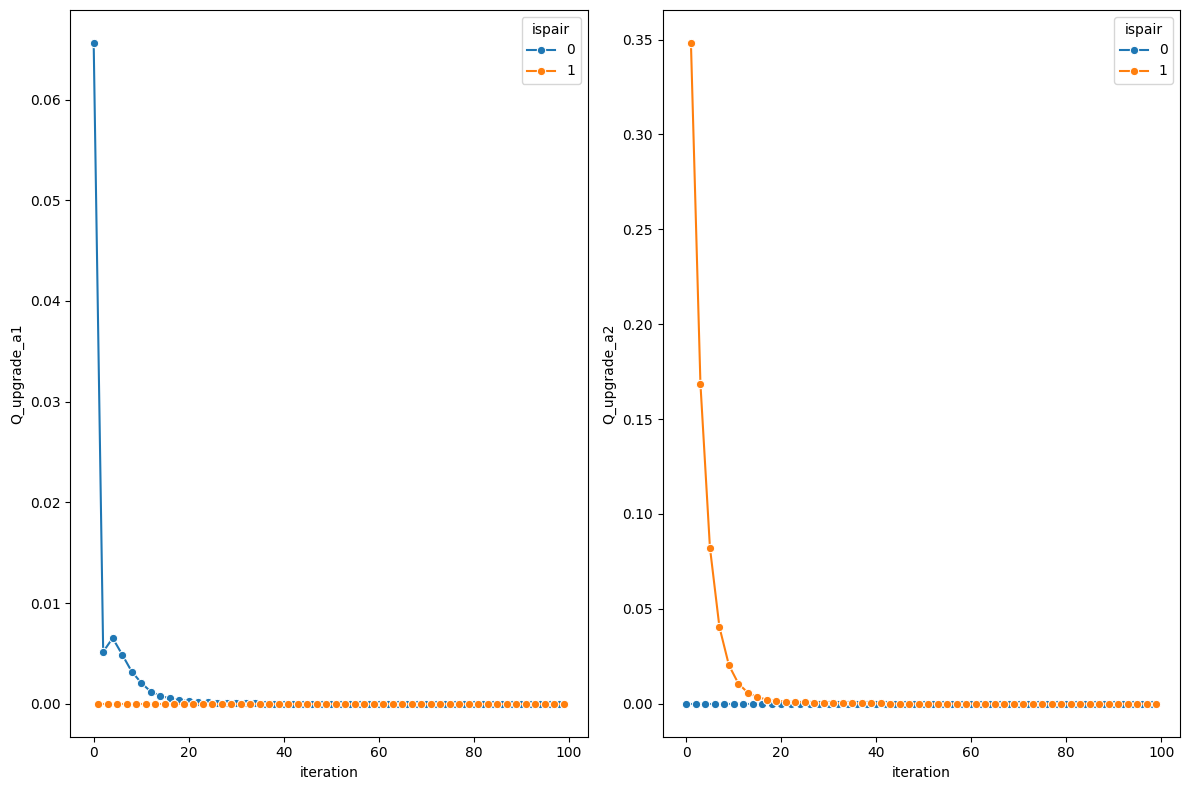

In [21]:
fig,axs=plt.subplots(1,2,figsize=(12,8))
sns.lineplot(df,y='Q_upgrade_a1',x=df.index,hue='ispair',marker='o',ax=axs[0])
sns.lineplot(df,y='Q_upgrade_a2',x=df.index,hue='ispair',marker='o',ax=axs[1])
plt.tight_layout()

#### Diagnostic
- D'une part, on remarque que a2 évolue pendant l'optimisation de a1, ce qui n'est pas censé arriver
- D'autre part, on remarque que a2 peut parfois baisser pendant son optimisation, pourtant affichée comme un succès (à check)
- La relation $Q\leq\mathcal{L}$ est difficile à étudier, il faudrait déjà avoir affaire au "vrai" $\mathcal{Q}$

## Convergence numérique asymptotique

In [19]:
with open(f"Results//results_4000"+".pkl", "rb") as f:
    Results = pickle.load(f)

In [4]:
with open(f"Results//results_500_batch1"+".pkl", "rb") as f:
    Results = pickle.load(f)

In [37]:
true_params = deepcopy(Results['true_params'])

In [236]:
Paths = ["Results//results_500_batch1"+".pkl","Results//results_1000_batch1"+".pkl","Results//results_2000_batch1"+".pkl","Results//results_4000_batch1"+".pkl"]
Sample_sizes = [500,1000,2000,4000]
columns = ['P','beta','omega','alpha','pi_0','log-likelihood']
Dfs = []
for path,sample_size in zip(Paths,Sample_sizes):
    with open(path, "rb") as f:
        Results = pickle.load(f)
    for i in tqdm(Results.keys()):
        if i != 'true_params':
            Results[i][0] = {key:value for key,value in Results[i][0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive','transition_f','beta_constraint']}
            new_df = convert_dict_to_dataframe(Results[i])
            new_df['version'] = i
            new_df['sample_size'] = sample_size
            Dfs.append(new_df)
df = pd.concat(Dfs)
true_params = deepcopy(Results['true_params'])
true_values = convert_dict_to_dataframe({0:{key:value for key,value in true_params.items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive','transition_f']}})
#df.drop(columns=['Q_start','Q_mid','Q_end','log-likelihood-mid'],inplace=True)

100%|██████████| 301/301 [00:48<00:00,  6.22it/s]


KeyError: "['Q_start', 'Q_mid', 'Q_end', 'log-likelihood-mid'] not found in axis"

In [4]:
Paths = ["Results//results_500_batch1"+".pkl","Results//results_1000_batch1"+".pkl","Results//results_2000_batch1"+".pkl","Results//results_4000_batch1"+".pkl"]
Sample_sizes = [500,1000,2000,4000]
columns = ['P','beta','omega','alpha','pi_0','log-likelihood']
Dfs = []
for path,sample_size in zip(Paths,Sample_sizes):
    with open(path, "rb") as f:
        Results = pickle.load(f)
    for i in tqdm(Results.keys()):
        if i != 'true_params':
            Results[i][0] = {key:value for key,value in Results[i][0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive','transition_f','beta_constraint']}
            new_df = convert_dict_to_dataframe(Results[i])
            new_df['version'] = i
            new_df['sample_size'] = sample_size
            Dfs.append(new_df)
df = pd.concat(Dfs)
true_params = deepcopy(Results['true_params'])
true_values = convert_dict_to_dataframe({0:{key:value for key,value in true_params.items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive','transition_f']}})
#df.drop(columns=['Q_start','Q_mid','Q_end','log-likelihood-mid'],inplace=True)

100%|██████████| 301/301 [00:49<00:00,  6.14it/s]


NameError: name 'deepcopy' is not defined

## Distribution Plots
We will be looking at different distribution plots (histogram, KDEPlotn ViolinPlot, QQPlot) for raw estimates $\hat{\theta}$ of $\theta_0$, and for a derived statistic which would,\
 under asymptotic normality, converge in law to a centered normal distribution of variance independent of the sample size $n$ : $T(\theta) := \sqrt(n)(\hat{\theta}-\overline{\hat{\theta}})$

### Histplot

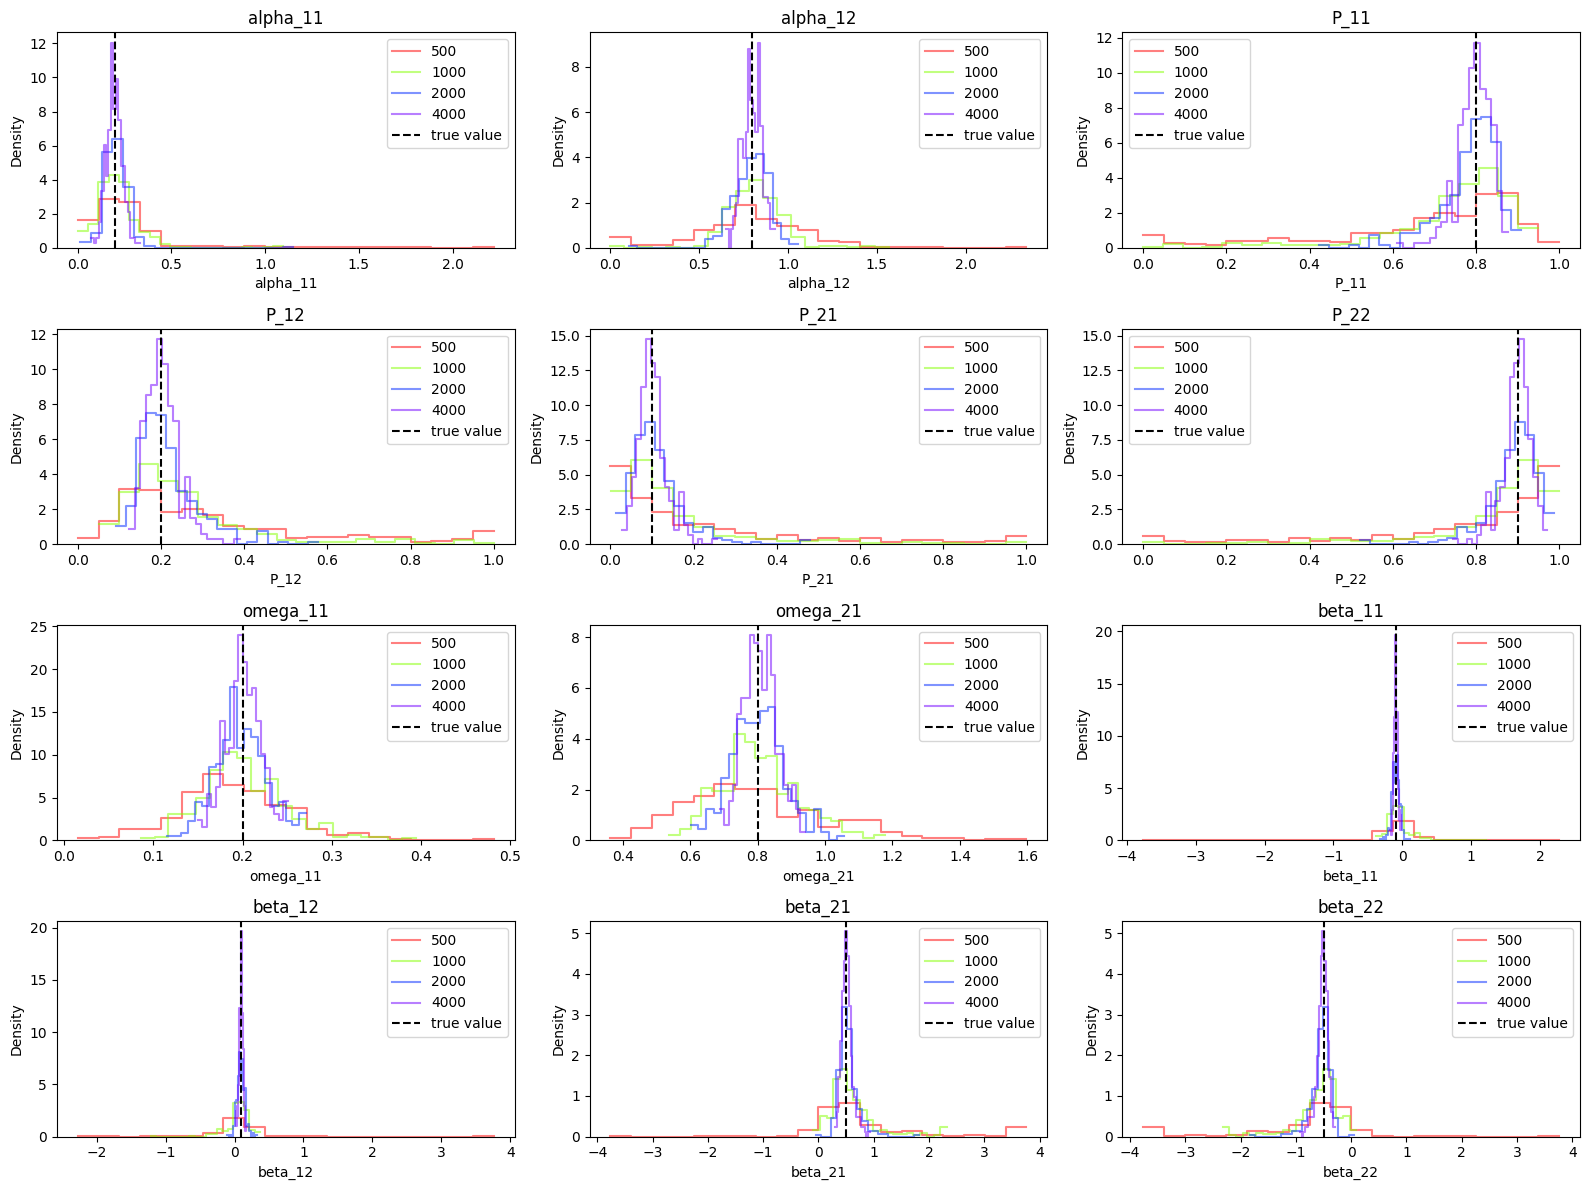

In [23]:
Colors = generate_colors(len(Sample_sizes))
#fig,axs = plt.subplots((true_values.columns),1,figsize=(45,15))
fig,axs = plt.subplots(len(true_values.columns)//3,3,figsize=(16,12))
for idx,col in enumerate(true_values.columns):
    for j,sample_size in enumerate(Sample_sizes):
        sns.histplot(df.loc[400].dropna(axis=0).query('sample_size == @sample_size').dropna(axis=0),x=col,kde=False,stat='density',bins=20,color=Colors[j],\
            line_kws={'alpha':0.2},fill=False,element='step',**{'alpha':0.5},label=f'{sample_size}',common_norm=True,ax=axs[idx//3,idx%3])
    axs[idx//3,idx%3].axvline(true_values[col].squeeze(),color='black',linestyle='--',label='true value')
    axs[idx//3,idx%3].set_title(col)
    axs[idx//3,idx%3].legend()

plt.tight_layout()

In [27]:
df.loc[400].query('sample_size == 500')

,pi_0_11,pi_0_21,omega_11,omega_21,P_11,P_12,P_21,P_22,alpha_11,alpha_12,beta_11,beta_12,beta_21,beta_22,log-likelihood,version,sample_size
iteration,,,,,,,,,,,,,,,,,
400,1.000000e+00,1.000000e-10,0.193441,0.758702,0.863747,0.136253,0.001386,0.998614,0.182610,0.772977,-0.115877,0.115877,1.603125,-1.603125,-606.146109,1,500
400,1.000000e+00,1.000000e-10,0.140700,0.908331,0.688779,0.311221,0.101171,0.898829,0.226980,0.861613,-0.069339,0.069339,0.553045,-0.553045,-656.345423,2,500
400,1.000000e+00,1.000000e-10,0.167273,0.960780,0.851641,0.148359,0.081548,0.918452,0.110339,0.492678,-0.181109,0.181109,0.498359,-0.498359,-599.565722,3,500
400,1.000000e+00,1.000000e-10,0.203639,1.080080,0.856078,0.143922,0.313461,0.686539,0.198974,0.941343,0.082450,-0.082450,0.134841,-0.134841,-541.127622,4,500
400,1.000000e+00,1.000000e-10,0.149091,0.722444,0.721133,0.278867,0.106747,0.893253,0.042642,0.708722,-0.125720,0.125720,0.390275,-0.390275,-596.892529,5,500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
400,1.000000e+00,1.000000e-10,0.257666,0.852136,0.834234,0.165766,0.000104,0.999896,0.109037,0.510129,-0.245418,0.245418,2.915165,-2.915165,-634.556411,296,500
400,1.000000e+00,1.000000e-10,0.138443,0.905542,0.774034,0.225966,0.108378,0.891622,0.270104,0.752802,-0.100933,0.100933,0.329487,-0.329487,-657.084424,297,500
400,1.000000e+00,1.000000e-10,0.169487,0.685665,0.794872,0.205128,0.068189,0.931811,0.326263,1.025380,-0.267870,0.267870,0.904445,-0.904445,-625.942507,298,500


In [29]:
true_values

,alpha_11,alpha_12,P_11,P_12,P_21,P_22,omega_11,omega_21,beta_11,beta_12,beta_21,beta_22
iteration,,,,,,,,,,,,
0,0.2,0.8,0.8,0.2,0.1,0.9,0.2,0.8,-0.1,0.1,0.5,-0.5


In [56]:
true_params

{'alpha': array([[0.2, 0.8]]),
 'P': array([[0.8, 0.2],
        [0.1, 0.9]]),
 'omega': array([0.2, 0.8]),
 'beta': array([[-0.1,  0.1],
        [ 0.5, -0.5]]),
 'exogen_transition': array([ 1.        ,  0.49903174,  0.32391443, ..., -5.78632281,
        -5.09592859, -5.42180262]),
 'transition_f': 'soft-exp'}

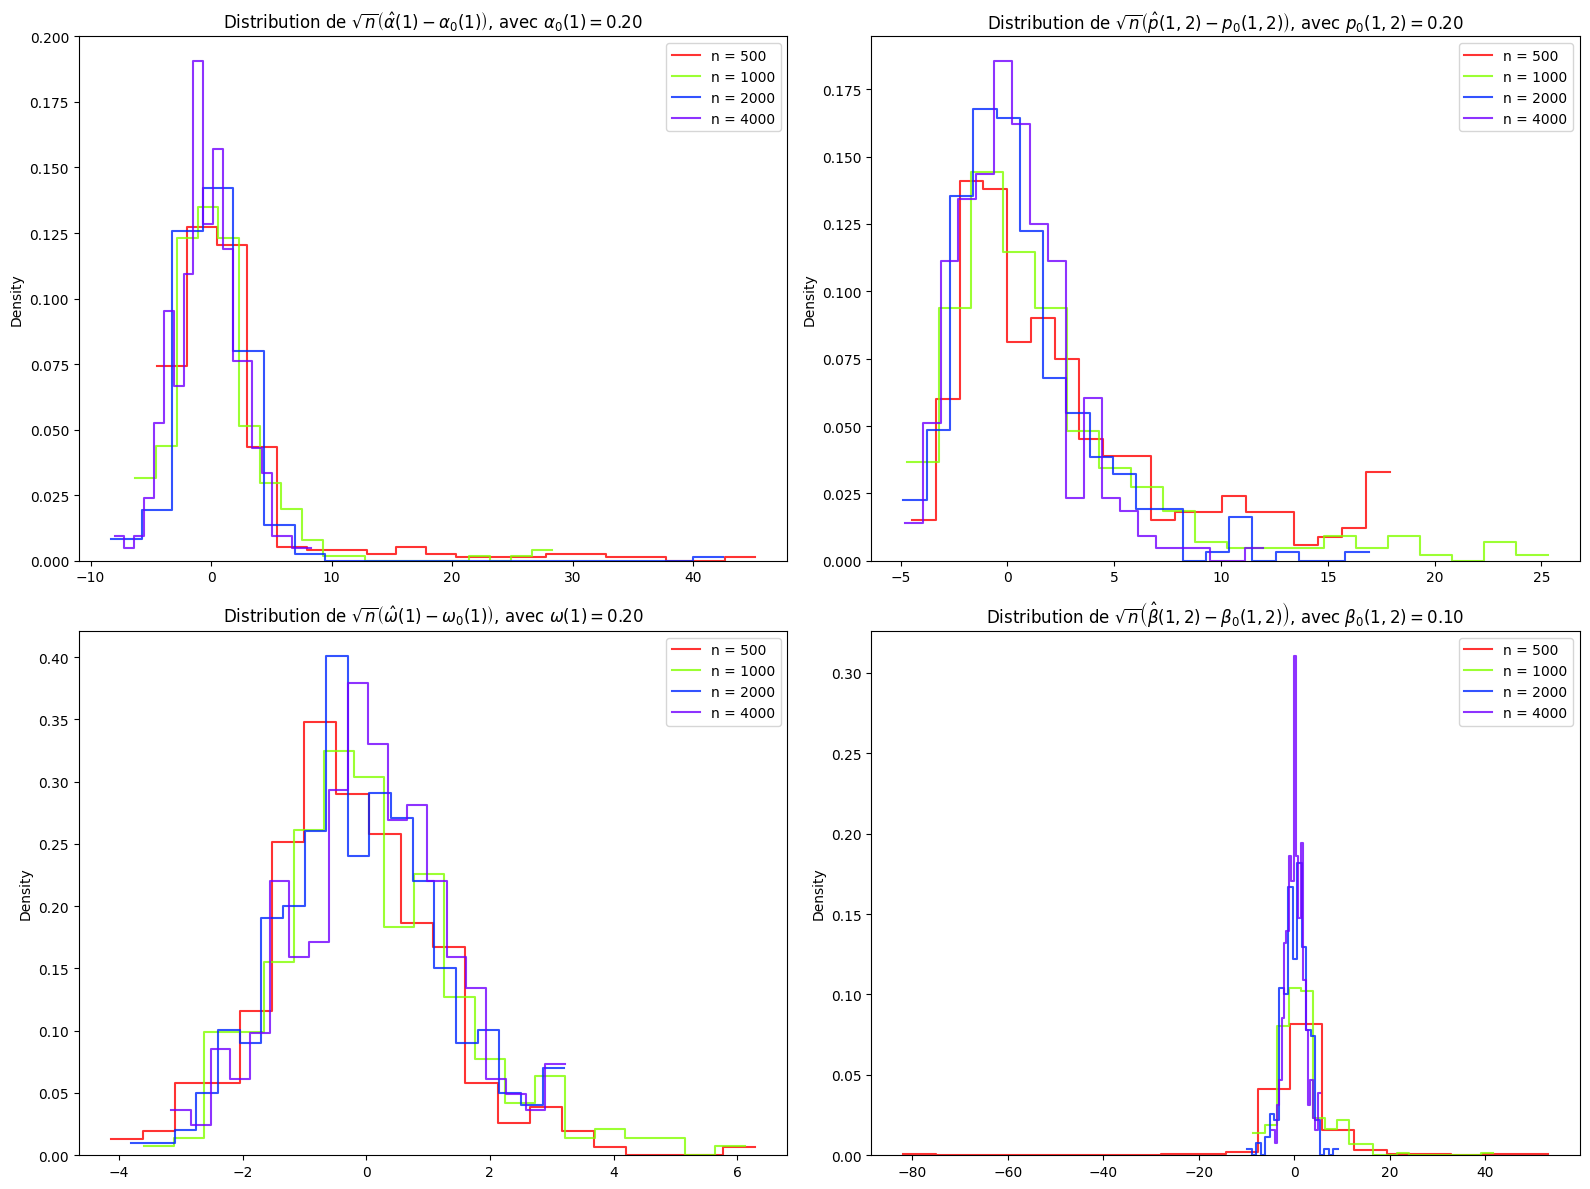

In [66]:
Colors = generate_colors(len(Sample_sizes))
#fig,axs = plt.subplots((true_values.columns),1,figsize=(45,15))
fig,axs = plt.subplots(2,2,figsize=(16,12))
true_cols = ['alpha_11','P_12','omega_11','beta_11']
for idx,col in enumerate(true_values[true_cols]):
    for j,sample_size in enumerate(Sample_sizes):
        to_plot = df.loc[400].dropna(axis=0).query('sample_size == @sample_size').dropna(axis=0)[col]
        sns.histplot(np.sqrt(sample_size)*(to_plot-true_values[col].values),kde=False,stat='density',bins=20,color=Colors[j],\
        line_kws={'alpha':0.2},fill=False,element='step',**{'alpha':0.8},common_norm=True,ax=axs[idx//2,idx%2],label=f'n = {sample_size}')
    #axs[idx//2,idx%2].axvline(0,color='black',linestyle='--',label='true value')
    axs[idx//2,idx%2].set_title(f'$\\sqrt{{n}}*$(centralized {col})')
    axs[0,0].set_title(r"Distribution de $\sqrt{n} \left( \hat{\alpha}{(1)} - \alpha_0{(1)} \right)$"+", avec "+r"$\alpha_0{(1)} = $"+f"{true_params['alpha'][0,0]:.2f}")
    axs[0,1].set_title(r"Distribution de $\sqrt{n} \left( \hat{p}{(1,2)} - p_0{(1,2)} \right)$"+", avec "+r"$p_0{(1,2)} = $"+f"{true_params['P'][0,1]:.2f}")
    axs[1,0].set_title(r"Distribution de $\sqrt{n} \left( \hat{\omega}{(1)} - \omega_0{(1)} \right)$"+", avec "+r"$\omega{(1)} = $"+f"{true_params['omega'][0]:.2f}")
    axs[1,1].set_title(r"Distribution de $\sqrt{n} \left( \hat{\beta}{(1,2)} - \beta_0{(1,2)} \right)$"+", avec "+r"$\beta_0{(1,2)} = $"+f"{true_params['beta'][0,1]:.2f}")
    axs[0,0].set_xlabel(None)
    axs[0,1].set_xlabel(None)
    axs[1,0].set_xlabel(None)
    axs[1,1].set_xlabel(None)
    
    axs[idx//2,idx%2].legend()
plt.tight_layout()
plt.savefig('fig.png')

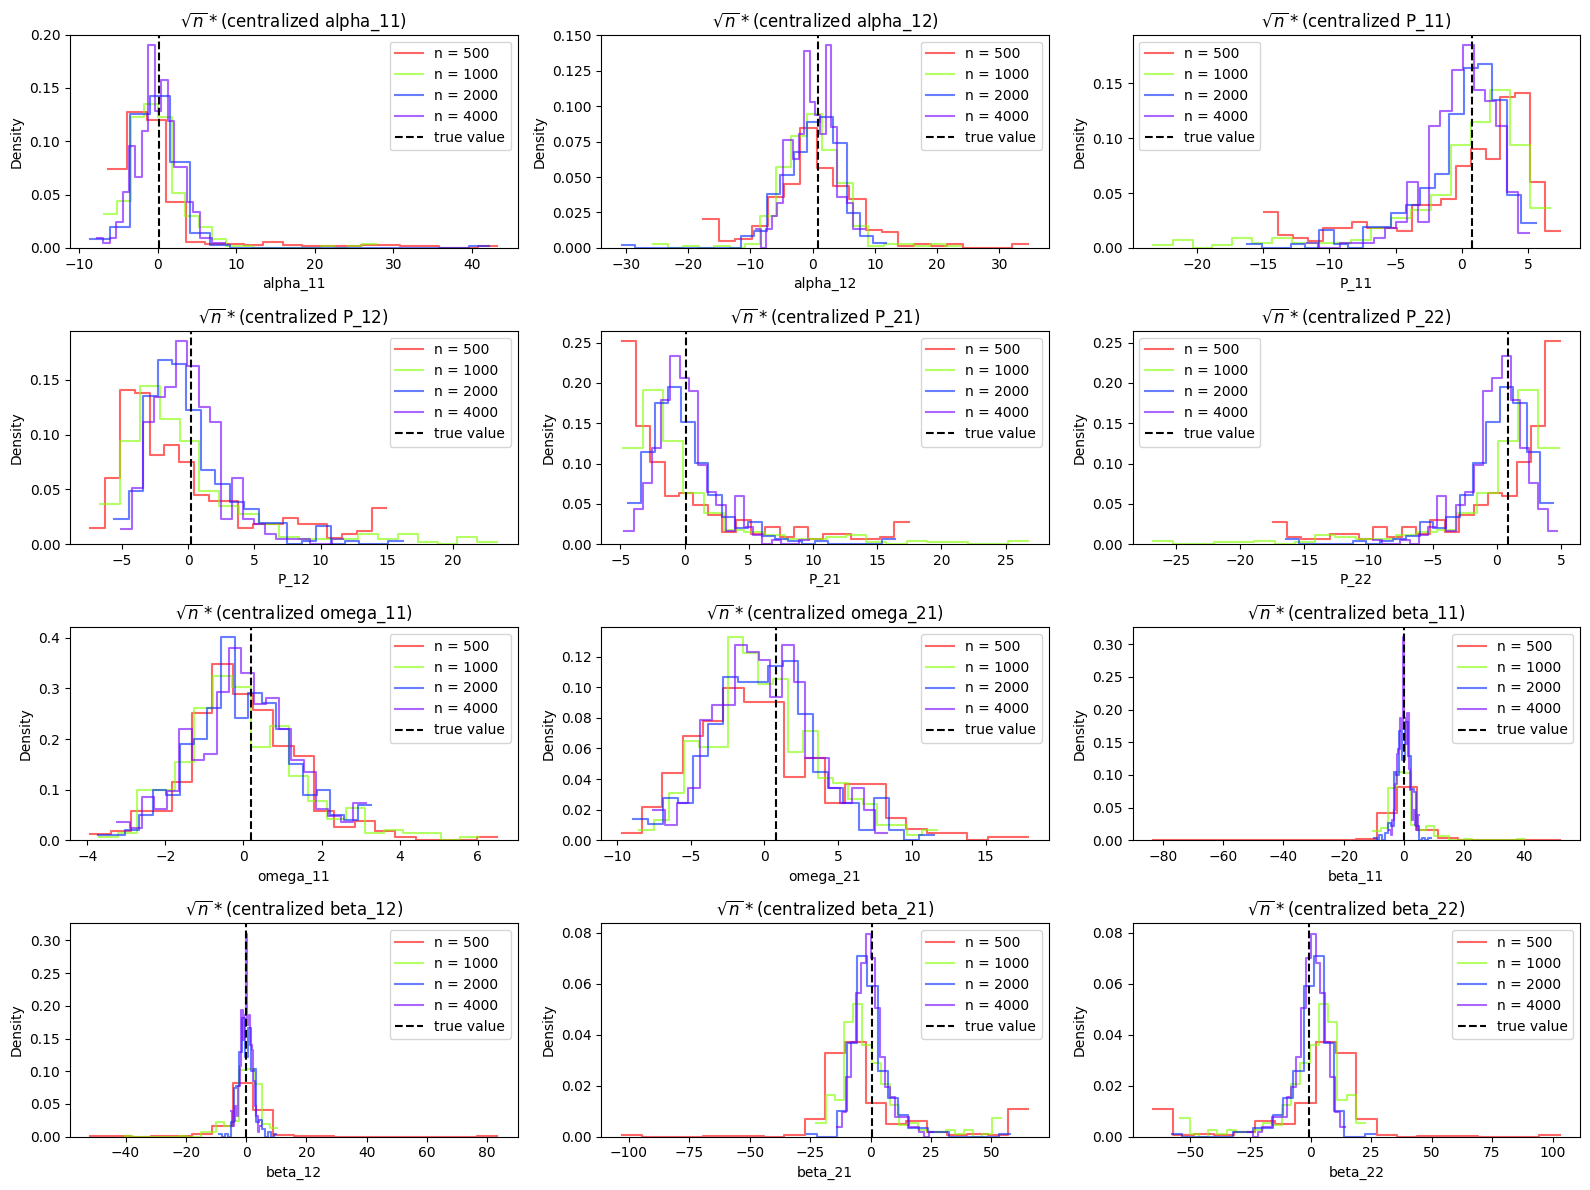

In [ ]:
Colors = generate_colors(len(Sample_sizes))
#fig,axs = plt.subplots((true_values.columns),1,figsize=(45,15))
fig,axs = plt.subplots(len(true_values.columns)//3,3,figsize=(16,12))
for idx,col in enumerate(true_values.columns):
    for j,sample_size in enumerate(Sample_sizes):
        to_plot = df.loc[400].dropna(axis=0).query('sample_size == @sample_size').dropna(axis=0)[col]
        sns.histplot(np.sqrt(sample_size)*(to_plot-to_plot.mean()),kde=False,stat='density',bins=20,color=Colors[j],\
        line_kws={'alpha':0.2},fill=False,element='step',**{'alpha':0.6},common_norm=True,ax=axs[idx//3,idx%3],label=f'n = {sample_size}')
    axs[idx//3,idx%3].axvline(true_values[col].squeeze(),color='black',linestyle='--',label='true value')
    axs[idx//3,idx%3].set_title(f'$\\sqrt{{n}}*$(centralized {col})')
    axs[idx//3,idx%3].legend()

plt.tight_layout()

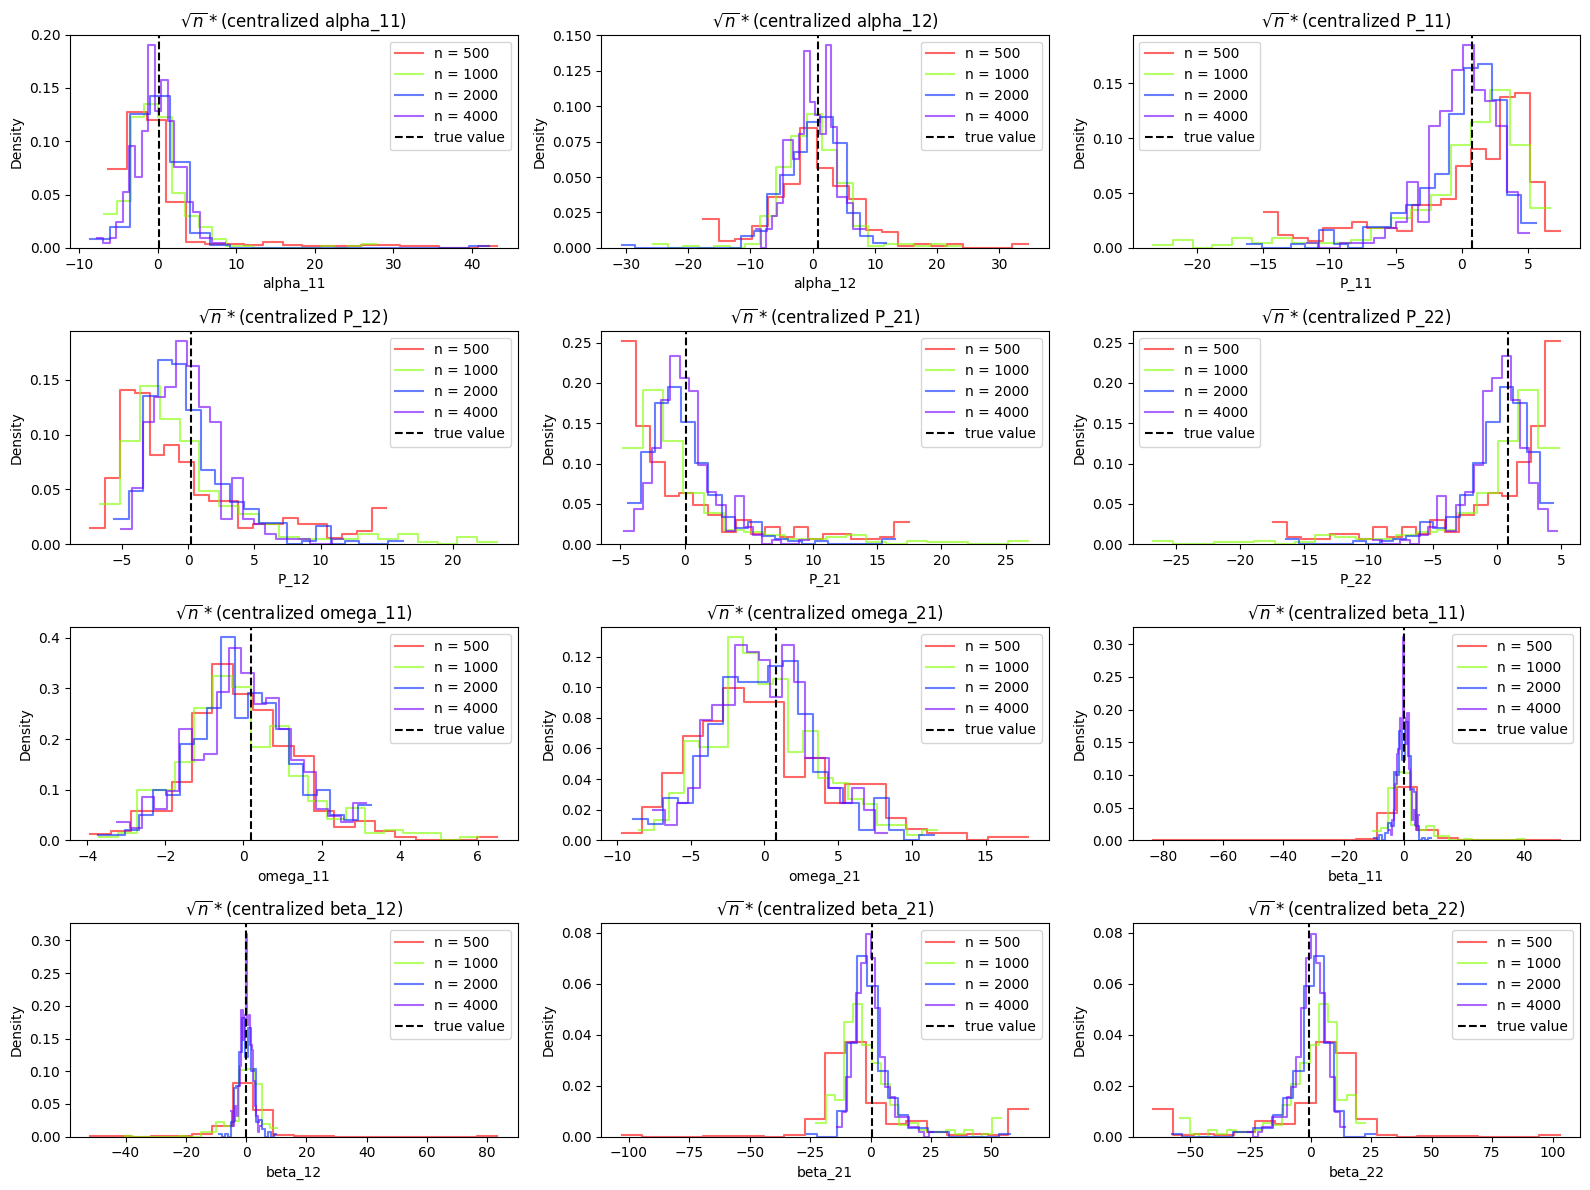

In [ ]:
Colors = generate_colors(len(Sample_sizes))
#fig,axs = plt.subplots((true_values.columns),1,figsize=(45,15))
fig,axs = plt.subplots(len(true_values.columns)//3,3,figsize=(16,12))
for idx,col in enumerate(true_values.columns):
    for j,sample_size in enumerate(Sample_sizes):
        to_plot = df.loc[400].dropna(axis=0).query('sample_size == @sample_size').dropna(axis=0)[col]
        sns.histplot(np.sqrt(sample_size)*(to_plot-to_plot.mean()),kde=False,stat='density',bins=20,color=Colors[j],\
        line_kws={'alpha':0.2},fill=False,element='step',**{'alpha':0.6},common_norm=True,ax=axs[idx//3,idx%3],label=f'n = {sample_size}')
    axs[idx//3,idx%3].axvline(true_values[col].squeeze(),color='black',linestyle='--',label='true value')
    axs[idx//3,idx%3].set_title(f'$\\sqrt{{n}}*$(centralized {col})')
    axs[idx//3,idx%3].legend()

plt.tight_layout()

### KDEPlot

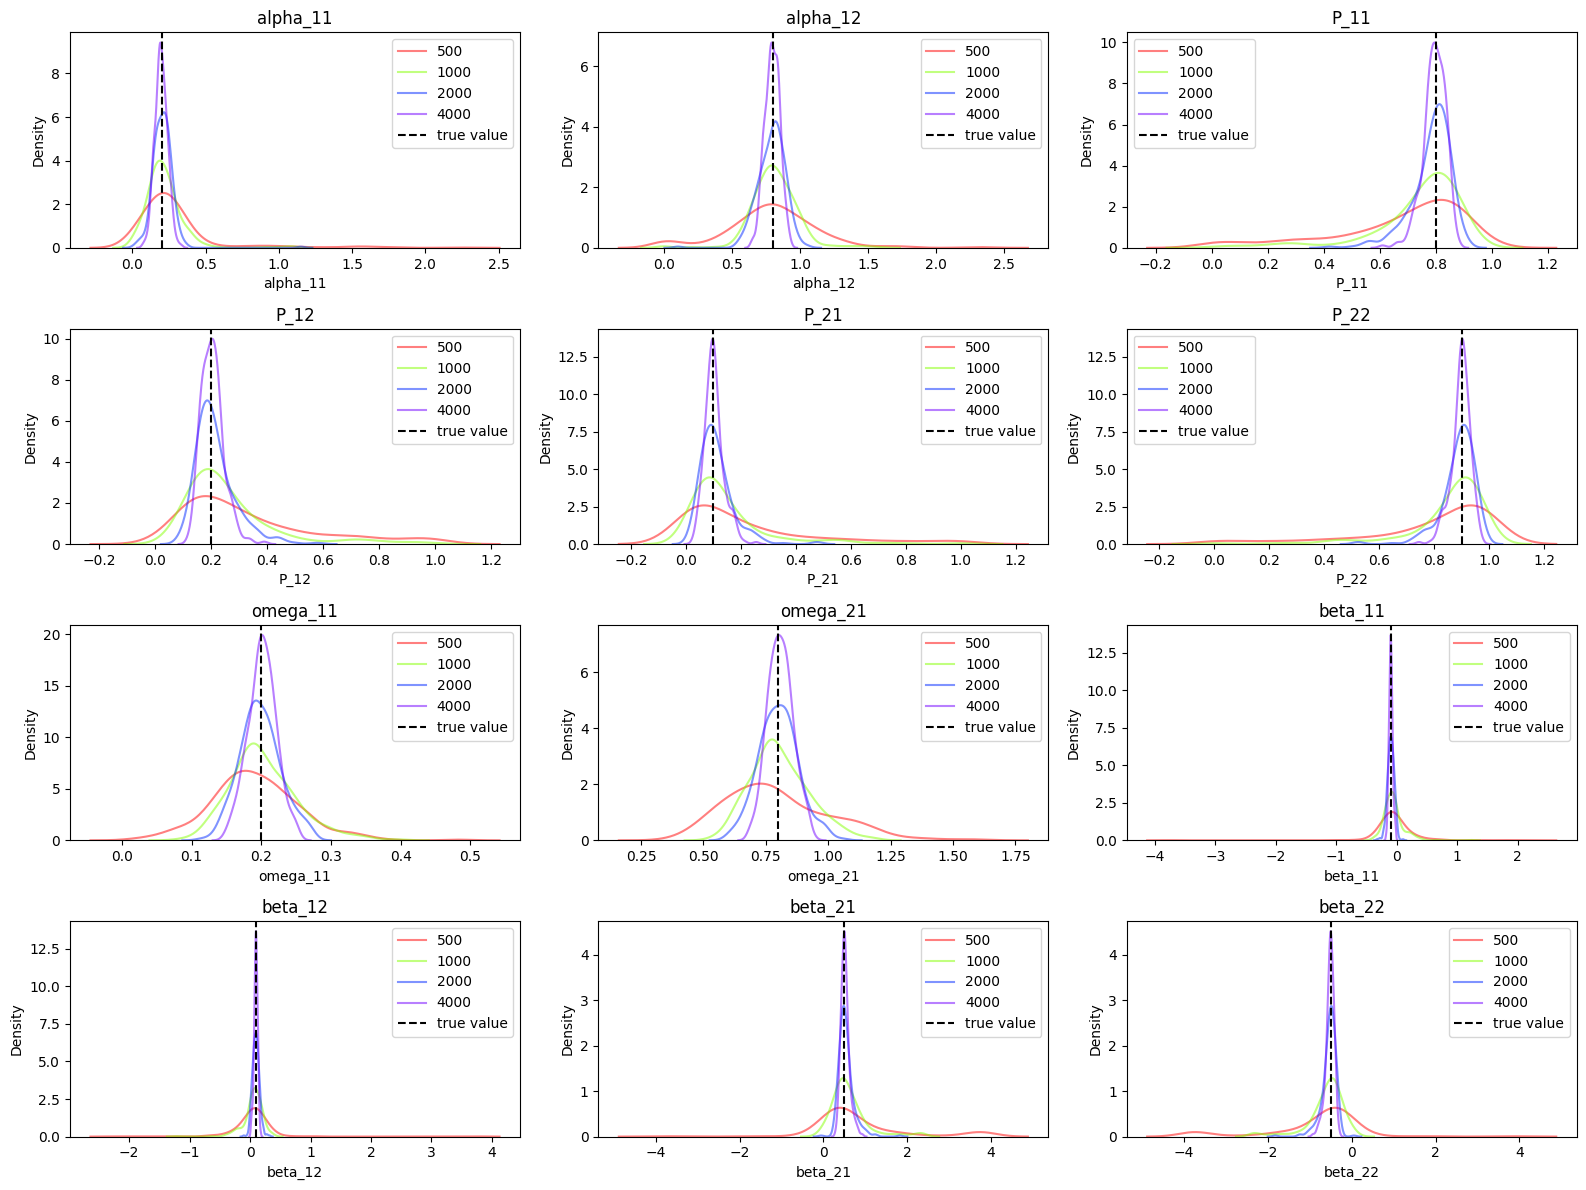

In [ ]:
Colors = generate_colors(len(Sample_sizes))
#fig,axs = plt.subplots((true_values.columns),1,figsize=(45,15))
fig,axs = plt.subplots(len(true_values.columns)//3,3,figsize=(16,12))
for idx,col in enumerate(true_values.columns):
    for j,sample_size in enumerate(Sample_sizes):
        sns.kdeplot(df.loc[400].dropna(axis=0).query('sample_size == @sample_size'),x=col,color=Colors[j],\
            fill=False,**{'alpha':0.5},label=f'{sample_size}',ax=axs[idx//3,idx%3])
    axs[idx//3,idx%3].axvline(true_values[col].squeeze(),color='black',linestyle='--',label='true value')
    axs[idx//3,idx%3].set_title(col)
    axs[idx//3,idx%3].legend()

plt.tight_layout()

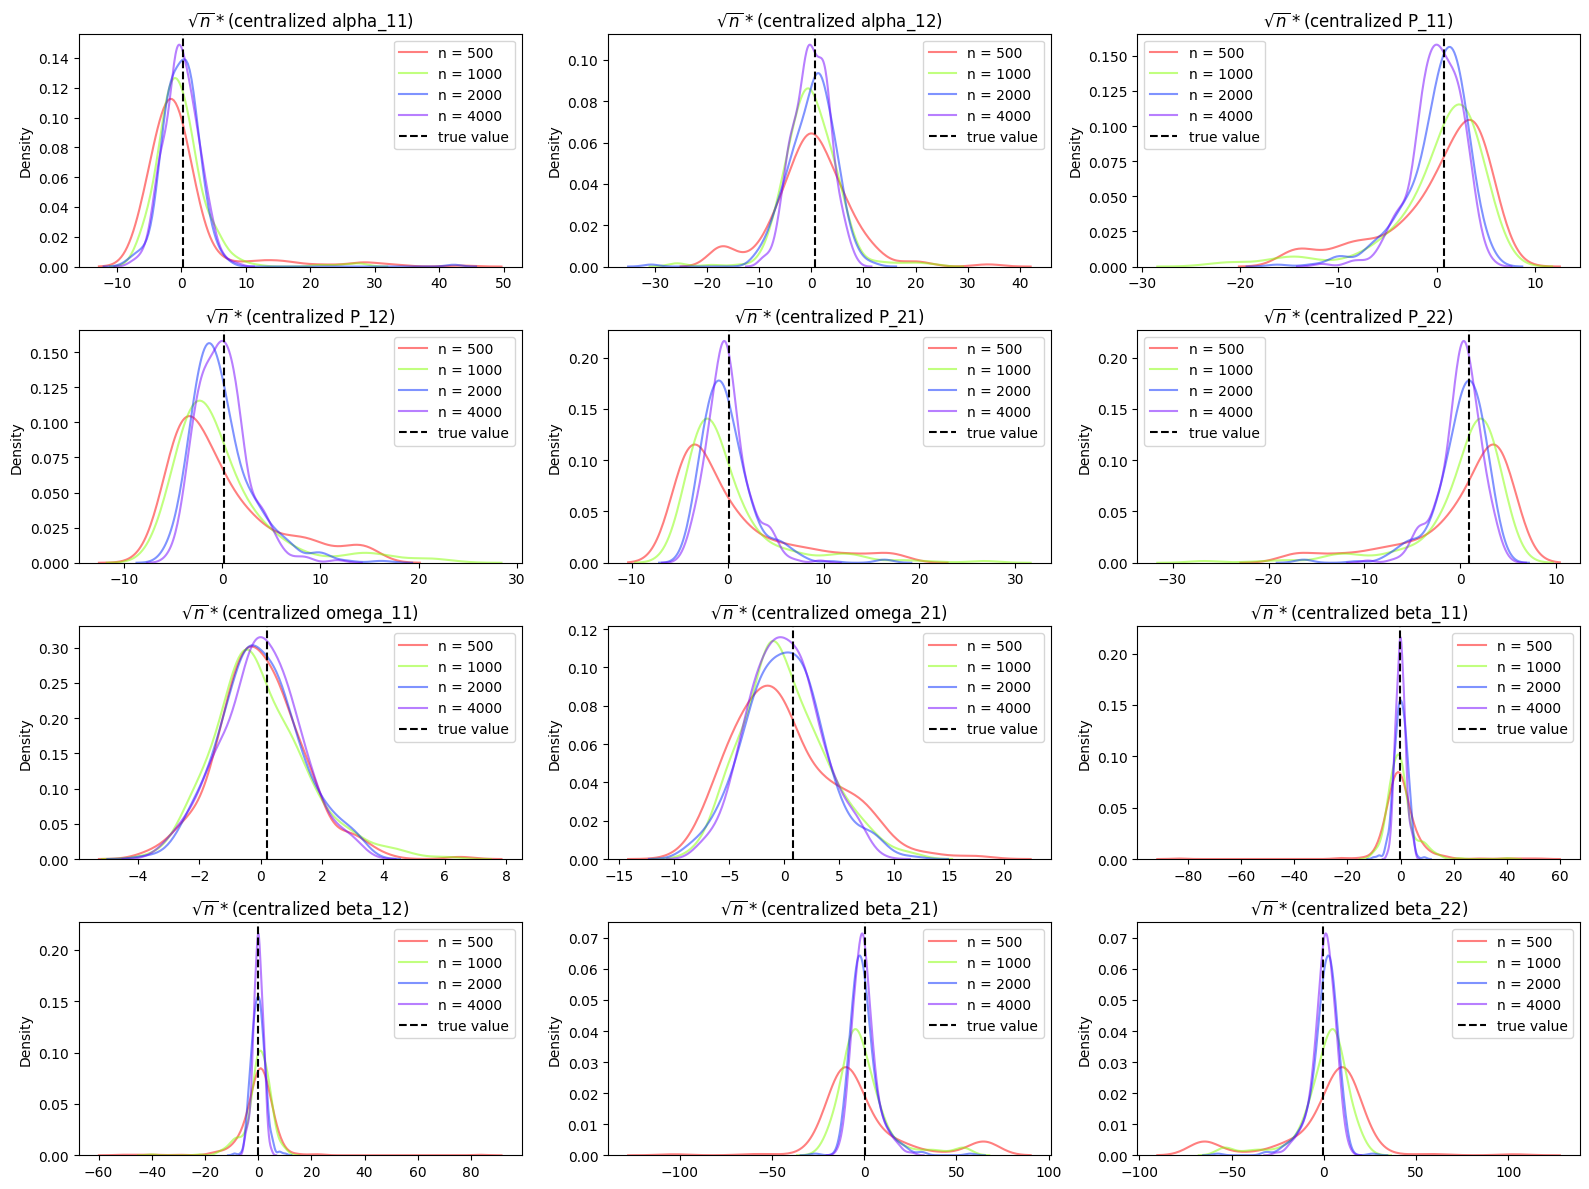

In [ ]:
Colors = generate_colors(len(Sample_sizes))
#fig,axs = plt.subplots((true_values.columns),1,figsize=(45,15))
fig,axs = plt.subplots(len(true_values.columns)//3,3,figsize=(16,12))
for idx,col in enumerate(true_values.columns):
    for j,sample_size in enumerate(Sample_sizes):
        to_plot = df.loc[400].dropna(axis=0).query('sample_size == @sample_size').dropna(axis=0)[col]
        sns.kdeplot(np.sqrt(sample_size)*(to_plot-to_plot.mean()),color=Colors[j],\
            fill=False,**{'alpha':0.5},label=f'n = {sample_size}',ax=axs[idx//3,idx%3])
        #sns.histplot(np.sqrt(sample_size)*(to_plot-to_plot.mean()))
    axs[idx//3,idx%3].axvline(true_values[col].squeeze(),color='black',linestyle='--',label='true value')
    axs[idx//3,idx%3].set_title(f'$\\sqrt{{n}}*$(centralized {col})')
    axs[idx//3,idx%3].set_xlabel('')  # Hides the entire x-axis
    axs[idx//3,idx%3].legend()
plt.tight_layout()

### Violin Plot

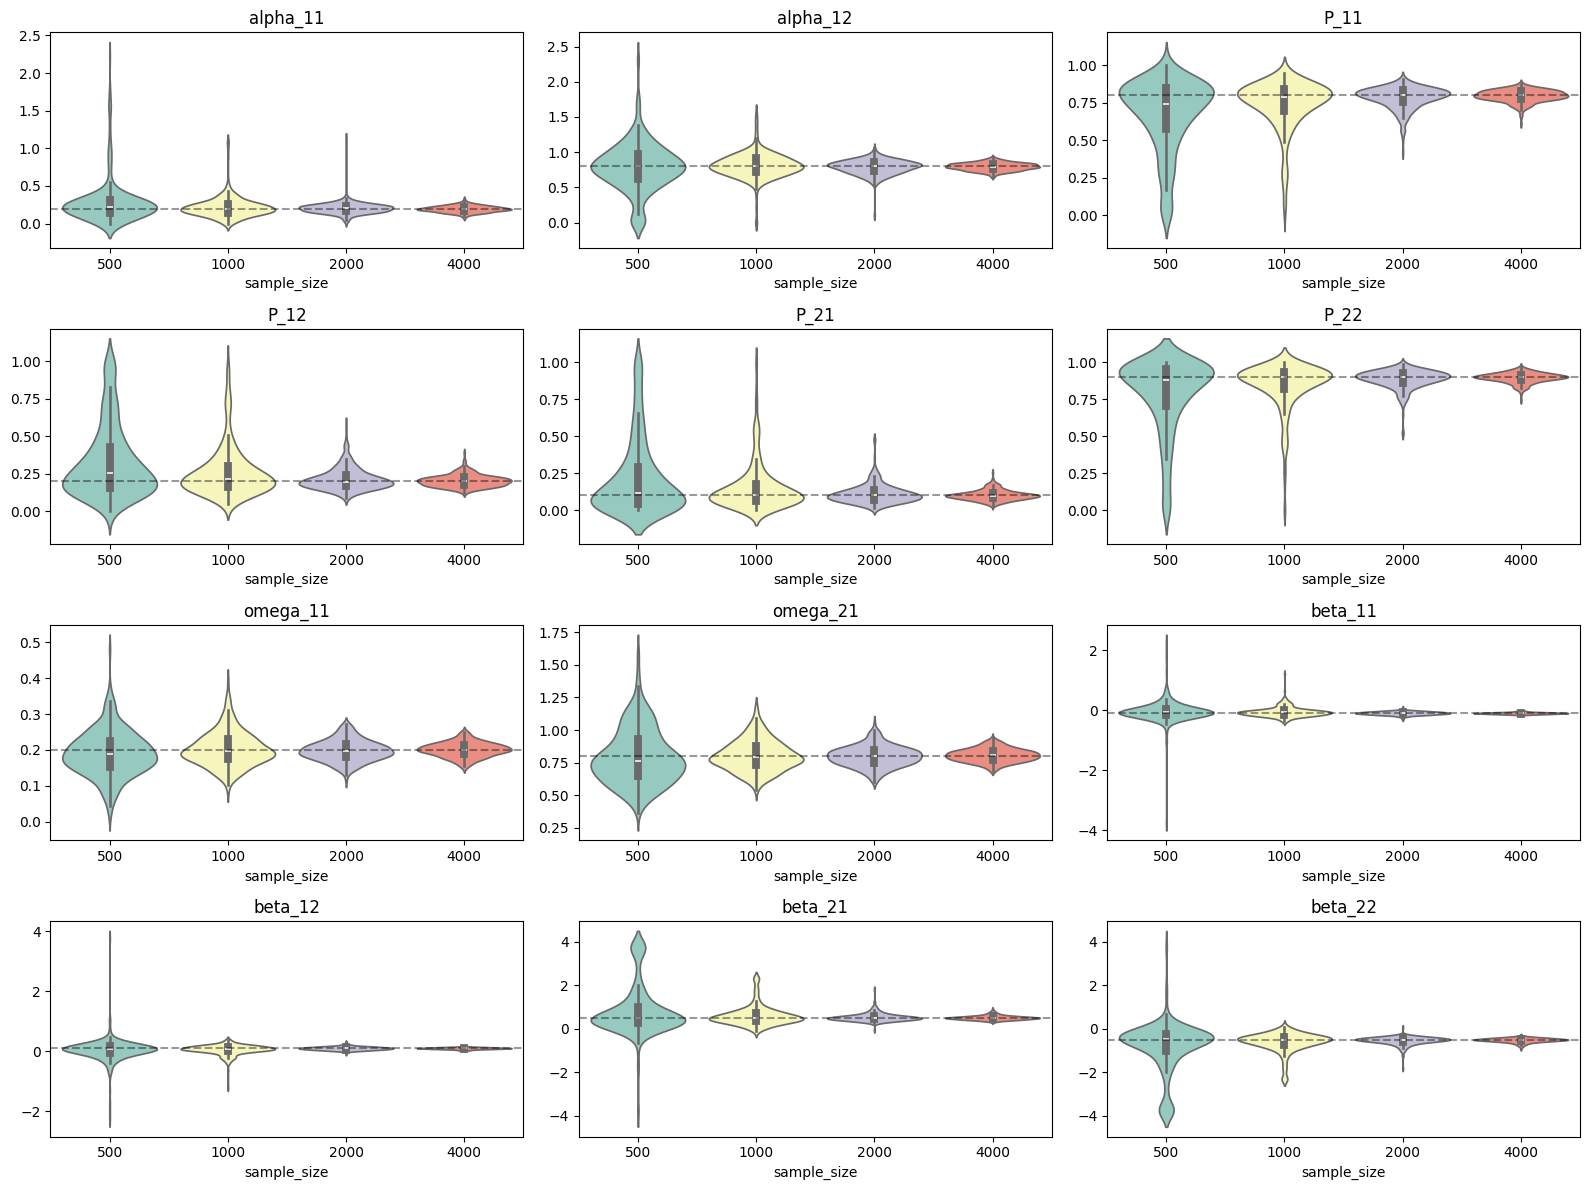

In [ ]:
fig,axs = plt.subplots(len(true_values.columns)//3,3,figsize=(16,12))
for idx,col in enumerate(true_values.columns):
    sns.violinplot(df.loc[400].dropna(axis=0).dropna(axis=0),y=col,x='sample_size',\
                    fill=True,hue='sample_size',palette='Set3',ax=axs[idx//3,idx%3])
    axs[idx//3,idx%3].set_title(col)
    axs[idx//3,idx%3].axhline(true_values[col].squeeze(),color='black',linestyle='--',label='true value',alpha=0.4)
    #axs[idx//3,idx%3].legend()#
    axs[idx//3,idx%3].set_ylabel('')
    axs[idx//3,idx%3].get_legend().remove()
plt.tight_layout()


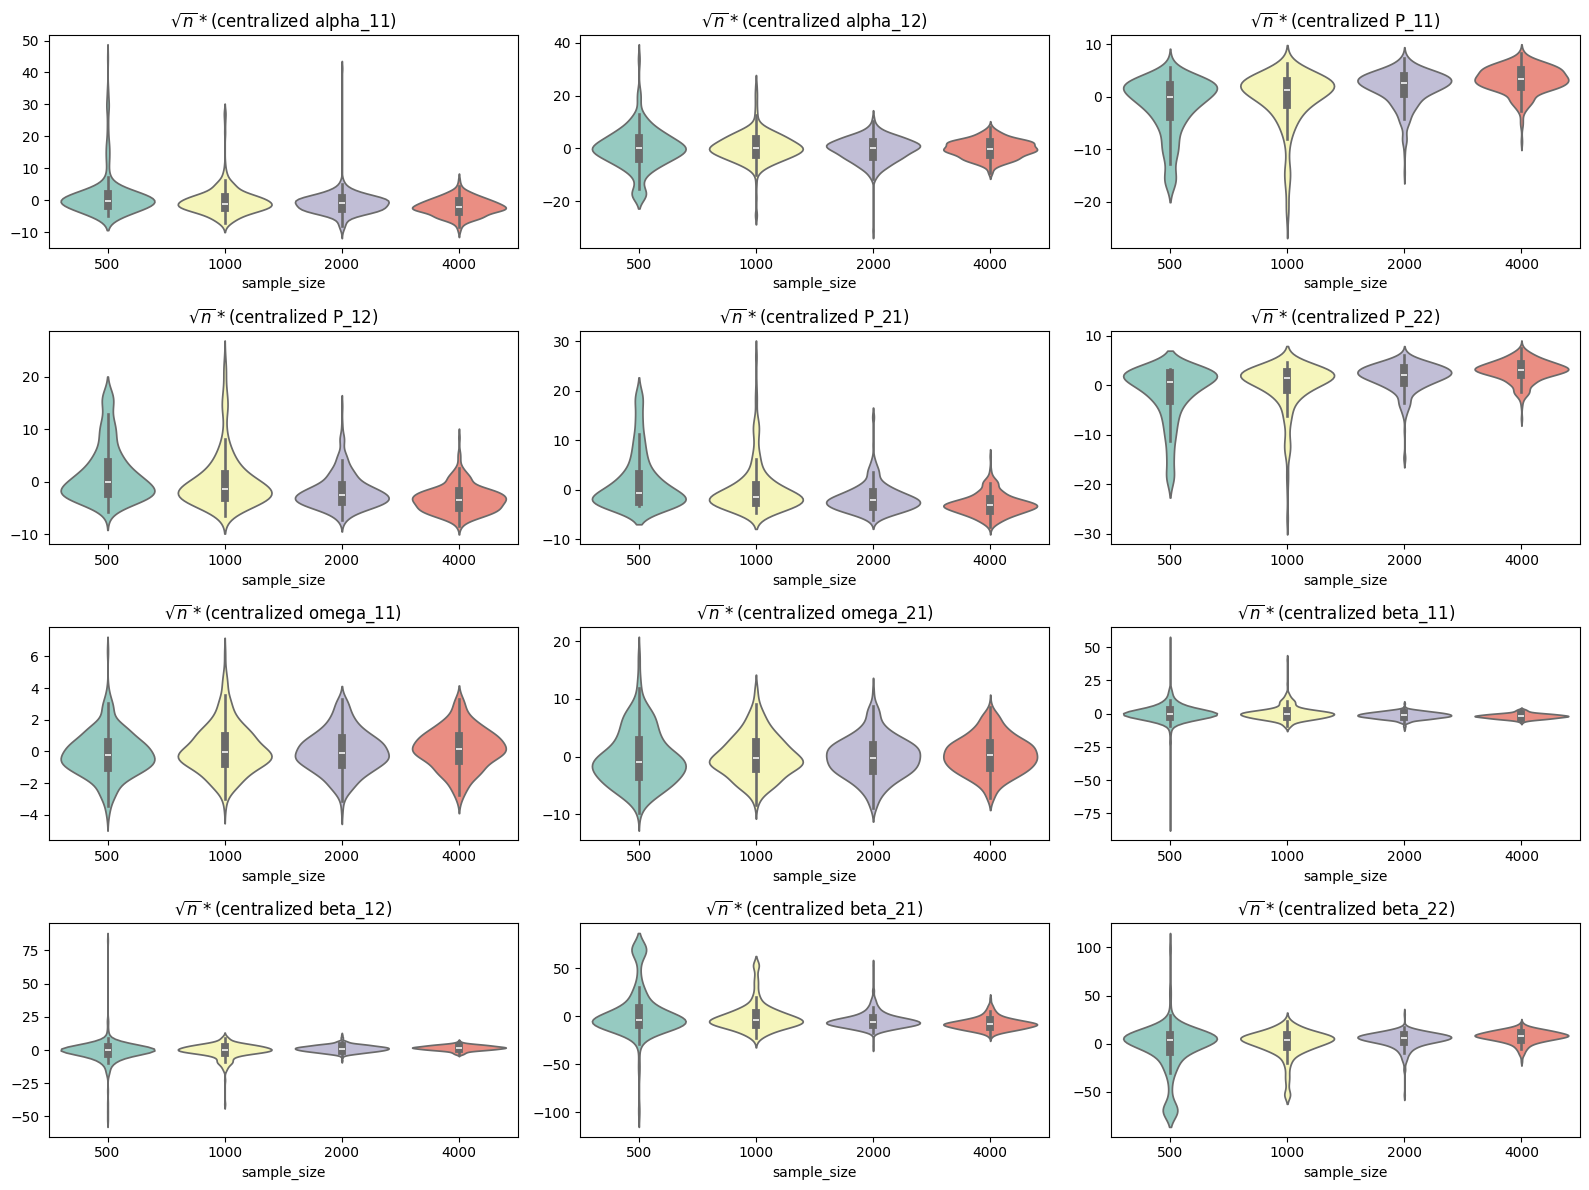

In [ ]:
fig,axs = plt.subplots(len(true_values.columns)//3,3,figsize=(16,12))
for idx,col in enumerate(true_values.columns):
    to_plot = deepcopy(df.loc[400].dropna(axis=0))
    to_plot[f'centralized {col}'] = np.sqrt(to_plot['sample_size'])*(to_plot[col]-to_plot[col].mean())
    sns.violinplot(to_plot,y='centralized '+col,x='sample_size',\
                    fill=True,hue='sample_size',palette='Set3',ax=axs[idx//3,idx%3])
    axs[idx//3,idx%3].set_title(f'$\\sqrt{{n}}*$(centralized {col})')
    #axs[idx//3,idx%3].legend()#
    axs[idx//3,idx%3].set_ylabel('')
    axs[idx//3,idx%3].get_legend().remove()
plt.tight_layout()


### QQ-Plot

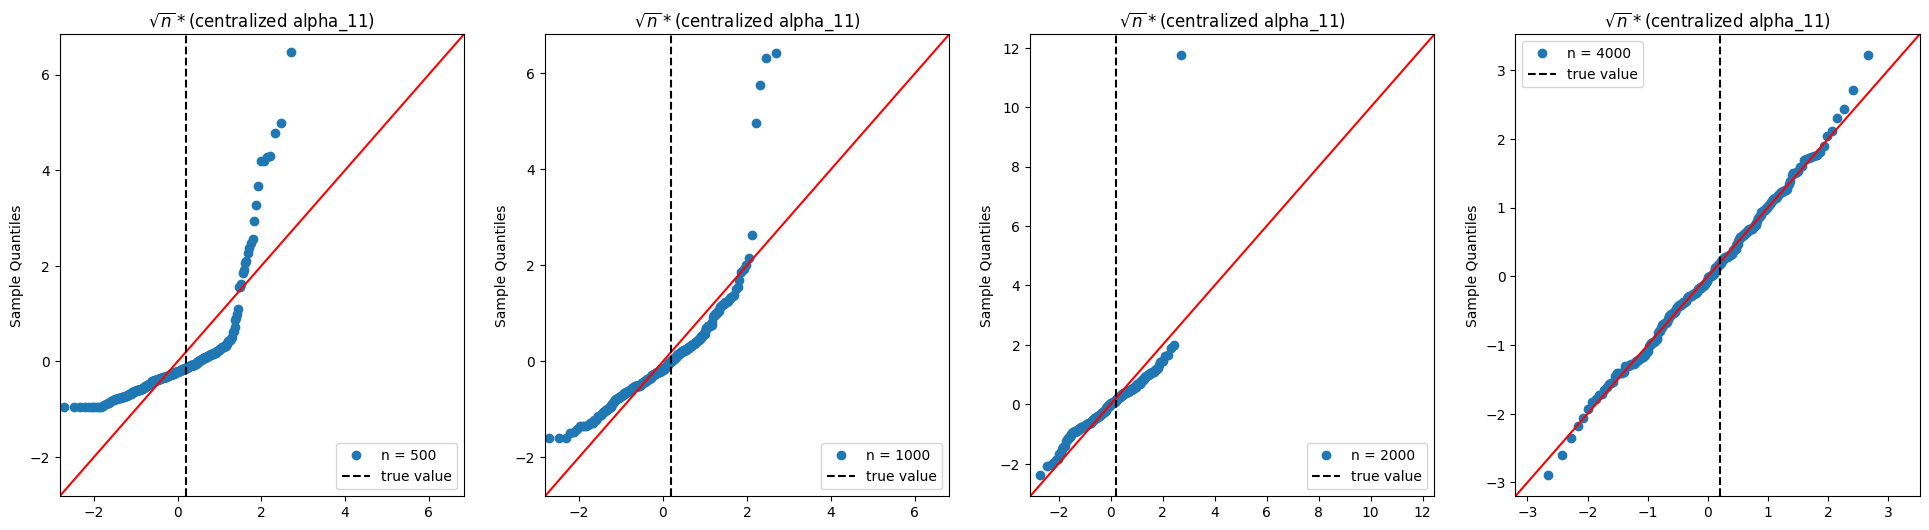

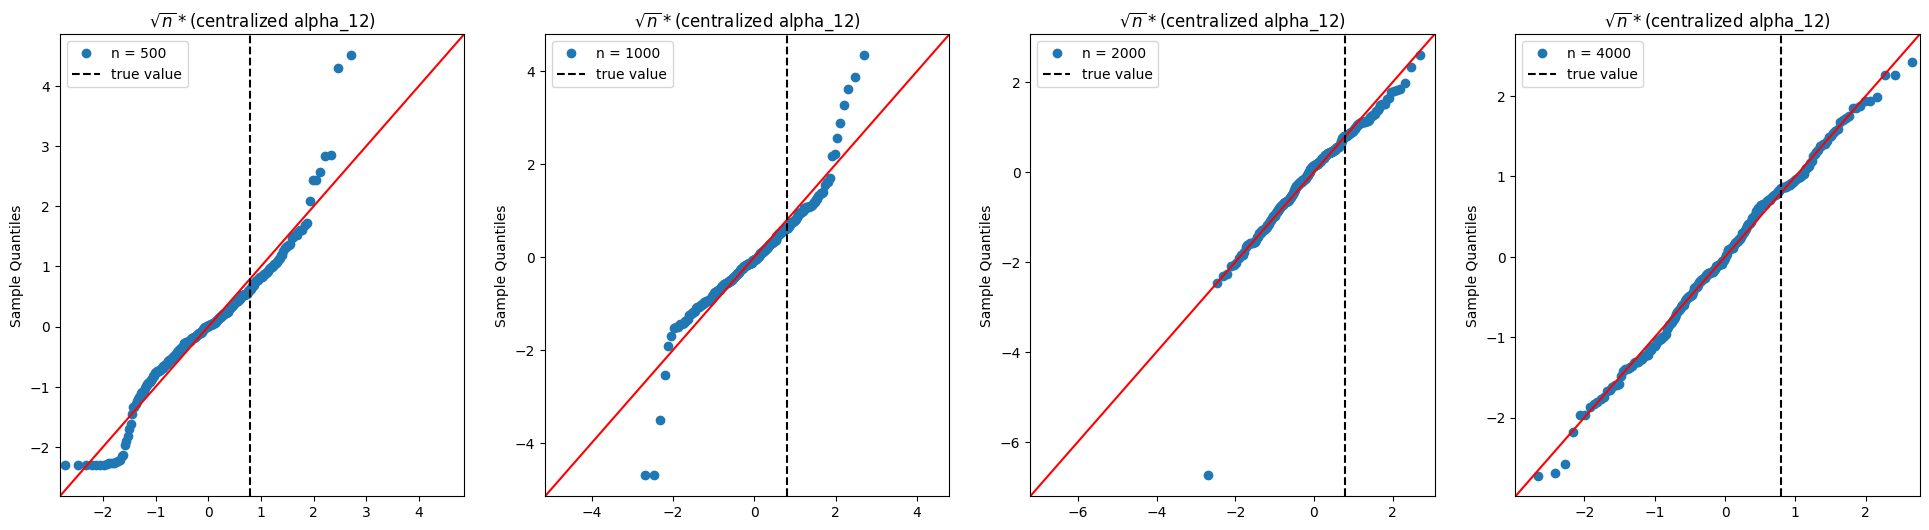

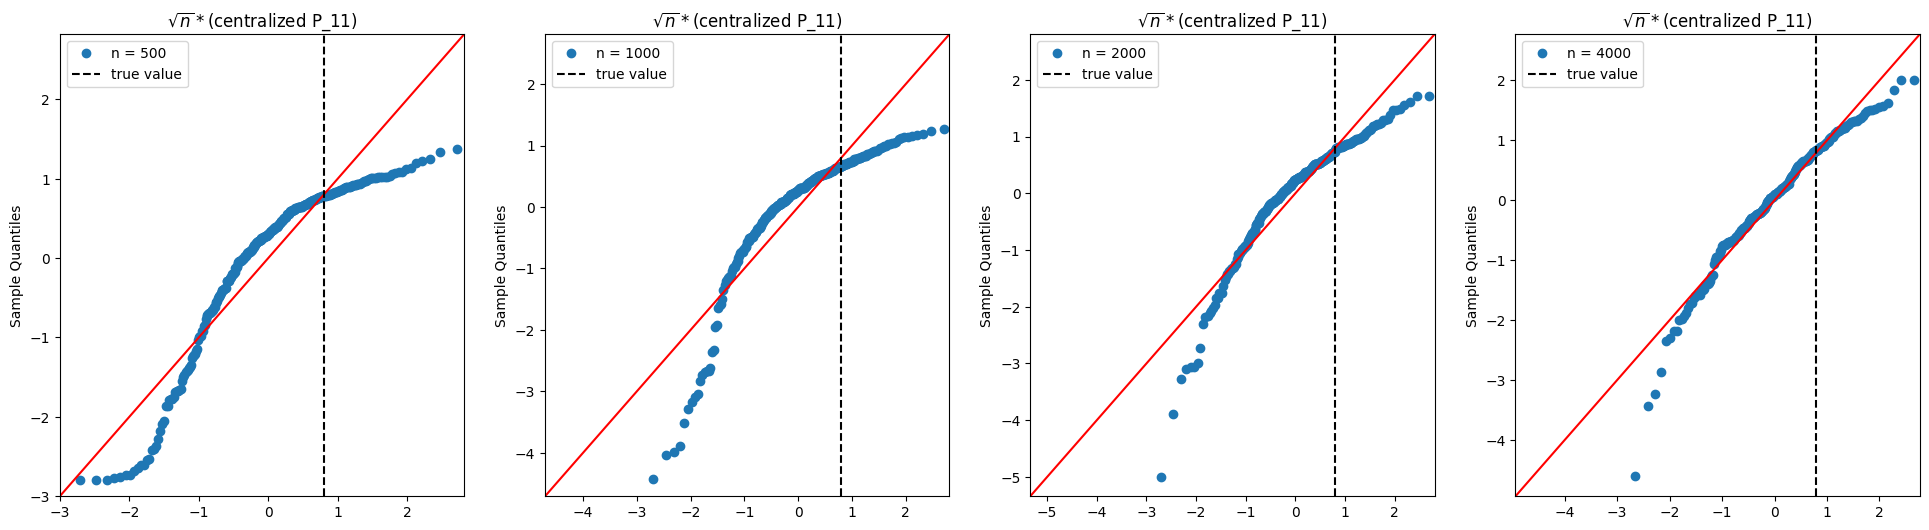

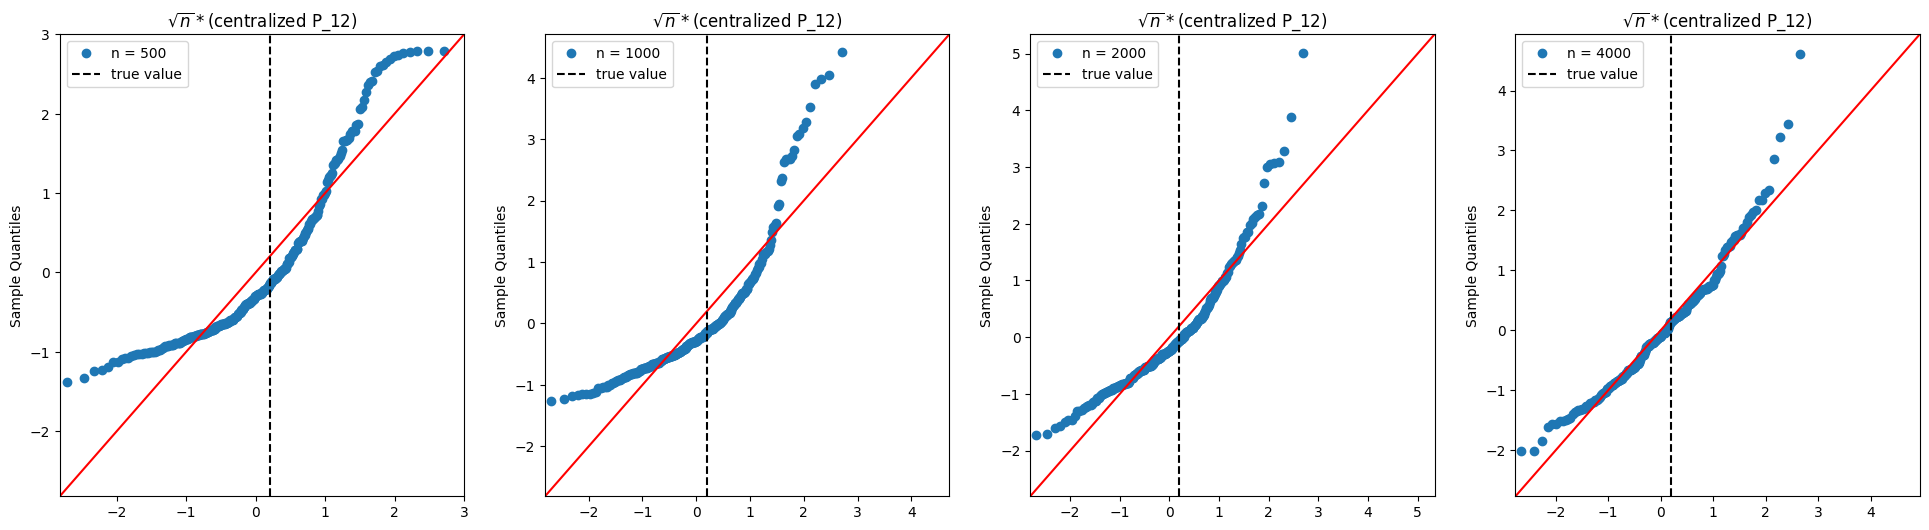

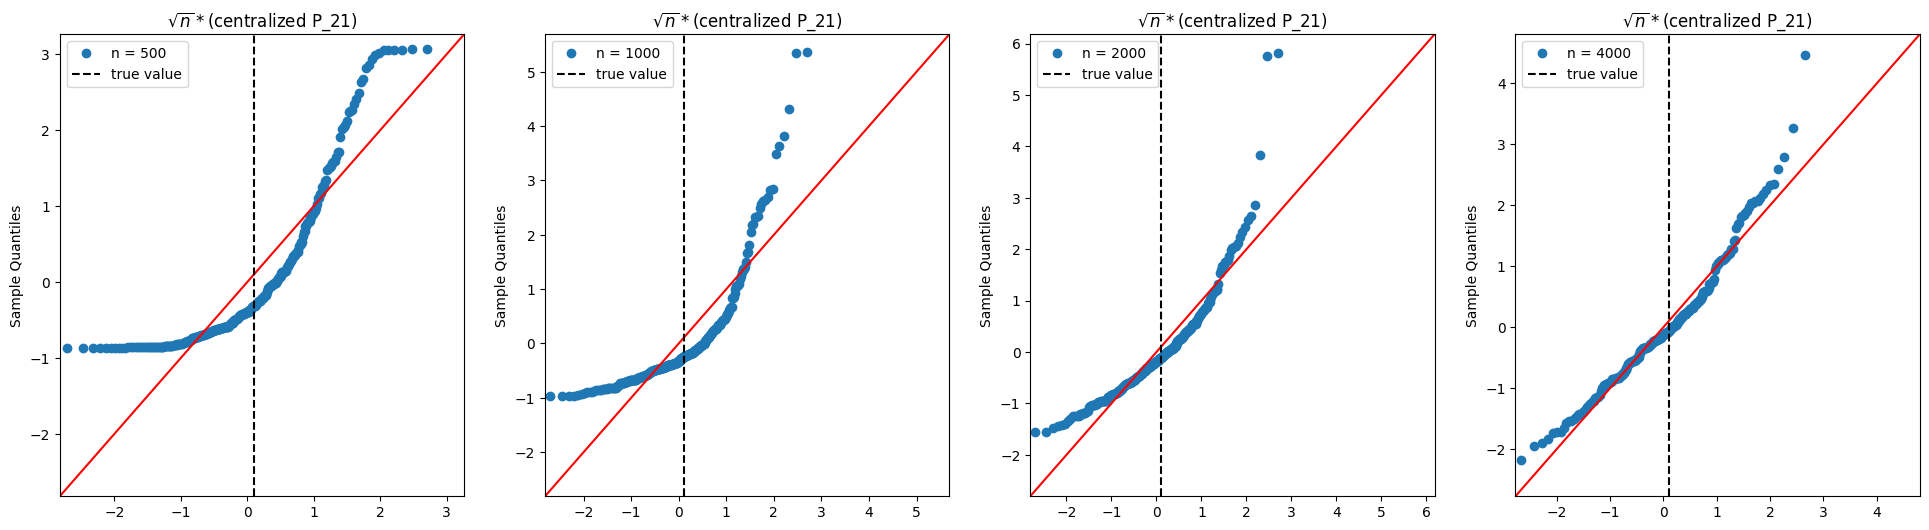

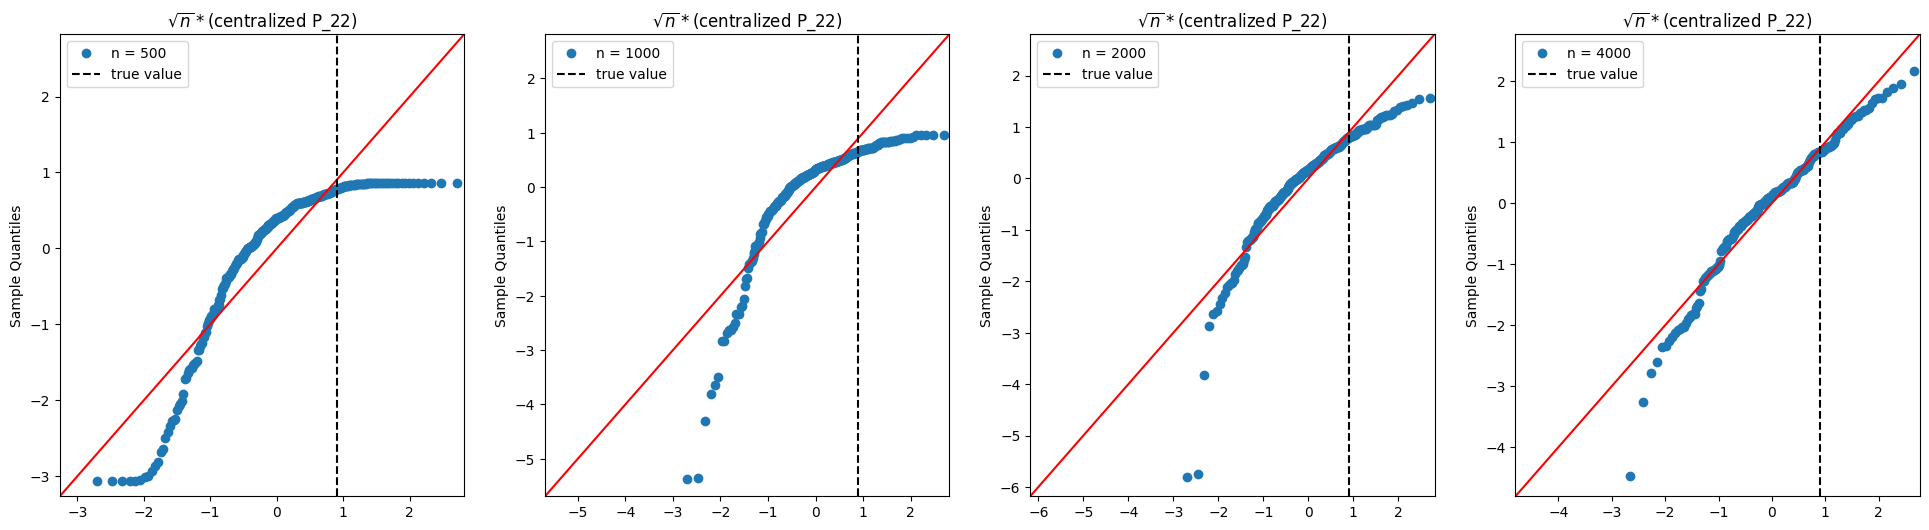

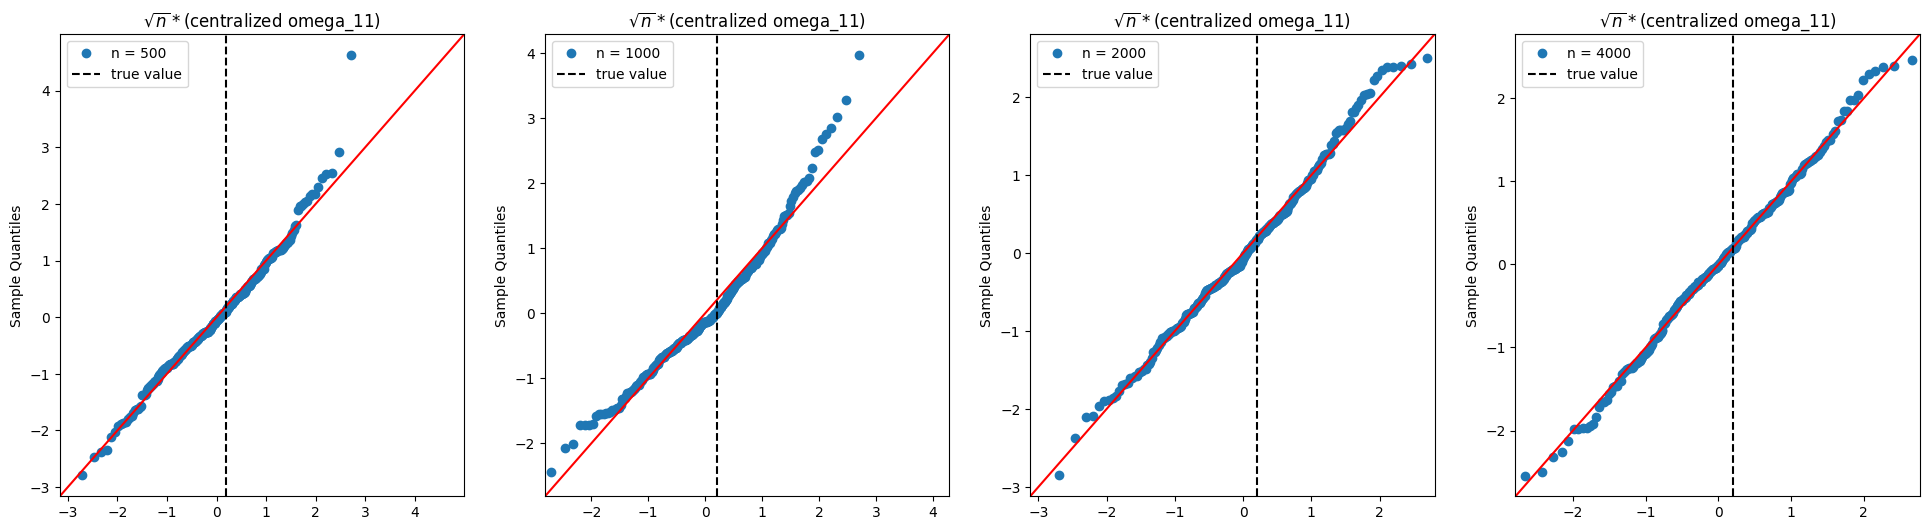

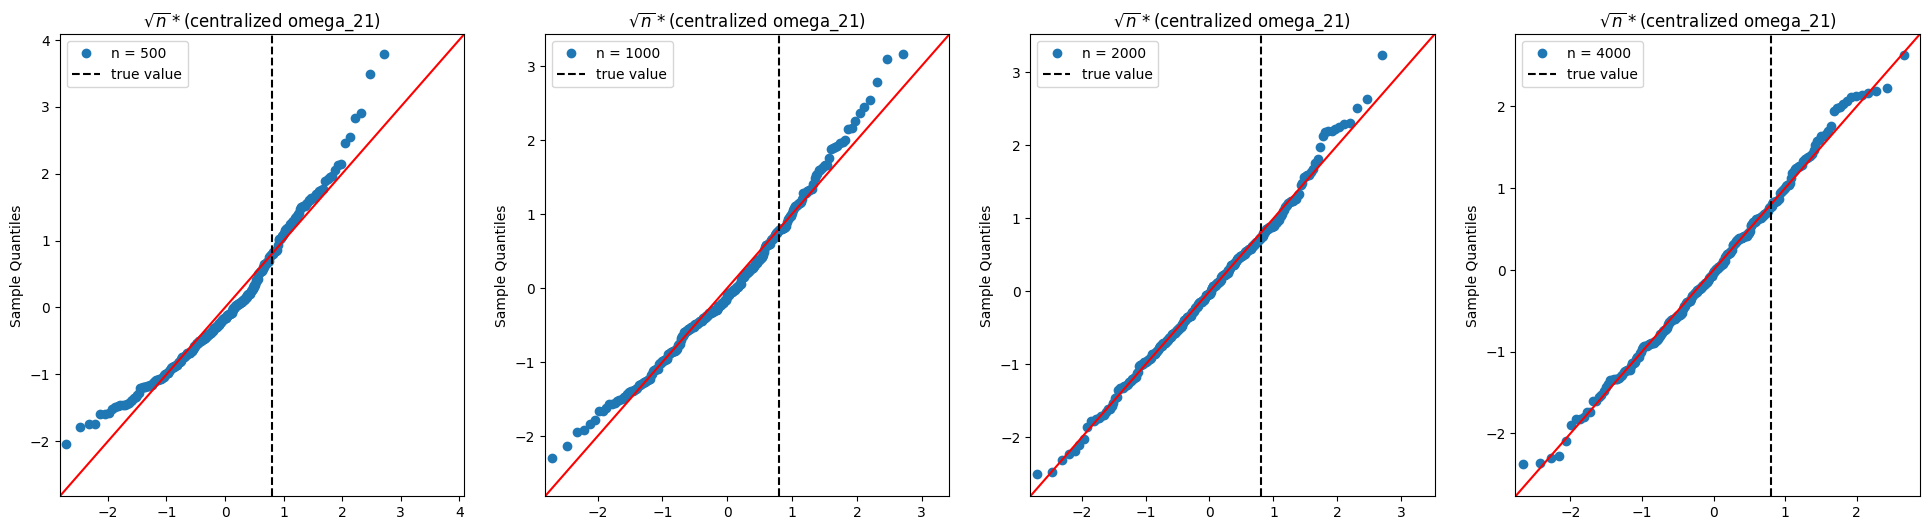

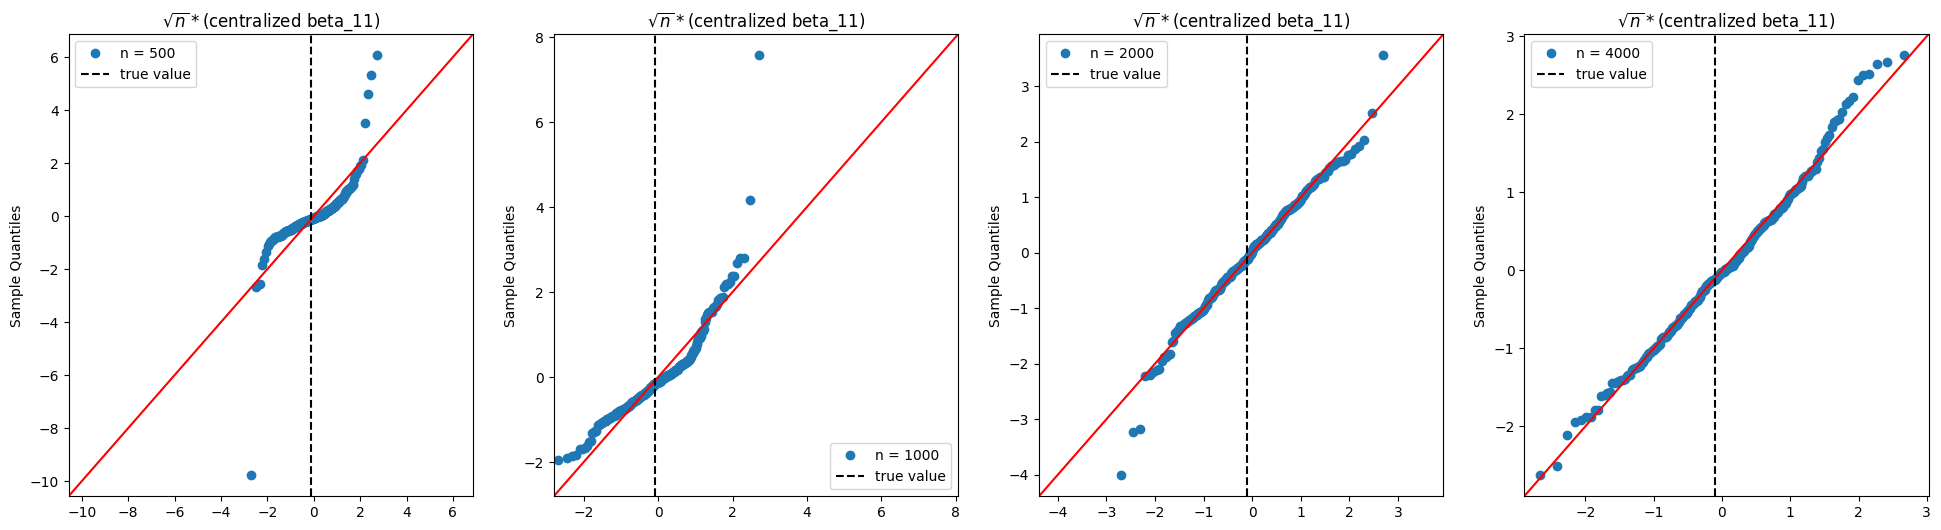

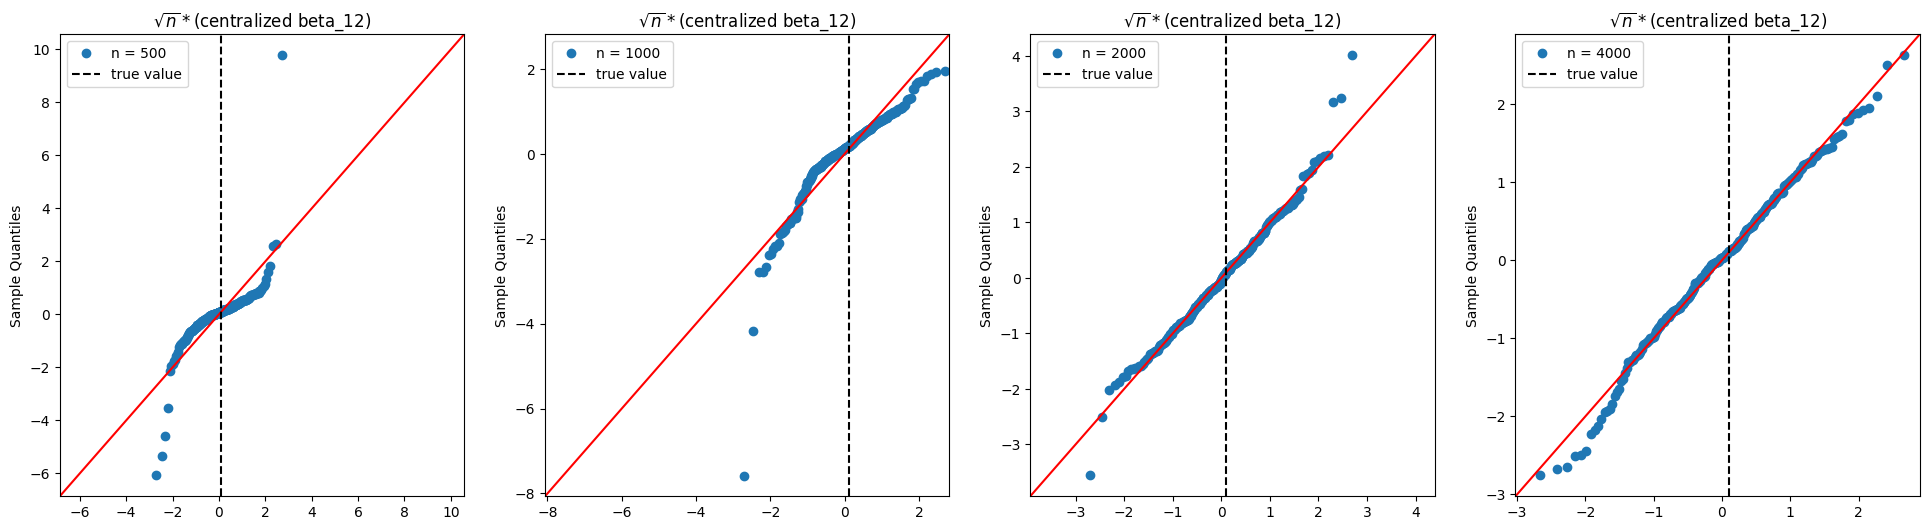

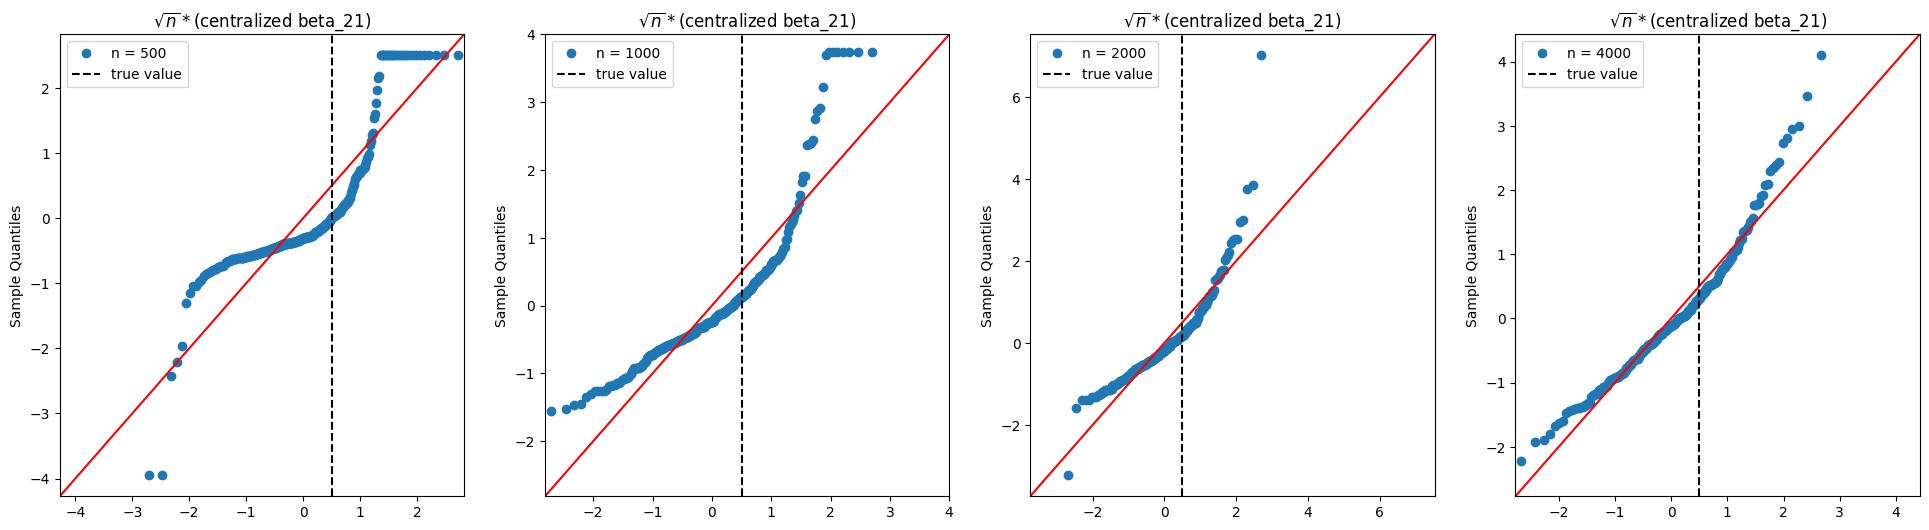

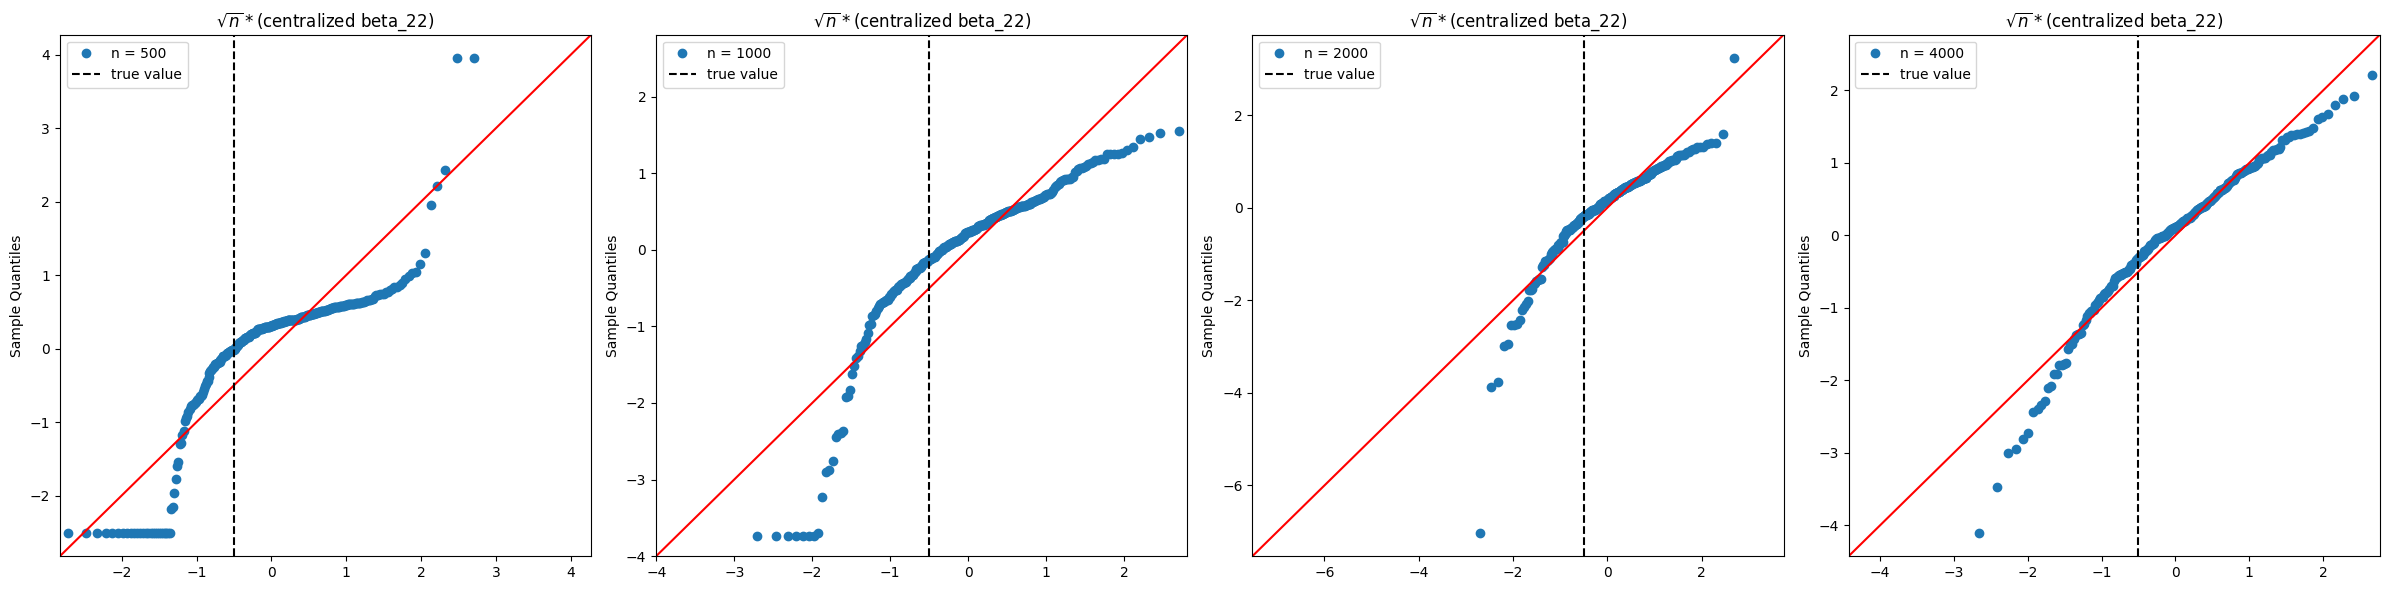

In [393]:
Colors = generate_colors(len(Sample_sizes))
#fig,axs = plt.subplots((true_values.columns),1,figsize=(45,15))
for idx,col in enumerate(true_values.columns):
    fig,axs = plt.subplots(1,len(Sample_sizes),figsize=(24,6))
    for j,sample_size in enumerate(Sample_sizes):
        to_plot = df.loc[400].dropna(axis=0).query('sample_size == @sample_size').dropna(axis=0)[col]
        sm.qqplot((to_plot- to_plot.mean())/to_plot.std(),line='45',label=f'n = {sample_size}',ax=axs[j])
        #sns.histplot(np.sqrt(sample_size)*(to_plot-to_plot.mean()))
        axs[j].axvline(true_values[col].squeeze(),color='black',linestyle='--',label='true value')
        axs[j].set_title(f'$\\sqrt{{n}}*$(centralized {col})')
        axs[j].set_xlabel('')  # Hides the entire x-axis
        axs[j].legend()
plt.tight_layout()

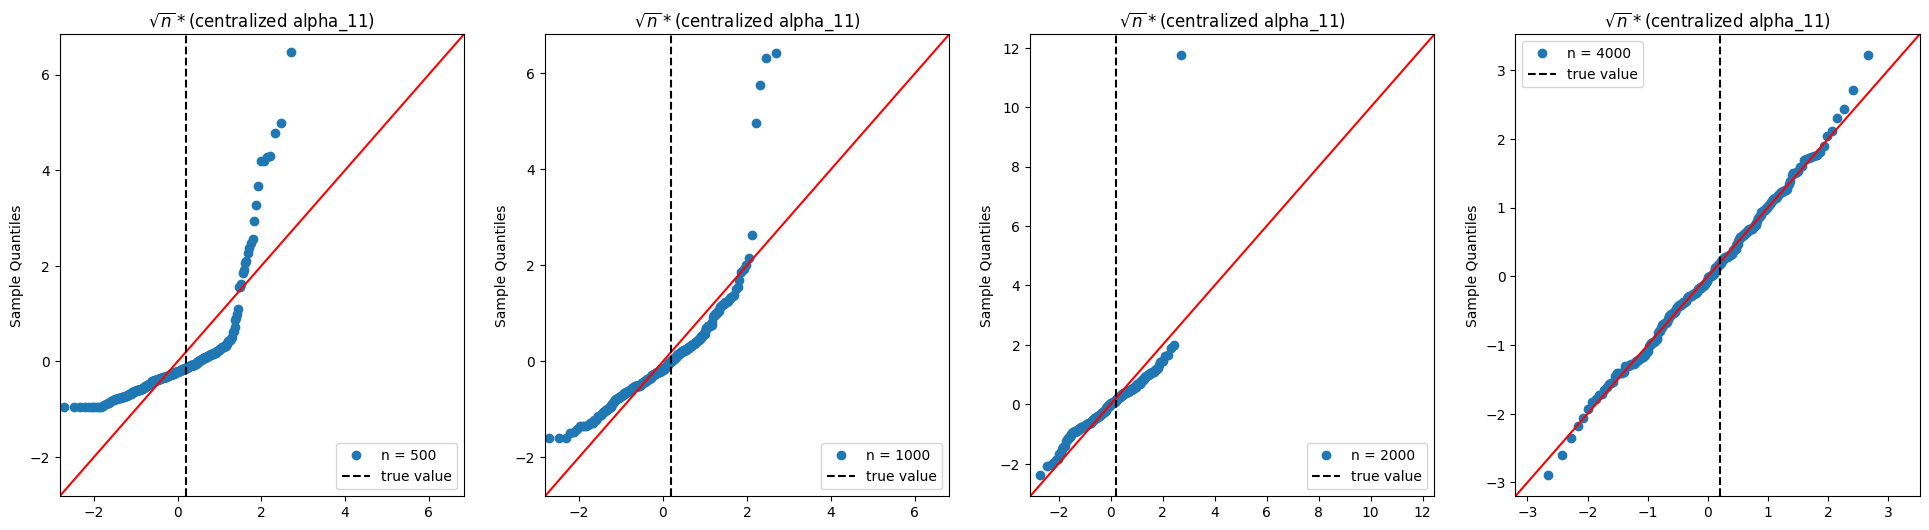

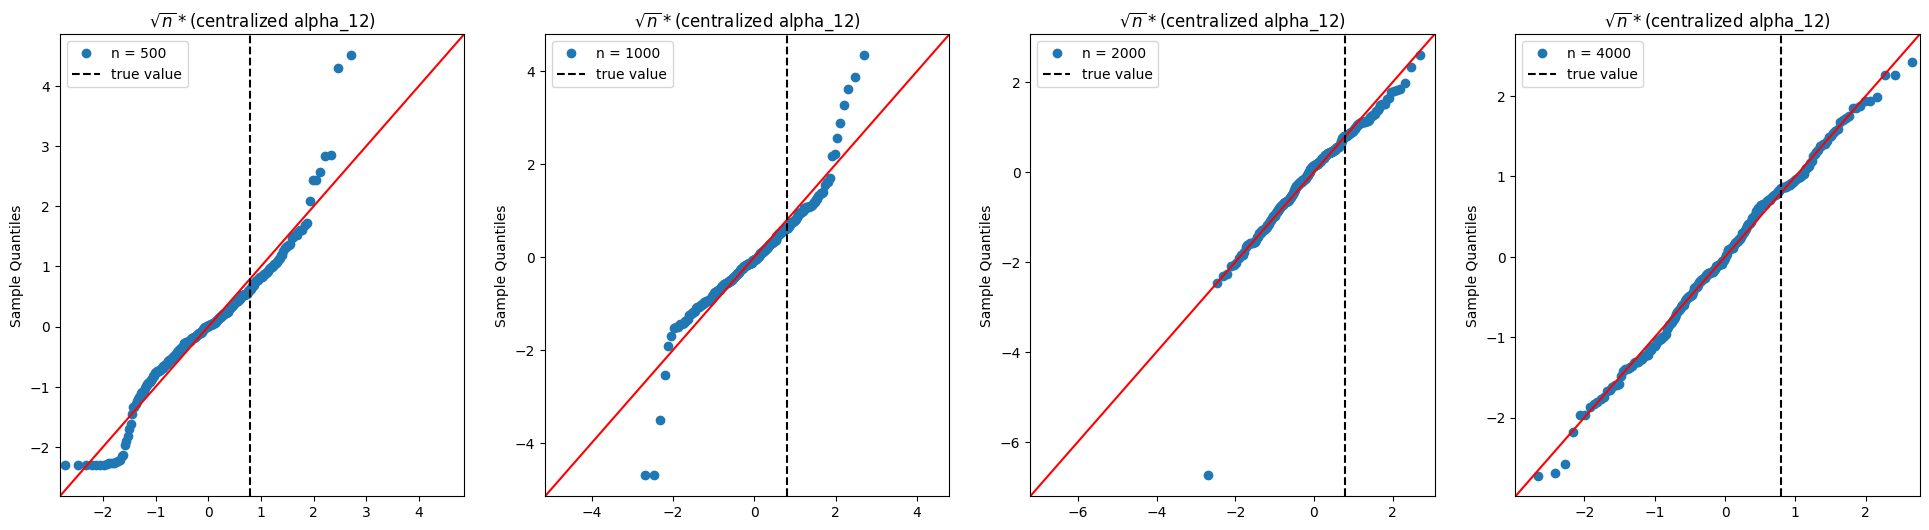

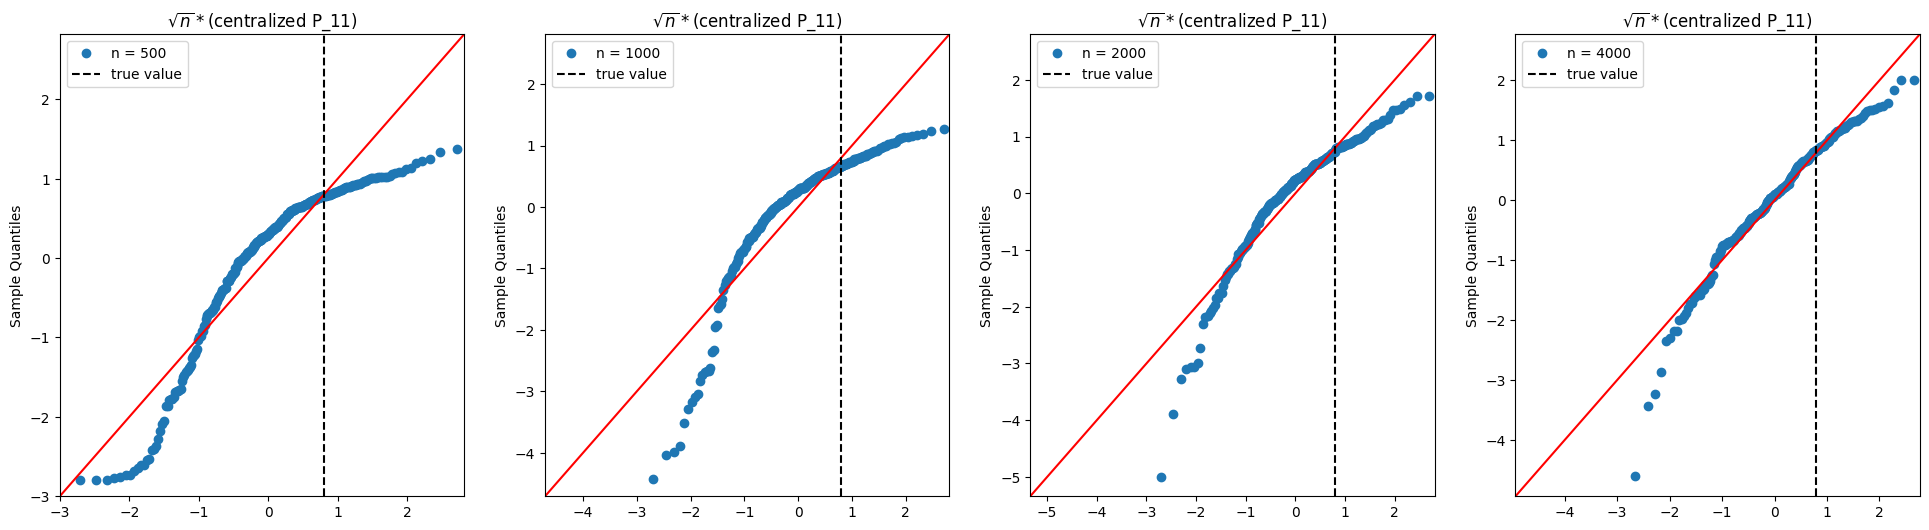

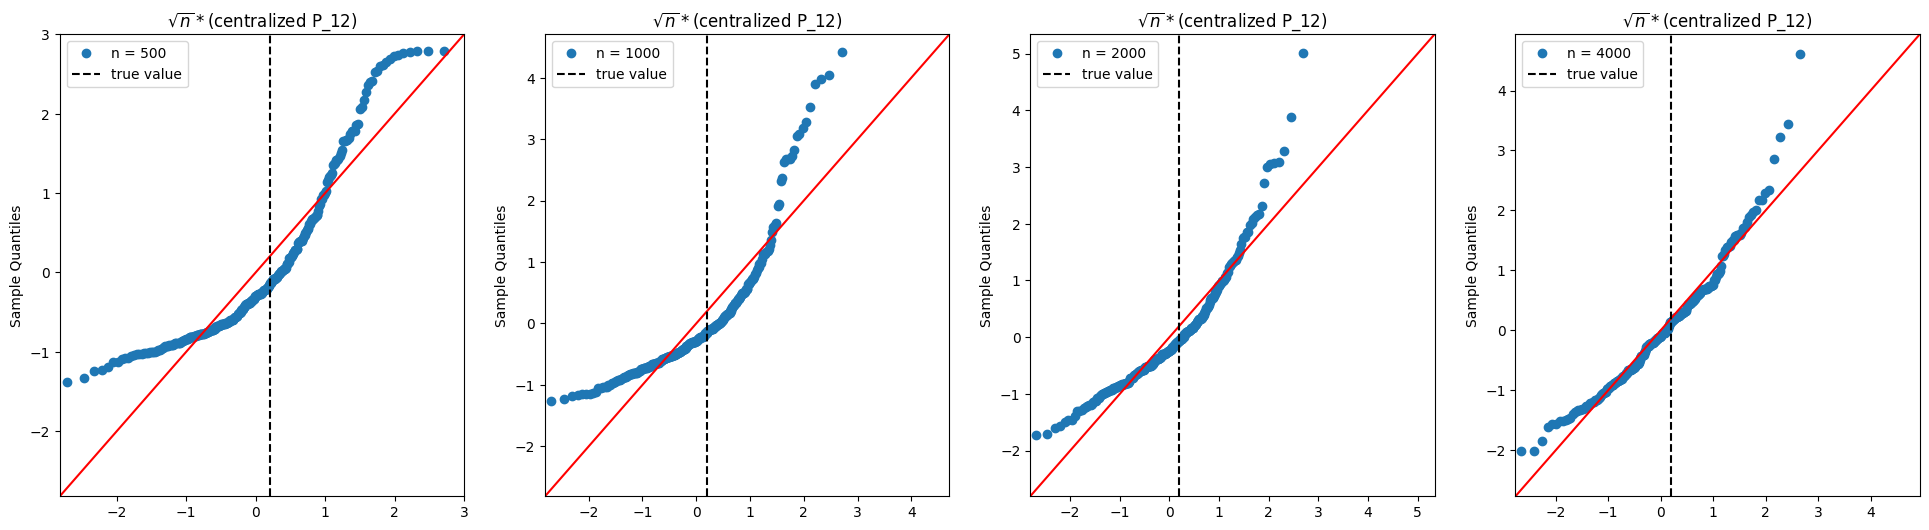

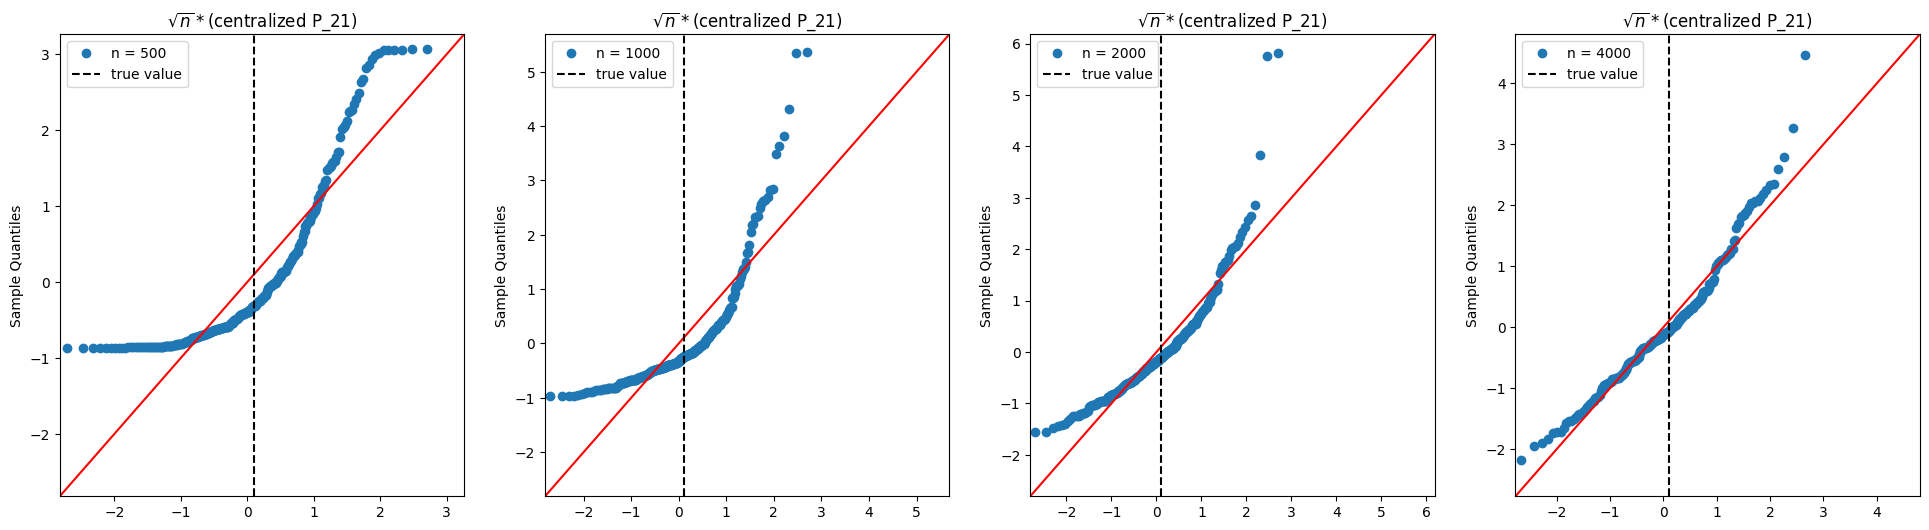

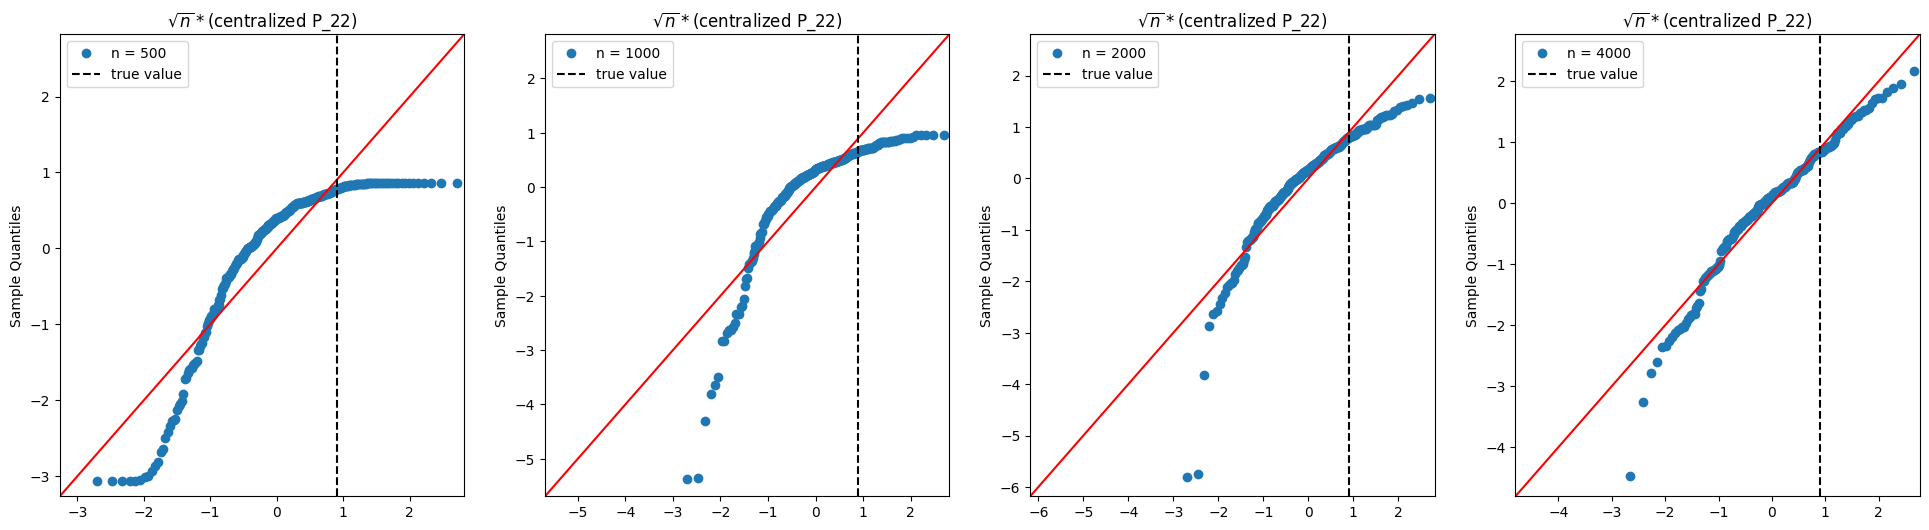

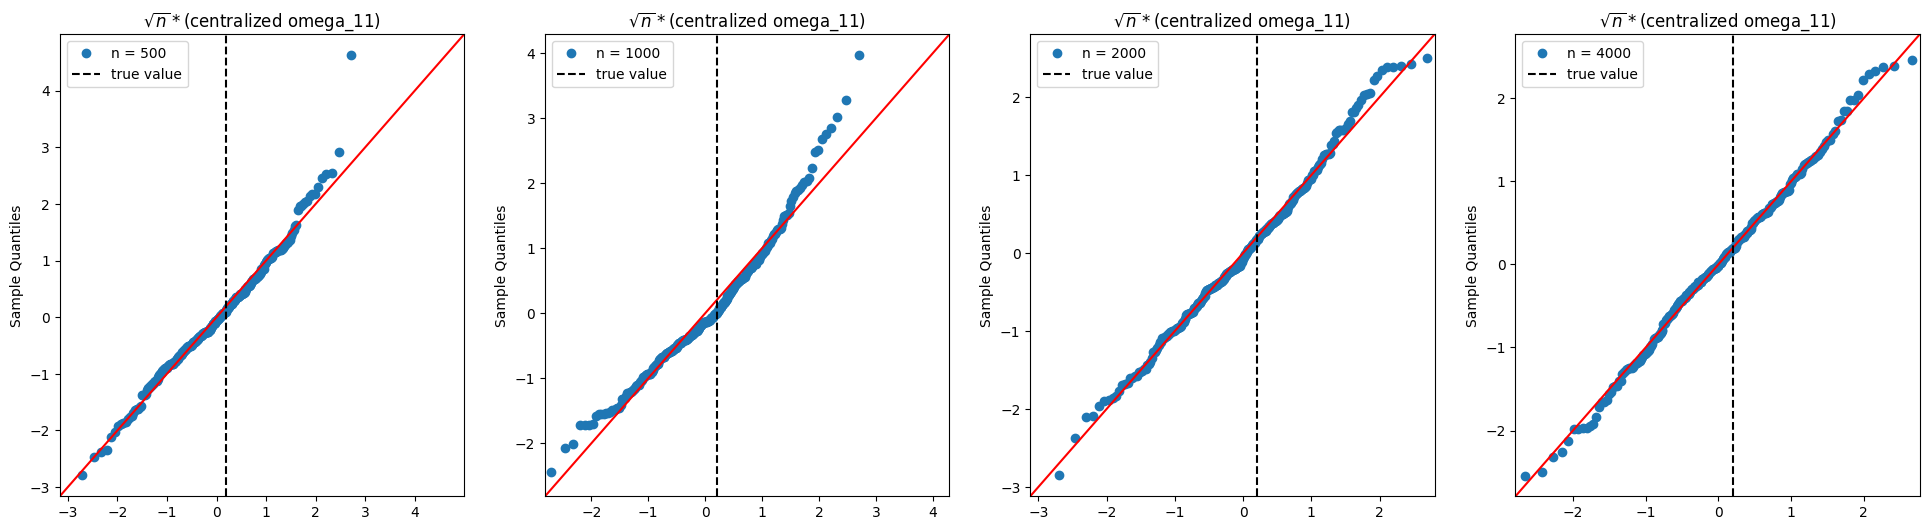

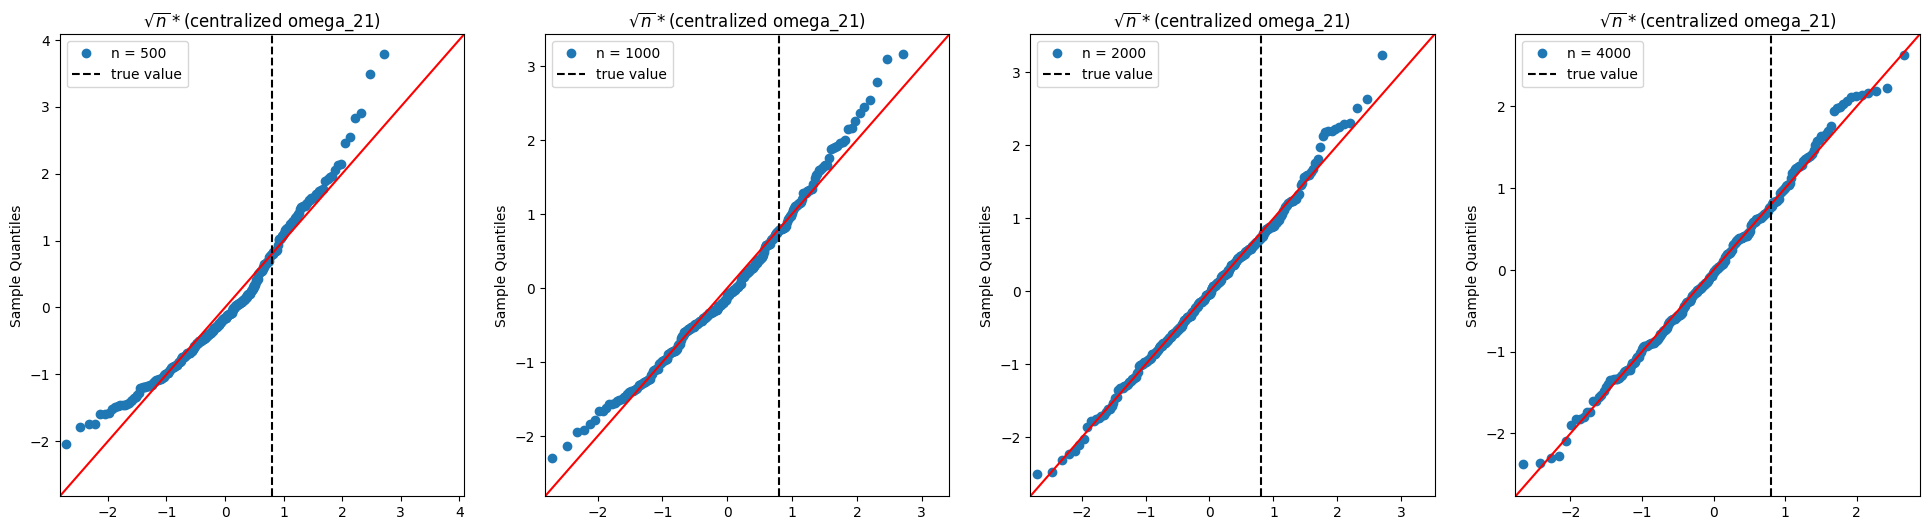

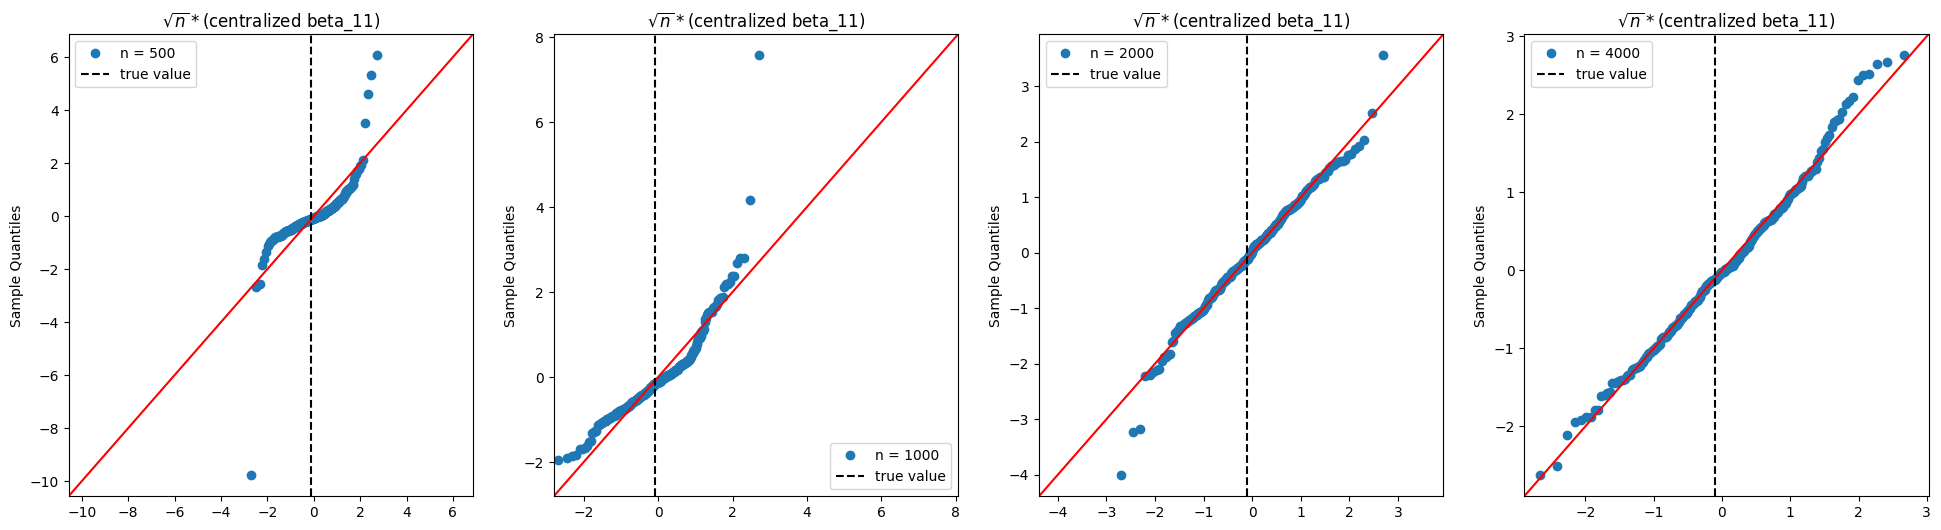

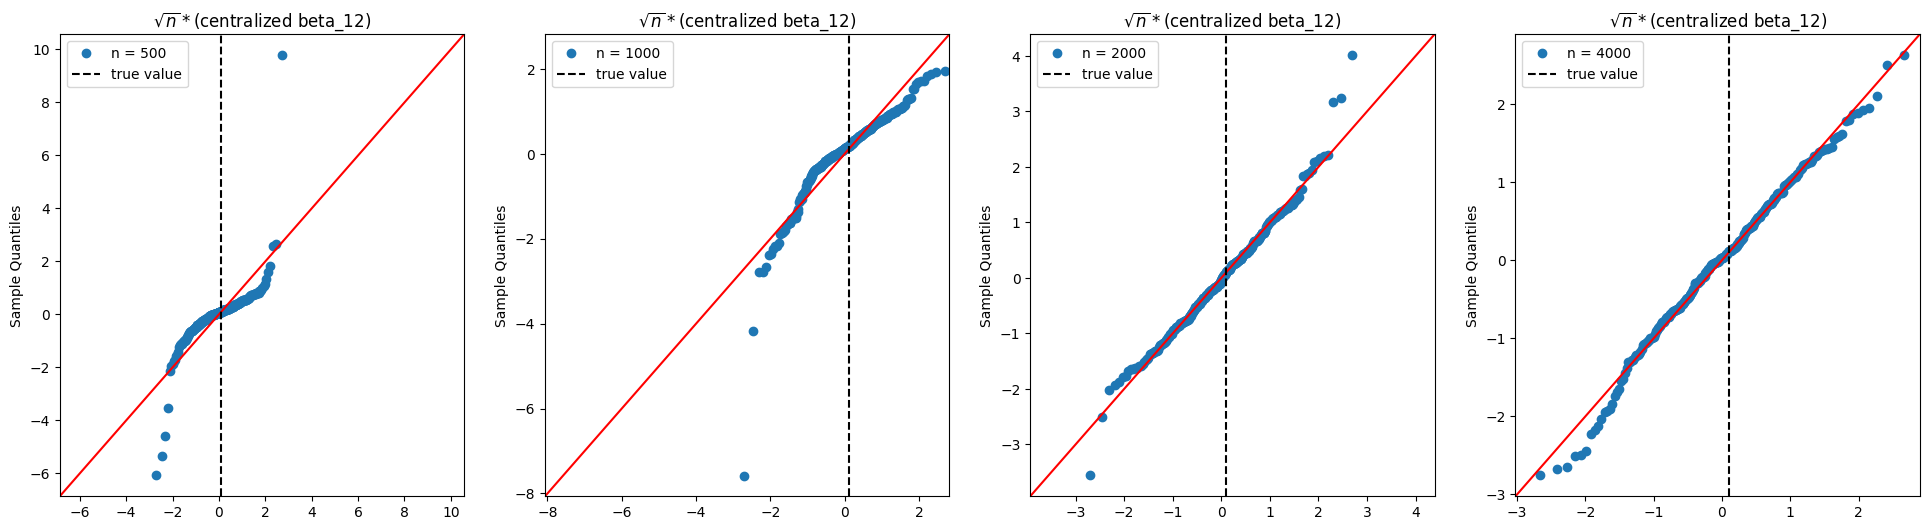

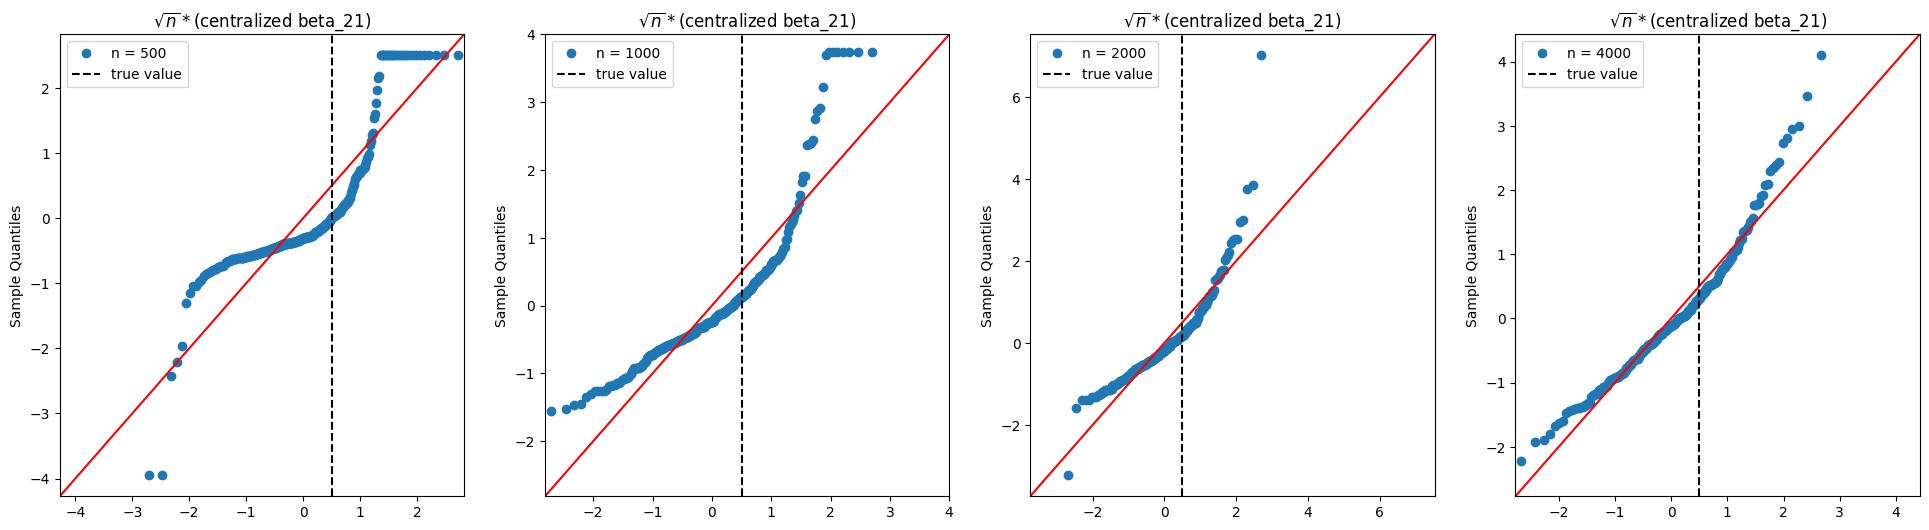

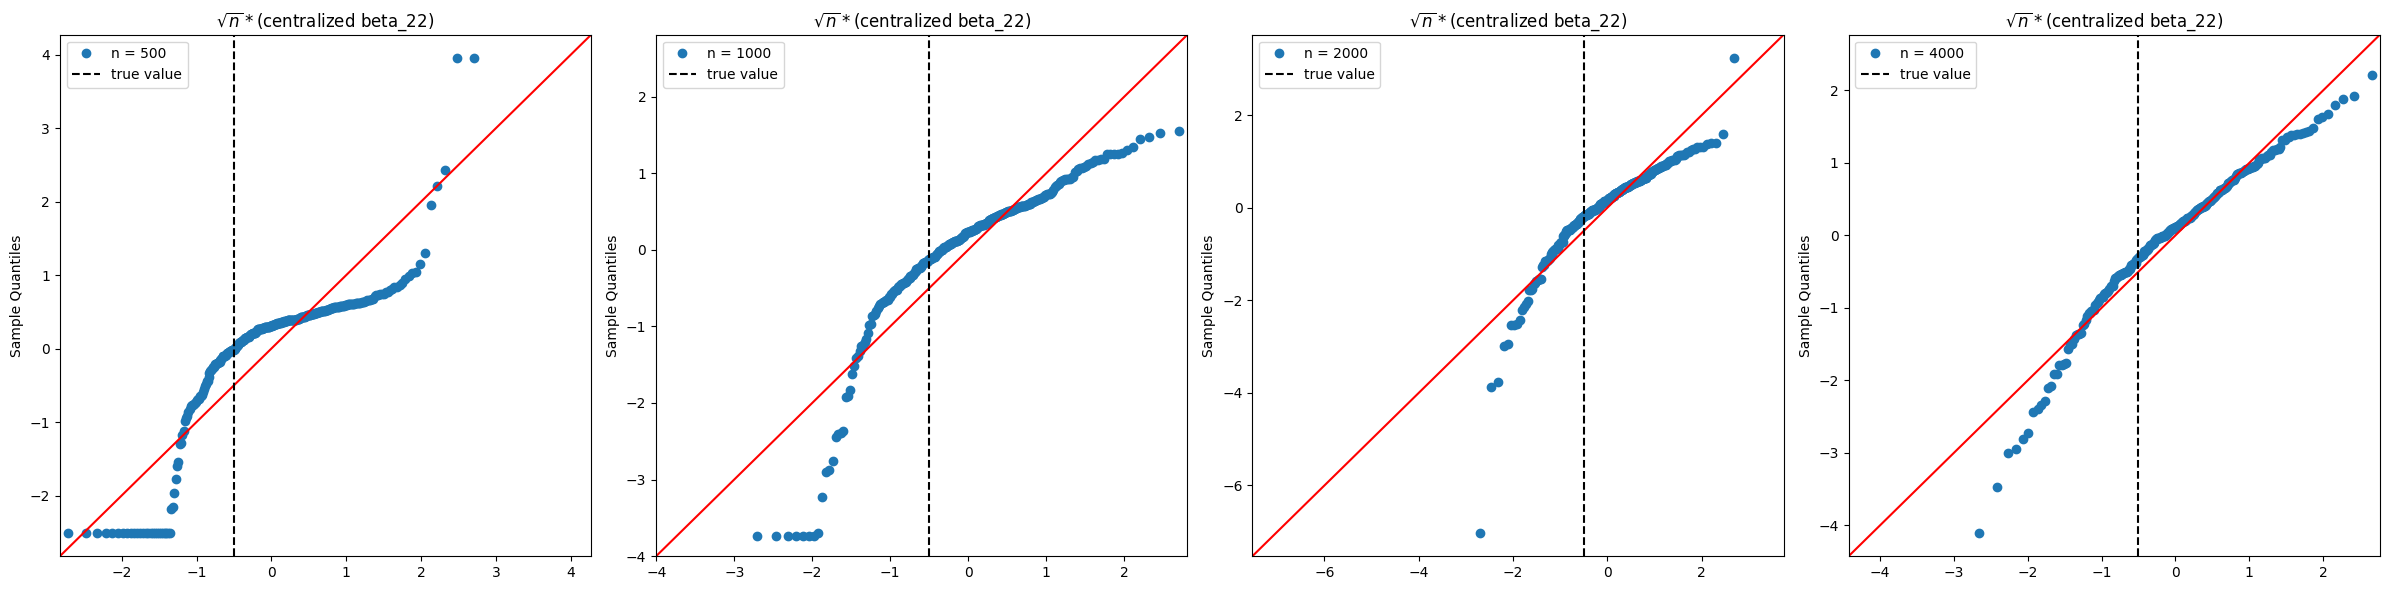

In [41]:
Colors = generate_colors(len(Sample_sizes))
#fig,axs = plt.subplots((true_values.columns),1,figsize=(45,15))
for idx,col in enumerate(true_values.columns):
    fig,axs = plt.subplots(1,len(Sample_sizes),figsize=(24,6))
    for j,sample_size in enumerate(Sample_sizes):
        to_plot = df.loc[400].dropna(axis=0).query('sample_size == @sample_size').dropna(axis=0)[col]
        sma.qqplot((to_plot- to_plot.mean())/to_plot.std(),line='45',label=f'n = {sample_size}',ax=axs[j])
        #sns.histplot(np.sqrt(sample_size)*(to_plot-to_plot.mean()))
        #axs[j].axvline(true_values[col].squeeze(),color='black',linestyle='--',label='true value')
        axs[j].set_title(f'$\\sqrt{{n}}*$(centralized {col})')
        axs[j].set_xlabel('')  # Hides the entire x-axis
        axs[j].legend()
plt.tight_layout()

## PIT TEST
Conditionné au passé, chaque observation suit un mélange de lois normales centrées de variances $\sigma(i)^2$ et de poids $P(\Delta_t=i|X_1,..,X_{t-1},\epsilon_1,..,\epsilon_{t-1})$.\
Ainsi, la cdf de $\epsilon_t$ est donnée par $F(\epsilon_t) = \sum_{i=1}^dF(\epsilon_t|\Delta_t=i)P(\Delta_t=i|X_1,,..,X_{t-1},\epsilon_1,..,\epsilon_{t-1})$

In [14]:
def get_PIT_residuals(eps,params):
    n = len(eps)
    d = len(params['P'])
    pi = MS_hamilton_filter(eps,params,backward_pass=False)
    sigmas = get_sigma(eps,np.arange(len(eps)),params.get('omega'),params.get('alpha'),params.get('exogen_additive'),params.get('mu'))
    residuals = [sum([norm.cdf(eps[t],scale=sigmas[t,i])*pi[t+1,t,i] for i in range(d)]) for t in range(1,n)]
    return residuals

In [15]:
PIT_residuals = get_PIT_residuals(model.eps,true_params)

sns.histplot(PIT_residuals,stat='density')
plt.title(f'KS Test p-value: {round(stats.kstest(PIT_residuals,stats.uniform.cdf).pvalue,3)}')

TypeError: object of type 'NoneType' has no len()

## Détermination des Conditions Initiales
La procédure est la suivante:
1. Calibrer un modèle HMM à proba de transition exogènes -> On devra garder en mémoire les probas de transition, les probas smoothées, les probas initiales, et les variances
2. Utiliser l'algorithme de Vitterbi pour classifier les états
3. Une fois les états classifiés, entraîner un ARCH avec exogénéité sous chaque sous-séquence par QMLE -> on en tirera des paramètres par modèle

Une 4ème étape existe pour déterminer à postériori la distribution des résidus standardisés, une telle approche est cool mais peut s'échapper de notre cadre d'étude, à voir plus tard.


1. vérifier qu'on peut faire exogen_transition sans alpha
2. vérifier qu'on peut faire Vitterbi avec $P$ time-varying
3. Etape implique de faire attention à bien garder les epsilon en mémoire à chaque observation -> peut être chiant à faire. Par aileurs, cette étape parait hyper chiante voire impossible à bien faire pour un GARCH (et en même temps c'est de l'approximation)
- point théorie: Ce serait cool d'avoir des résultats de cv sur HMM et sur ARCH+$\lambda X$ (pas forcément évident avec non-convexité en $X$) -> ça prouverait rien mais ça montrerait qu'on est pas juste en train de déplacer le problème

In [189]:
np.random.seed(27)
sample_size = 4000
true_params =  {'alpha':np.array([[0.1,0.3]]),\
                'P': np.array([[0.8,0.2],[0.1,0.9]]),\
                'omega':np.array([0.2,0.8]),\
                'beta' : np.array([[-0.1,0.1],[0.5,-0.5]]),\
                'mu' : np.array([[0.4,0.2]]),\
                'exogen_additive' : abs(AR([0.9,0.08],length=sample_size)).reshape(sample_size,1),\
                'exogen_transition' : AR([0.9,0.08],length=sample_size),\
                'transition_f' : 'soft-exp',\
                #'seed' : 5,\
                "pi_0":np.array([0.5,0.5])}
true_params['log-likelihood'] = compute_log_likelihood(model.eps,true_params)


#initial_params =    {'pi_0' : np.array([0.5,0.5]),\
#                    'omega' : np.array([0.3,0.7]),\
#                    'P' : np.ones((2,2))/2,\
                    #'alpha' : np.array([[0,0]]),\
                    #'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    #'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    #'transition_f' : 'soft-exp',\
                    #    'beta' : np.array([[0,0],[0,0]]),\
                    #'beta_constraint' : 'general',\
                    #'mu' : np.array([[0.5,0.5]]),\
#                         }

model = MS_ARCH(true_params=true_params)
model.simulate(length=sample_size)

## Step-By-Step

### Etape 0 : Les ingrédients
- la série temporelle sur laquelle on calibre le modèle
- un nombre d'états souhaité $d$
- des paramètres initiaux pour le modèle hmm
- Une variable exogène $X$ (si on le souhaite)

In [526]:
d = 2
q=1
#X = np.random.uniform(0,1,size=(sample_size))

initial_params = {'exogen_transition' : true_params.get('exogen_transition',None),\
                'exogen_additive' : true_params.get('exogen_additive',None),\
#                'exogen_additive' : X.reshape(-1,1)
                  }

calibrate_mu = initial_params.get('exogen_additive',None) is not None
if calibrate_mu:
    initial_params['exogen_additive'] = initial_params['exogen_additive'].reshape(-1,1)
if initial_params.get('exogen_transition',None) is not None:
    initial_params['beta'] = np.zeros((d,d))

### Etape 1: Calibration d'un HMM (avec exogen_transition si requis)

In [527]:
hmm_initial_params = {
                'pi_0' : np.array([0.5,0.5]),\
                'omega' : np.array([0.3,0.7]),\
                'P' : np.ones((2,2))/2,\
                'exogen_transition' : initial_params.get('exogen_transition',None),\
                'beta' : initial_params.get('beta',None),\
                #'beta_constraint' : 'general',\
            }
niter = 100



hmm_results,hmm_pi = MS_EM_algorithm(model.eps,hmm_initial_params,niter=niter,return_pi=True)

hmm_params = hmm_results[niter]

print(hmm_params)

### Ajout des paramètres initiaux
for key in {'P','omega','pi_0','beta'}:
    initial_params[key] = hmm_params.get(key,None)

  0%|          | 0/100 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  1%|          | 1/100 [00:00<00:42,  2.35it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  2%|▏         | 2/100 [00:00<00:37,  2.62it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  3%|▎         | 3/100 [00:01<00:36,  2.63it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize st

{'P': array([[0.963226 , 0.036774 ],
       [0.0690903, 0.9309097]]), 'beta': array([[ 0.06264805, -0.06264805],
       [-0.0720034 ,  0.0720034 ]]), 'omega': array([1.20413267, 3.80985114]), 'pi_0': array([1.e+00, 1.e-10]), 'log-likelihood': -7024.560132276537}


### Etape 2: Algorithme de Vitterbi
A faire, entre-temps on prend juste l'argmax des probas smoothées\
La différence entre les deux est que la méthode argmax prend juste $argmax_s(P_t(s))$ pour tout $t$, tandis que Viterbi prend l'argmax du $n-uplet$, ce qui n'est pas forcément la même chose (Stein).

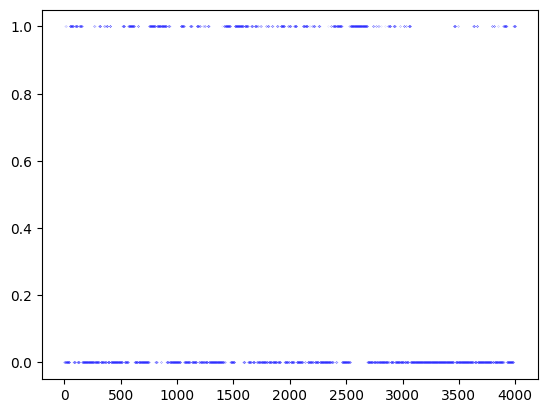

In [528]:
predicted_states = hmm_pi[:,-1,:].argmax(axis=1)[1:]
plt.plot(predicted_states,label='Predicted states',color='blue',alpha=0.5,linestyle='',marker='o',markersize=0.1,linewidth=0.1)

In [529]:
sub_sequence = {}
for state in range(d):
    sub_sequence[state] = model.eps[predicted_states == state]

### Etape 3: Estimation QMLE de chaque modèle ARCH-X
On cherche à maximiser la quantité $I_n(\theta) = \frac{1}{n}\sum_{i=1}^nl_t$ avec $l_t := \frac{\epsilon_t^2}{\sigma_t^2}+\log\sigma_t^2$\
Une strat de code peut être de calculer chaque $l_t$ et ensuite d'appliquer une fonction weighted_QMLE(l,weights)

In [530]:
def get_QMLE_ARCH(eps,params):
    n = len(eps)
    vars = get_sigma(eps,np.arange(0,n),np.array([params.get('omega')]),params.get('alpha',np.array([0])),params.get('exogen_additive',None),params.get('mu',None),var=True).reshape(-1)
    QMLE = model.eps**2/vars + np.log(vars)
    return QMLE

In [562]:
def weighted_calibration(eps,params,weights,calibrate_mu):
   
    q = len(params.get('alpha',[]))
    
    def to_minimize(x):
        omega = x[0]
        alpha = x[1:1+q].reshape((q,1)) if q>0 else None
        mu = x[q+1:].reshape((-1,1)) if calibrate_mu else None
        p_ = {'omega':omega,'alpha':alpha,'mu':mu,'exogen_additive':params.get('exogen_additive',None)}
        QMLE = get_QMLE_ARCH(eps,p_)
        return sum(QMLE*weights)
    
    x0 = np.concatenate([params['omega'],params.get('alpha',np.array([0])).reshape(-1),np.array([0]) if calibrate_mu else np.array([])])
    bounds = [(1e-3, None)]
    if q>0:
        bounds += [(0, 1)] * q
    if params.get('mu',None) is not None:
        bounds += [(0,None)]
    result = minimize(to_minimize,x0,method='L-BFGS-B',bounds=bounds).x
    store_results = {'omega':result[0],'alpha':result[1:1+q].reshape((q,1)) if q>0 else None,'mu':result[q+1:].reshape((-1,1)) if calibrate_mu else None}
    return store_results
    

#### Version 1. Calibration par groupes d'états (sans Viterbi)

In [563]:
q=1
weights = {}
initial_arch_params = defaultdict(lambda:{})
arch_params = defaultdict(lambda:{})
for idx in range(d):
    weights[idx] = predicted_states == idx
    initial_arch_params[idx] = {'omega':np.array([hmm_params['omega'][idx]]),'alpha':np.array([0]),'mu':np.array([0])\
                                         if calibrate_mu else None,'exogen_additive':initial_params.get('exogen_additive',None)}
    arch_params[idx] = weighted_calibration(model.eps,initial_arch_params[idx],weights[idx],calibrate_mu)

#### Version 2. Calibration par QMLE Weighted

In [564]:
q=1
weights = {}
initial_arch_params = defaultdict(lambda:{})
arch_params2 = defaultdict(lambda:{})
for idx in range(d):
    weights[idx] = hmm_pi[:,-1,idx][1:]
    initial_arch_params[idx] = {'omega':np.array([hmm_params['omega'][idx]]),'alpha':np.array([0]),'mu':np.array([0])\
                                         if calibrate_mu else None,'exogen_additive':initial_params.get('exogen_additive',None)}
    arch_params2[idx] = weighted_calibration(model.eps,initial_arch_params[idx],weights[idx],calibrate_mu)

### Ecriture du vecteur initial

In [568]:
initial_params['omega'] = np.concatenate([np.array([arch_params2[idx]['omega']]) for idx in range(d)])
initial_params['alpha'] = np.concatenate([np.array([arch_params2[idx]['alpha']]) for idx in range(d)]).reshape(q,d)
if calibrate_mu:
    initial_params['mu'] = np.concatenate([np.array([arch_params2[idx]['mu']]) for idx in range(d)]).reshape(-1,d)

### Calibration à partir du vecteur initial

In [582]:
niter = 500
result = MS_EM_algorithm(model.eps,initial_params,niter=niter)

mu of dimension 2: will depend on delta


  2%|▏         | 8/500 [00:03<03:42,  2.21it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  2%|▏         | 12/500 [00:05<03:32,  2.29it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  3%|▎         | 13/500 [00:06<03:33,  2.28it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  3%|▎         | 14/500 [00:06<03:31,  2.29it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Va

In [583]:
result[niter]

{'P': array([[0.89049074, 0.10950926],
        [0.10869963, 0.89130037]]),
 'beta': array([[-0.07073057,  0.07073057],
        [ 0.27781799, -0.27781799]]),
 'omega': array([0.24561351, 0.91785472]),
 'alpha': array([[0.08605437, 0.30296844]]),
 'mu': array([[0.45638687, 0.14490429]]),
 'pi_0': array([1.e+00, 1.e-10]),
 'log-likelihood': -6863.962949310663}

In [581]:
result_cheat[0]

{'alpha': array([[0.1, 0.3]]),
 'P': array([[0.8, 0.2],
        [0.1, 0.9]]),
 'omega': array([0.2, 0.8]),
 'beta': array([[-0.1,  0.1],
        [ 0.5, -0.5]]),
 'mu': array([[0.4, 0.2]]),
 'exogen_additive': array([[1.        ],
        [2.18560542],
        [1.7434915 ],
        ...,
        [6.23050649],
        [5.40786186],
        [6.18493474]]),
 'exogen_transition': array([1.        , 0.42206976, 0.37581739, ..., 2.10648148, 2.51915276,
        2.14403031]),
 'transition_f': 'soft-exp',
 'pi_0': array([0.5, 0.5]),
 'mu_depends_on_delta': True,
 'log-likelihood': -6868.306359606331}

In [579]:
result_cheat = MS_EM_algorithm(model.eps,true_params,niter=niter)

mu of dimension 2: will depend on delta


  0%|          | 0/100 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  1%|          | 1/100 [00:00<00:51,  1.93it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  2%|▏         | 2/100 [00:01<00:49,  2.00it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  4%|▍         | 4/100 [00:01<00:43,  2.21it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize st

## One-Shot

### Les ingrédients
- la série temporelle sur laquelle on calibre le modèle
- un nombre d'états souhaité $d$
- un nombre de lags ARCH souhaité $q$
- des paramètres initiaux pour le modèle hmm (pas nécessaire)
- Une variable exogène $X$ (si on le souhaite), pour la transition et/ou pour l'additiion

In [190]:
def get_QMLE_ARCH(eps,params):
    n = len(eps)
    vars = get_sigma(eps,np.arange(0,n),np.array([params.get('omega')]),params.get('alpha',np.array([0])),params.get('exogen_additive',None),params.get('mu',None),var=True).reshape(-1)
    QMLE = model.eps**2/vars + np.log(vars)
    return QMLE


def weighted_calibration(eps,params,weights,calibrate_mu):
   
    q = len(params.get('alpha',[]))
    print(q)
    def to_minimize(x):
        omega = x[0]
        alpha = x[1:1+q].reshape((q,1)) if q>0 else None
        mu = x[q+1:].reshape((-1,1)) if calibrate_mu else None
        p_ = {'omega':omega,'alpha':alpha,'mu':mu,'exogen_additive':params.get('exogen_additive',None)}
        QMLE = get_QMLE_ARCH(eps,p_)
        return sum(QMLE*weights)
    
    x0 = np.concatenate([params['omega'],params.get('alpha',np.array([0])).reshape(-1),np.array([0]) if calibrate_mu else np.array([])])
    bounds = [(1e-3, None)]
    if q>0:
        bounds += [(0, 1)] * q
    if params.get('mu',None) is not None:
        bounds += [(0,None)]
    print(bounds)
    result = minimize(to_minimize,x0,method='L-BFGS-B',bounds=bounds).x
    store_results = {'omega':result[0],'alpha':result[1:1+q].reshape((q,1)) if q>0 else None,'mu':result[q+1:].reshape((-1,1)) if calibrate_mu else None}
    return store_results
    


def get_initial_conditions(eps,initial_params,d,q,niter=200):
    # Initial_params doit contenir les informations suivantes:
    ### 'exogen_transition et/ou 'exogen_additive' si besoin
    # On peut aussi spécifier les paramètres suivants, sans quoi ils seront initialisés selon des valeurs standard
    ### 'omega' - array de taille d (optionnel)
    ### 'P' - array de taille dxd (optionnel)
    ### 'pi_0' - array de taille d (optionnel)

        
    calibrate_mu = initial_params.get('exogen_additive',None) is not None
    transition = initial_params.get('exogen_transition',None) is not None
    if calibrate_mu:
        initial_params['exogen_additive'] = initial_params['exogen_additive'].reshape(-1,1)
    if transition:
        initial_params['beta'] = np.zeros((d,d))
    
    hmm_initial_params = {
                'pi_0' : initial_params.get('pi_0',np.array([1/d]*d)),\
                'omega' :initial_params.get('omega',np.array([0.3,0.7]) if d==2 else np.array([0.5]*d)),\
                'P' : initial_params.get('P',np.ones((d,d))/d),\
                'exogen_transition' : initial_params.get('exogen_transition',None),\
                'beta' : initial_params.get('beta',None),\
                #'beta_constraint' : 'general',\
            }
    
    hmm_results = MS_EM_algorithm(eps,hmm_initial_params,niter=niter,return_pi=False)

    hmm_params = hmm_results[niter]

    
    
    #### Viterbi Algorithm
    
    states_sequence = viterbi_continuous(model.eps,hmm_params)
    plt.plot(states_sequence,label='Predicted states',color='blue',alpha=0.5,linestyle='',marker='o',markersize=0.1,linewidth=0.1)
    
    ### Estimation of the ARCH parameters
    
    weights = {}
    initial_arch_params = defaultdict(lambda:{})
    arch_params = defaultdict(lambda:{})
    for idx in range(d):
        #weights[idx] = hmm_pi[:,-1,idx][1:].argmax(axis=1)
        weights[idx] = (idx == states_sequence)
        initial_arch_params[idx] = {'omega':np.array([hmm_params['omega'][idx]]),'alpha':np.array([0]*q),'mu':np.array([0])\
                                            if calibrate_mu else None,'exogen_additive':initial_params.get('exogen_additive',None)}
        arch_params[idx] = weighted_calibration(model.eps,initial_arch_params[idx],weights[idx],calibrate_mu)
        
    for key in {'P','pi_0','beta'}:
        initial_params[key] = hmm_params.get(key,None)    
    for key in {'omega','alpha'}:
        initial_params[key] = np.concatenate([np.array([arch_params[idx][key]]) for idx in range(d)])
    initial_params['alpha'] = initial_params['alpha'].reshape(d,q).T
    if calibrate_mu:
        initial_params['mu'] = np.concatenate([np.array([arch_params[idx]['mu']]) for idx in range(d)]).reshape(-1,d)
    initial_params['predicted_states'] = states_sequence
    return initial_params


In [194]:
params_test = {
    'exogen_additive':true_params.get('exogen_additive',None),\
    'exogen_transition':true_params.get('exogen_transition',None),\
    }

res = get_initial_conditions(model.eps,params_test,2,2,niter=200)

  0%|          | 0/200 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 1/200 [00:00<01:05,  3.03it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  1%|          | 2/200 [00:00<00:57,  3.44it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  2%|▏         | 3/200 [00:00<00:55,  3.52it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize st

2
[(0.001, None), (0, 1), (0, 1), (0, None)]
2
[(0.001, None), (0, 1), (0, 1), (0, None)]


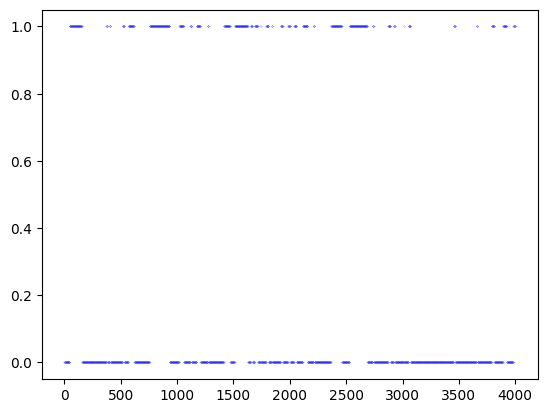

In [195]:
res = get_initial_conditions(model.eps,params_test,2,2,niter=200)

In [197]:
res

{'exogen_additive': array([[1.        ],
        [2.18560542],
        [1.7434915 ],
        ...,
        [6.23050649],
        [5.40786186],
        [6.18493474]]),
 'exogen_transition': array([1.        , 0.42206976, 0.37581739, ..., 2.10648148, 2.51915276,
        2.14403031]),
 'beta': array([[ 0.0626077 , -0.0626077 ],
        [-0.07195041,  0.07195041]]),
 'pi_0': array([1.e+00, 1.e-10]),
 'P': array([[0.96323083, 0.03676917],
        [0.06909645, 0.93090355]]),
 'omega': array([0.70875826, 2.23132855]),
 'alpha': array([[0.09002165, 0.17650053],
        [0.002176  , 0.00779452]]),
 'mu': array([[0.15981112, 0.17857834]]),
 'predicted_states': array([0, 0, 0, ..., 1, 1, 1])}

In [198]:
true_params

{'alpha': array([[0.1, 0.3]]),
 'P': array([[0.8, 0.2],
        [0.1, 0.9]]),
 'omega': array([0.2, 0.8]),
 'beta': array([[-0.1,  0.1],
        [ 0.5, -0.5]]),
 'mu': array([[0.4, 0.2]]),
 'exogen_additive': array([[1.        ],
        [2.18560542],
        [1.7434915 ],
        ...,
        [6.23050649],
        [5.40786186],
        [6.18493474]]),
 'exogen_transition': array([1.        , 0.42206976, 0.37581739, ..., 2.10648148, 2.51915276,
        2.14403031]),
 'transition_f': 'soft-exp',
 'pi_0': array([0.5, 0.5])}

In [199]:
np.mean(abs((1-res['predicted_states'])-model.states))

0.45925

### Calibration à partir du vecteur initial

In [200]:
niter = 300
result = MS_EM_algorithm(model.eps,initial_params,niter=niter)

  0%|          | 0/300 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 1/300 [00:00<02:10,  2.30it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  1%|          | 3/300 [00:01<01:43,  2.87it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  1%|▏         | 4/300 [00:01<01:39,  2.98it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize st

## Full Pipeline

### DGP

In [24]:
np.random.seed(27)
sample_size = 6000
true_params =  {'alpha':np.array([[0.1,0.3]]),\
                'P': np.array([[0.8,0.2],[0.1,0.9]]),\
                'omega':np.array([0.2,0.8]),\
                'beta' : np.array([[-0.01,0.01],[0.05,-0.05]]),\
                'mu' : np.array([[0.4,0.2]]),\
                'exogen_additive' : abs(AR([0.9,0.08],length=sample_size)).reshape(sample_size,1),\
                'exogen_transition' : AR([0.9,0.08],length=sample_size),\
                'transition_f' : 'soft-exp',\
                #'seed' : 5,\
                "pi_0":np.array([0.5,0.5])}

model = MS_ARCH(true_params=true_params)
model.simulate(length=sample_size)
true_params['log-likelihood'] = compute_log_likelihood(model.eps,true_params)

### Calibration

  0%|          | 0/1000 [00:00<?, ?it/s]

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 1/1000 [00:00<08:40,  1.92it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 2/1000 [00:00<07:24,  2.24it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 3/1000 [00:01<07:09,  2.32it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize

2
[(0.001, None), (0, 1), (0, 1), (0, None)]
2
[(0.001, None), (0, 1), (0, 1), (0, None)]
mu of dimension 2: will depend on delta


  0%|          | 0/1000 [00:00<?, ?it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  0%|          | 4/1000 [00:02<09:24,  1.76it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  1%|▏         | 13/1000 [00:07<08:57,  1.84it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)
  2%|▏         | 15/1000 [00:08<08:53,  1.85it/s]/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/optimize/_slsqp_py.py:437: RuntimeWarning: Values 

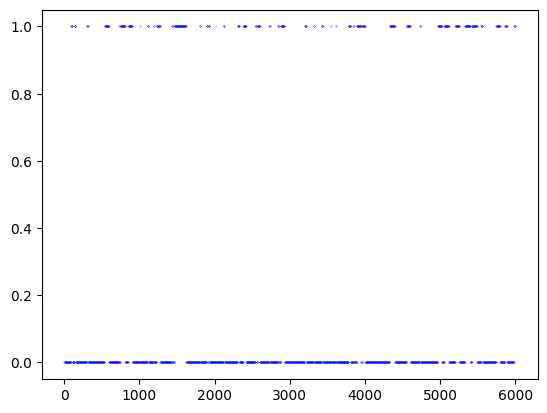

In [25]:
initial_params = {
    'exogen_additive':true_params.get('exogen_additive',None),\
    'exogen_transition':true_params.get('exogen_transition',None),\
    }
d=2
q=1
niter_hmm = 1000
niter_MS = 1000

initial_params = get_initial_conditions(model.eps,initial_params,2,2,niter=niter_hmm)
result = MS_EM_algorithm(model.eps,initial_params,niter=niter_MS)

In [27]:
df = copy(result)
df[0] = {key:value for key,value in df[0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive']}
#result_exogen[0].pop('mu_depends_on_delta')
df_exo = convert_dict_to_dataframe(df)

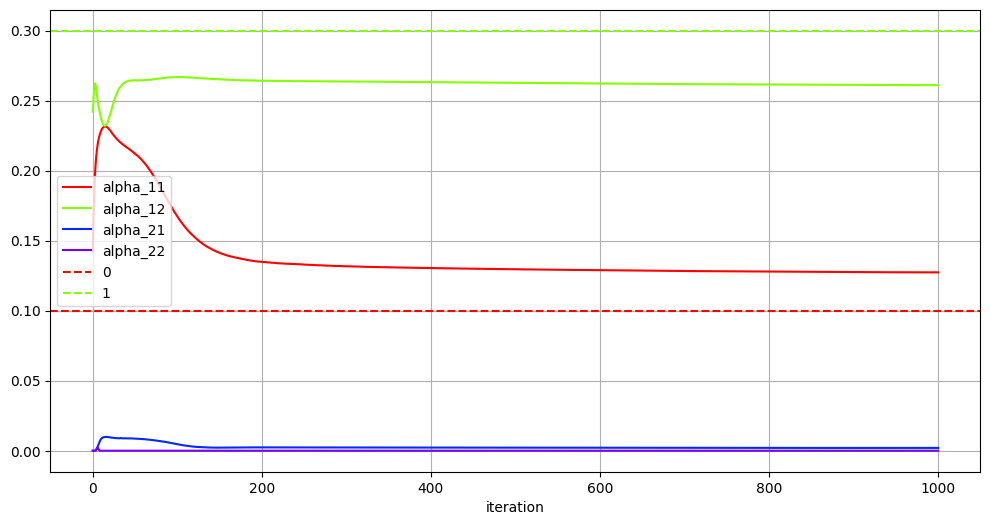

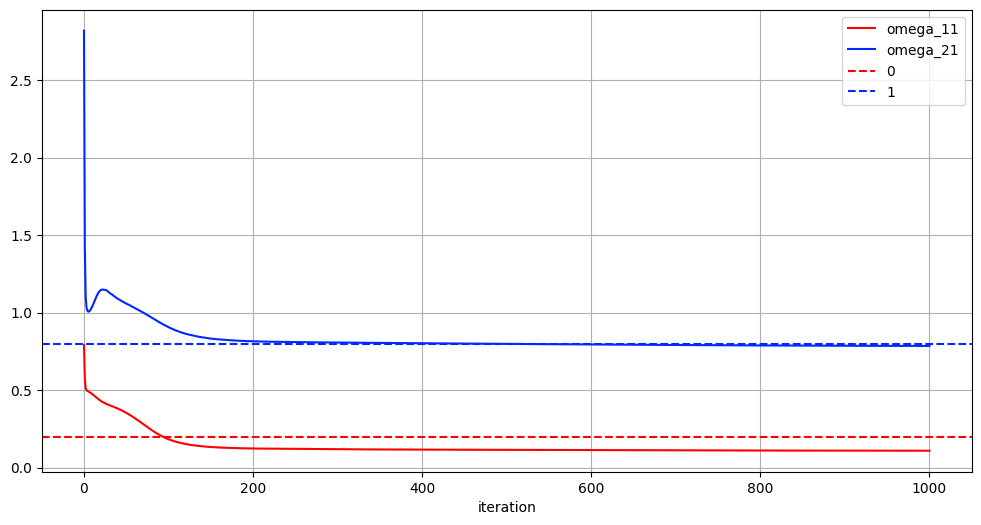

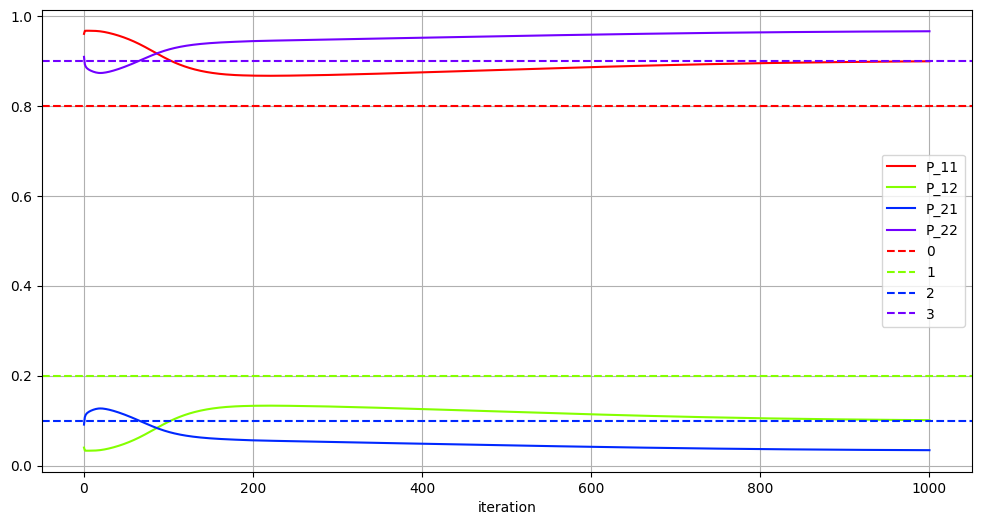

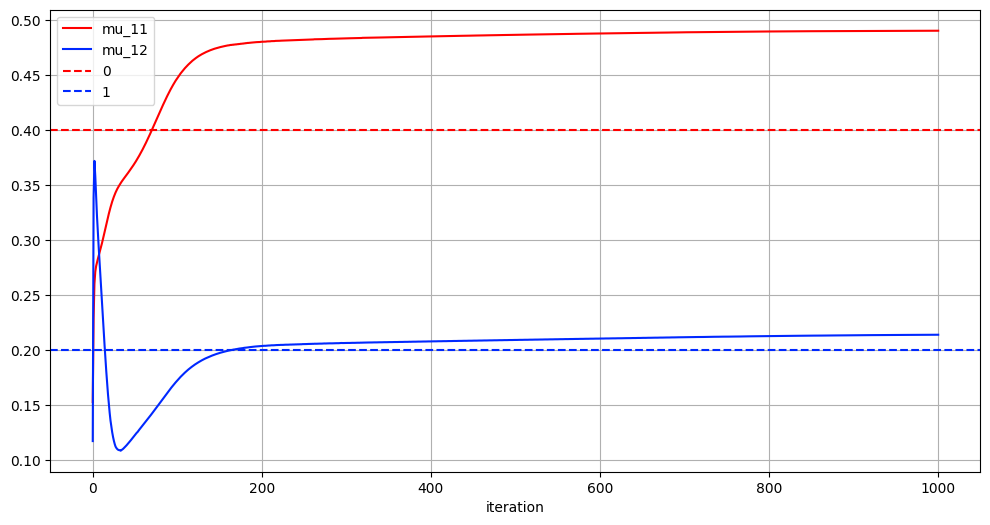

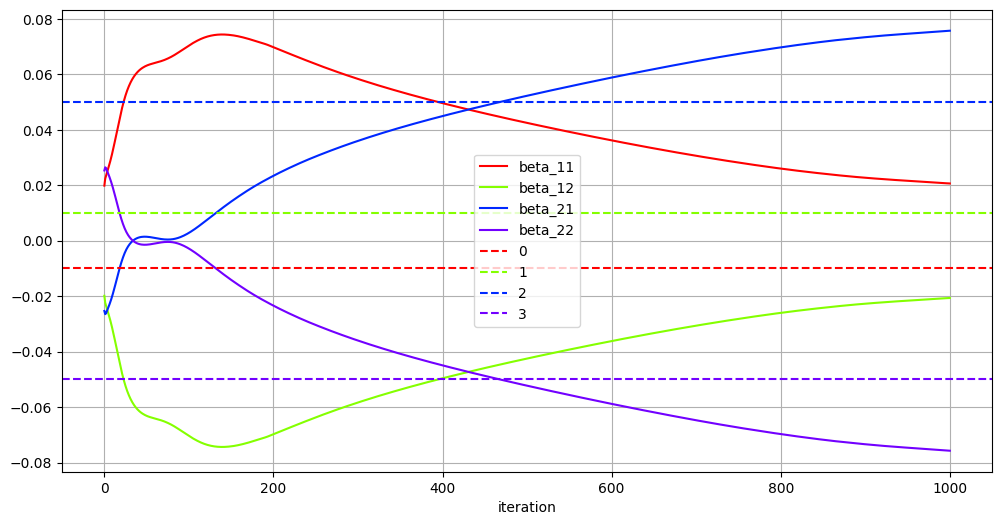

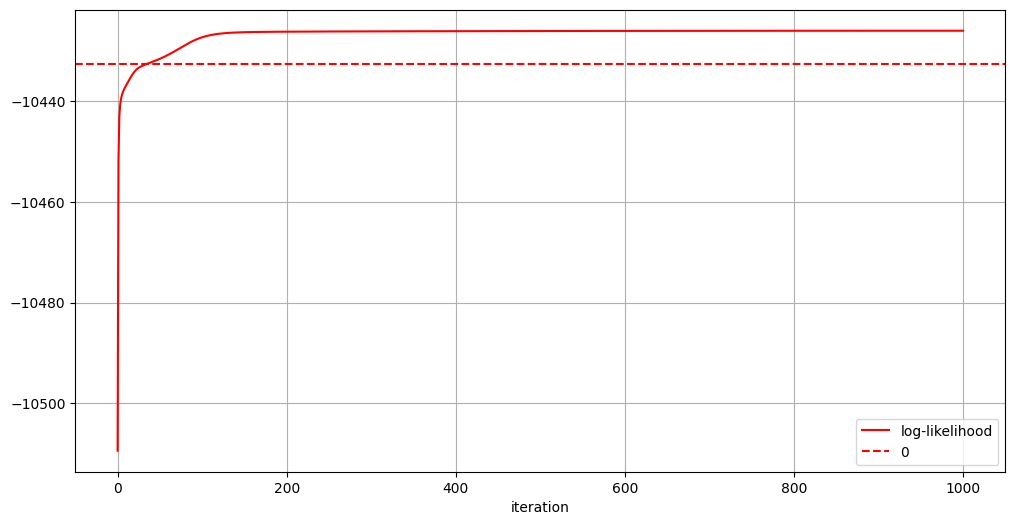

In [28]:
start = 'alpha'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()
start = 'omega'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()
start = 'P'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()
start = 'mu'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()
start = 'beta'
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()
start = 'log-likelihood'
true_params['pi_0'] = np.array([1,0])
true_params['log-likelihood'] = np.array([compute_log_likelihood(model.eps,true_params)])
cols = [col for col in df_exo.columns if col.startswith(start)]
colors = generate_colors(len(cols))
ax = df_exo.plot(y=cols,figsize=(12,6),grid=True,color=colors)
true_val = true_params[start]
for idx,val in enumerate(true_val.ravel()):
    plt.axhline(val,label=idx,color=colors[idx],linestyle='--')
plt.legend()

## Passage en 2D sur exogen_transition

Exogen_transition n'est utilisée que dans un seul calcul: get_transition_matrix, le calcul est donc très simple à fix (on passe d'un * à un manual_matrix_multiply)\
Cependant, la dimension du beta devra passer en 3d, ce qui est un poil chiant -> 
- np.zeros(d,d) devient np.zeros(d,d,k)
- Sans doute refaire le reconstruct_params et le minimize_beta_form
- Pareil pour le create_linear_constraints, dans tout ça faudra bien calculer le nombre de contraintes

-> on commence par tout passer en 3d pour k=1 et on voit si ça bouge